# RoadAnomaly — the complete CRISP-DM study

**Master notebook.** ESPRIT · Deep Learning module · Group of 6 · final submission 8 November 2026.  
**Authors:** Ines Trabelsi, Emna Trabelsi, Khaled Gannoun, Adrian Salvador Ekomo Mesi Obono, Hejer Mnejja, Walid Fehry.

This notebook puts the whole study in one place, phase by phase, in the order of CRISP-DM:

| Phase | Content | Standalone notebook |
|---|---|---|
| 1 · Business Understanding | goals, success tests, plan | [`1_Business_Understanding.md`](1_Business_Understanding.md) |
| 2 · Data Understanding | the data, and the protocol it dictates | [`2_Data_Understanding.ipynb`](2_Data_Understanding.ipynb) |
| 3 · Data Preparation | frozen split, shared loader, the floor to beat | [`3_Data_Preparation.ipynb`](3_Data_Preparation.ipynb) |
| 4 · Modeling, Binôme A: Ines Trabelsi & Emna Trabelsi | DeepLabV3+ | [`4_Modeling/A_DeepLabV3Plus.ipynb`](4_Modeling/A_DeepLabV3Plus.ipynb) |
| 4 · Modeling, Binôme B: Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono | autoencoders | [`4_Modeling/B_Autoencoder.ipynb`](4_Modeling/B_Autoencoder.ipynb) |
| 4 · Modeling, Binôme C: Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets) | CNN and U-Nets | [`4_Modeling/C_CNN_UNet.ipynb`](4_Modeling/C_CNN_UNet.ipynb) |
| 5 · Evaluation | the six models on the test split, once | [`5_Evaluation.ipynb`](5_Evaluation.ipynb) |
| 6 · XAI | where (Grad-CAM++) and what (SHAP) for every model | [`6_XAI.ipynb`](6_XAI.ipynb) |

**How it is made.** It is generated by `scripts/build_master_notebook.py` (`mise run master`) from the phase notebooks above, which stay the source: edit a phase notebook, re-run it, then rebuild this one. The code and the outputs shown are those of the phase notebooks' last runs; only the binôme banners and comments of phase 4 and the clean-up cells between phases are added.

**Running it.** Top to bottom it does what `mise run pipeline` does, in a single kernel: it retrains the six models (about 20 minutes on an RTX 4060), evaluates them on the test split once and explains them, rewriting `models/`, `reports/figures/` and `reports/results/`. The clean-up cell at the end of each phase clears the namespace and the Keras session, so each phase starts as in its own kernel.

## Architecture
[![RoadAnomaly architecture: data, modeling, shared model format, inference, evaluation and XAI, deployment](../docs/architecture/roadanomaly-architecture.png)](../docs/architecture/roadanomaly-architecture.png)

*Click the image for the full size. Editable source: [`docs/architecture/roadanomaly-architecture.excalidraw`](../docs/architecture/roadanomaly-architecture.excalidraw) (open it at [excalidraw.com](https://excalidraw.com), edit, then export a PNG over the one next to it).*

How to read it, left to right (the ribbon on top is the CRISP-DM phases; every box below is a file or module of this repository):
1. **Data.** The 60 RoadAnomaly photographs and masks go through the frozen, group-aware split (`splits/split_manifest.csv`) and the shared loader in `data_pipeline.py` (352×640, augmentation on the training images only).
2. **Modeling.** Three approaches, six models, all trained on the same loader and chosen on validation only: A DeepLabV3+; B pixel and feature autoencoders (trained on normal road only); C a CNN and two U-Nets.
3. **Shared format.** Training ends with `inference.save_artifact`, which writes one folder per model, `models/<name>/`, with `model.keras` and a `config.json` holding the input size, the post-processing settings and the threshold chosen on validation (the feature autoencoder adds `feature_stats.npz`).
4. **Inference.** One `Predictor` reads any of those folders: `prepare_image`, the model's raw score map, post-processing (upsample, Gaussian smoothing, per-image z-score), then the validation threshold and minimum blob size. The notebooks, the API and the demo all use this single code path.
5. **Evaluation and XAI.** Notebook 5 opens the test split once and writes `reports/results/`; notebook 6 explains every model with Grad-CAM++ (where) and exact SHAP over five image factors (what) and writes `xai_summary.json`.
6. **Deployment.** `deployment/service.py` imports the `Predictor` and `xai` and serves two front ends: the FastAPI service (`/health`, `/models`, `/predict`, `/explain`) and the Streamlit demo. The Astro landing page is static and reads `reports/results/`. The three run as Docker Compose services (`mise run docker:up`); the landing page is also deployed to Vercel (`mise run landing:deploy`).

## TL;DR
**The problem.** A car's camera network knows a closed list of things: road, car, person, sign. Put a cow on the road and it still has to answer with one of its words, so it may call the cow "road". We want a network that says instead *"these pixels are something I did not expect"*: a mask that tells a driver-assistance system **where** the obstacle is and **how big**, without knowing **what** it is.

**What we did.** Six models from three ideas, trained on the same 42 photographs, chosen on the same 9 validation photographs, and judged **once** on 9 sealed test photographs (22 obstacles):
- **A, learn the masks with borrowed eyes:** DeepLabV3+ on a frozen ResNet50 that already learned to see on ImageNet.
- **B, learn only what a normal road looks like:** an autoencoder copies normal road; what it cannot copy is the alarm. First on pixels, then on VGG16 features.
- **C, learn the masks from scratch, then with borrowed eyes:** a CNN, a U-Net (skip connections keep the details), and a U-Net with an ImageNet ResNet50 encoder.

**What we found.**
1. **Three-way tie at the top.** DeepLabV3+ (F1 0.739), the pretrained U-Net (0.708) and the feature autoencoder (0.623) cannot be separated on 9 photographs (their paired 95 % intervals cross zero), and each beats the other three models.
2. **Pretrained ImageNet features are the dividing line.** The three models that see through an ImageNet network score F1 ≥ 0.62; the three that learned to see from our 42 photographs alone score ≤ 0.45. Even the autoencoder's success mostly comes from the VGG16 features: a model with no autoencoder at all, on the same features, scores about the same, and we say so.
3. **They fail differently, and that decides the use.** The supervised models find the most obstacles (20/22 for DeepLabV3+) but sprinkle small false alarms (38 of its 67 blobs). The feature autoencoder raises fewer, surer warnings (12 of 22 right) and is the **only model that passes all four business tests**.
4. **Every warning can be explained twice.** *Where* (Grad-CAM++, a flashlight on the image regions that raised the score; faithful for 5 of 6 models) and *what* (exact SHAP, a fair split of the score between five image factors). Brightness and contrast is the main factor for four models; DeepLabV3+ leans on the surrounding scene, the pixel autoencoder on the obstacle itself.
5. **Fast enough for video:** 13–48 ms per photograph on a laptop RTX 4060.

**Recommendation.** DeepLabV3+ by default (the API and the video script use it); the feature autoencoder where a false alarm is expensive. **Limits:** 9 test photographs (one photo moves a mean by about 11 %), no small obstacle in the test split, and RoadAnomaly is used here for both training and testing, so these are not out-of-distribution benchmark scores.

# 1 · Business Understanding — RoadAnomaly

**CRISP-DM phase 1.**

ESPRIT · Deep Learning module · Group of 6 · Final submission **8 November 2026**.
Operative plan: the group's framing and allocation document (FR, *Fiche officielle de cadrage et de répartition*).

> **TL;DR.** A car's camera network knows a closed list of things (road, car, person…). Put a cow on the road and it still has to pick one of its words, so it may call the cow "road". We want a network that instead says *"these pixels are something I did not expect"*: a mask, so a driver-assistance system knows **where** the obstacle is and **how big**, without knowing **what** it is.
>
> - **Four business goals:** find the obstacles (BO1), without crying wolf (BO2), explain every warning (BO3), and show it running fast enough for video (BO4).
> - **Four pass / fail tests, fixed before the test set was opened** (section 4): beat a trivial detector (SC1), more right warnings than wrong ones (SC2), find at least half the obstacles (SC3), under 100 ms per photo (SC4).
> - **Three approaches, one per pair of students:** learn the masks with a pretrained DeepLabV3+ (A), learn only what a normal road looks like and flag what cannot be rebuilt (B, autoencoders), and learn the masks with a CNN and two U-Nets (C).
> - **Outcome** (notebooks 5 and 6): DeepLabV3+, the pretrained U-Net and the feature autoencoder are statistically tied at the top (test F1 0.74, 0.71, 0.62 on 9 photographs). Only the feature autoencoder passes all four tests: the others find more obstacles but raise too many false alarms (SC2). BO3 is met with a paired explanation, *where* (Grad-CAM++) and *what* (exact SHAP), for every model.

---

### 1. The problem

A camera-based perception system on a vehicle labels every pixel of the road scene (road, car, pedestrian, sign…). It is trained on a **closed list of classes**. When something that is not on the list appears on the road, it has no class to fall into:
- a cow;
- a fallen rock;
- a lost tyre;
- a traffic cone in an unusual place.

The network then forces it into a known class, often with high confidence. A boulder labelled as "road" is not braked for.

**Business question.** Can we flag, **at the pixel level**, the regions of a road image that contain an unexpected obstacle? A pixel-level answer gives a downstream system two things:
- its **location and extent** (where to steer, how close it is);
- a signal it can use without knowing *what* the obstacle is.

**Stakeholders.**
- Road-safety and driver-assistance teams: the consumers of the warning.
- The course team: assessment of the method.
- The six group members: their deliverables are in section 5.

### 2. Business objectives

| # | Objective | Why it matters |
|---|---|---|
| BO1 | **Find the obstacles**: localise as many annotated obstacles as possible, including small ones | A missed obstacle is the costly error (collision) |
| BO2 | **Keep false alarms low** | Frequent false alarms cause unnecessary braking and teach the driver to ignore the warning |
| BO3 | **Explain the warnings**: show which image regions drive a prediction | An operator must be able to trust or challenge a warning; it is also required to discuss failures honestly |
| BO4 | **Demonstrate it**: a usable demo (image in, mask and explanation out) that runs fast enough for frame-by-frame video | Communicates the result; measures latency instead of promising real time |

### 3. Data mining goals (translation into Deep Learning tasks)

**Task.** Binary semantic segmentation, "anomaly" vs "background", on the RoadAnomaly dataset (Lis et al., ICCV 2019):
- 60 images at 1280×720;
- pixel masks in which value 2 means anomaly.

Three complementary approaches, one per binôme (FR):

| Binôme | Members | Approach | Learns from |
|---|---|---|---|
| A | Ines Trabelsi · Emna Trabelsi | **DeepLabV3+** with transfer learning (ImageNet ResNet50 encoder, ASPP, decoder) | annotated masks (supervised) |
| B | Khaled Gannoun · Adrian Salvador Ekomo Mesi Obono | **Convolutional autoencoder**: reconstruction error as anomaly score (pixel AE baseline, feature-space AE final) | normal regions only (unsupervised idea) |
| C | Hejer Mnejja · Walid Fehry | **CNN baseline + U-Nets** (from scratch, and with an ImageNet ResNet50 encoder) | annotated masks (supervised) |

All three produce a **score map** (probability or reconstruction error). A threshold chosen on validation turns it into a **binary mask**, so the three are compared on the same footing.

### 4. Success criteria

Fixed on 2026-11-01, before the shared test evaluation of notebook 5 (the earlier test looks are disclosed there).

**Data mining criteria.** The protocol was derived from the data in notebook 2, section 10, never chosen in advance:
- **Teacher's required metrics:** pixel Precision, Recall, F1, IoU and Dice, as the per-image mean and aggregated.
- **Score maps:** AuPRC is the main ranking metric (chance = prevalence). AUROC and AUPRO@0.3 are reported with their chance levels, and FPR95 too.
- **Object level:** object recall / precision / F1, with small and large objects reported separately.
- **Boundaries:** Boundary IoU and HD95 in px.
- **Uncertainty:** 95 % bootstrap intervals over the 9 test images, and paired bootstrap differences between models.
- **Validation discipline:** thresholds, early stopping and model selection on validation only; the test split is used once.

**Business success criteria**, checked per model in notebook 5, section 6:

| # | Criterion | Measured as | Linked to |
|---|---|---|---|
| SC1 | Clearly better than a trivial detector | lower bound of the 95 % CI of the per-image F1 > F1 of "everything is anomaly" | BO1, BO2 |
| SC2 | A warning is more often right than wrong | object precision over all predicted blobs > 0.5 | BO2 |
| SC3 | Most obstacles are found | object recall over all annotated obstacles ≥ 0.5 | BO1 |
| SC4 | Demonstrable on video | inference < 100 ms per image on a laptop GPU (≥ 10 images/s) | BO4 |

BO3 has no numeric threshold. It is judged in notebook 6, where every model gets a paired explanation of the same number (its score on the region it flagged): **where** the score comes from (Grad-CAM++) and **what** it is made of (exact Shapley values over five image factors). Each half is checked:
- the map is faithful when deleting / inserting the blocks it ranks first moves the score faster than random orders;
- the Shapley values are exact when they add up to the score change (the efficiency identity).

The BU report's ideal of finding "100 % of obstacles" is not a realistic success criterion on 60 images. It stays the direction of improvement.

### 5. Scope and deliverables (FR)

**Required by the teacher.** We also produce the visualisations, the critical analysis and the technical report.

| CRISP-DM phase | Deliverable |
|---|---|
| Data Understanding | EDA, visual examples and label table: [`2_Data_Understanding.ipynb`](2_Data_Understanding.ipynb) |
| Data Preparation | split manifest, DataLoader and evaluation protocol: [`3_Data_Preparation.ipynb`](3_Data_Preparation.ipynb) |
| Modeling | CNN / segmentation / transfer learning: [`4_Modeling/`](4_Modeling/) (one notebook per binôme) |
| Evaluation | metrics on the frozen test split: [`5_Evaluation.ipynb`](5_Evaluation.ipynb) |

**Group extensions** (FR: not explicit requirements):
- XAI: [`6_XAI.ipynb`](6_XAI.ipynb).
- Deployment in [`../deployment/`](../deployment/):
  - FastAPI with `/health`, `/models`, `/predict` and `/explain`;
  - a Streamlit demo;
  - an Astro landing page;
  - Docker / Compose.
- Video inference with latency.
- A commercial video.

YOLO-style detectors are out of scope: they give boxes, not pixel masks.

### 6. Resources, constraints and risks

| Item | Situation | Consequence / mitigation |
|---|---|---|
| Data volume | 60 images, split 42 / 9 / 9 (group-aware) | Small evaluation sets: intervals, per-image results, no winner declared when intervals overlap |
| No normal image | every image contains an anomaly (notebook 2, §5) | The autoencoder learns "normal" from anomaly-free **regions** of the train images; external normal data only with explicit authorisation (FR) |
| Near-duplicate scenes | frames from the same video or article (notebook 2, §8) | Group-aware split, regenerated and checked in notebook 3 |
| Licences | images belong to their authors; annotations are CC BY-SA 4.0 | Research use only; sources in `data/raw/RoadAnomaly/credits.txt`; the dataset is cited |
| Compute | RTX 4060 8 GB and RTX 2060 6 GB (reference budget) | 352×640 working resolution; DeepLabV3+ batch ≤ 4; mixed precision float16 only |
| Pretrained weights | ImageNet weights are used by A (ResNet50 encoder), B (VGG16 features; VGG19 inside the pixel AE's loss) and C (ResNet50 encoder of the pretrained U-Net) | External knowledge, stated in the report; to be confirmed as allowed for Binôme B |
| Test contamination | some test images were scored during development (disclosed in notebook 5) | No change made on test evidence; disclosure instead of a hidden re-split |
| Framing | RoadAnomaly is an out-of-distribution benchmark in the literature (models trained elsewhere, tested here) | Here it is used for training and testing on 60 images; results are not comparable to OoD leaderboards, and generalisation to unseen anomaly types is not shown |

### 7. Project plan

The FR schedule, with milestones.

| Dates | Milestone | Owner |
|---|---|---|
| 20–22 Oct | EDA, masks, splits and protocol (notebooks 2–3) | all |
| 23–25 Oct | Model-specific pipelines and architectures | each binôme |
| 26–31 Oct | Training, validation, checkpoints (notebooks 4) | each binôme |
| 1–3 Nov | Final evaluation, XAI and comparison (notebooks 5–6) | all |
| 4–5 Nov | Application, Docker, inference video | all (API / Docker / video: Binôme B) |
| 6–7 Nov | Report, commercial video, rehearsal | all |
| 8 Nov | **Final submission** | all |

### 8. References

- K. Lis, K. Nakka, P. Fua, M. Salzmann. *Detecting the Unexpected via Image Resynthesis.* ICCV 2019 (the RoadAnomaly dataset).
- R. Chan et al. *SegmentMeIfYouCan: A Benchmark for Anomaly Segmentation.* NeurIPS Datasets and Benchmarks 2021 (component-level metrics, FPR95).
- R. Wirth, J. Hipp. *CRISP-DM: Towards a Standard Process Model for Data Mining.* 2000.
- L.-C. Chen et al. *Encoder-Decoder with Atrous Separable Convolution for Semantic Image Segmentation (DeepLabV3+).* ECCV 2018.
- O. Ronneberger, P. Fischer, T. Brox. *U-Net: Convolutional Networks for Biomedical Image Segmentation.* MICCAI 2015.
- P. Bergmann et al. *MVTec AD — A Comprehensive Real-World Dataset for Unsupervised Anomaly Detection.* CVPR 2019 (per-region overlap, AUPRO).
- T. Defard et al. *PaDiM: a Patch Distribution Modeling Framework for Anomaly Detection and Localization.* ICPR 2021 (Gaussian control of Binôme B).
- B. Cheng et al. *Boundary IoU: Improving Object-Centric Image Segmentation Evaluation.* CVPR 2021.
- R. R. Selvaraju et al. *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization.* ICCV 2017.
- A. Chattopadhay, A. Sarkar, P. Howlader, V. N. Balasubramanian. *Grad-CAM++: Generalized Gradient-Based Visual Explanations for Deep Convolutional Networks.* WACV 2018.
- S. M. Lundberg, S.-I. Lee. *A Unified Approach to Interpreting Model Predictions.* NeurIPS 2017 (SHAP); L. S. Shapley. *A Value for n-Person Games.* 1953.
- V. Petsiuk, A. Das, K. Saenko. *RISE: Randomized Input Sampling for Explanation of Black-box Models.* BMVC 2018 (deletion / insertion).
- For Seg-Grad-CAM (Vinogradova et al., 2020), FR asks the team to verify the reference before academic citation.

# 2 · Data Understanding — RoadAnomaly

**CRISP-DM phase 2.**

What this notebook does: it describes the 60 images and their pixel masks (structure, integrity, labels, class imbalance, objects, resolution, scenes that belong together, normal data for the autoencoder) and derives the **evaluation protocol** from these measurements (section 10).

Rule followed here: **no metric or benchmark is chosen in advance.** Every choice of the protocol is derived from a measurement made in sections 1–9. The protocol constants are then written once in `src/roadanomaly/protocol.py`, so every notebook and script uses the same values.

Shared code used here (`pip install -e .`): `roadanomaly.data_pipeline` (frames, binary masks), `roadanomaly.splitting` (scene groups), `roadanomaly.gpu`.

### TL;DR — what the data told us, and what we decided because of it

Picture 60 "spot the odd one out" photographs: a cow, a rock, a cone or a lost tyre on a road, with the odd thing painted pixel by pixel. Before choosing any model or metric, we measured what these photographs are like. Each measurement forced one rule of the protocol (section 10):

| What we measured | Why it matters, in plain words | So we decided |
|---|---|---|
| Only **9.85 %** of the pixels are obstacle (§5) | A model that says "no obstacle anywhere" is already **90 % accurate**, and useless | Pixel accuracy is banned. The main score is **AuPRC**, whose "blind guess" level is the obstacle share itself (about 0.09), so beating it means something |
| Obstacles go from **16 px to 390,000 px**, half are under 1,000 px, and **36 of 60** photos have several (§6) | A model can colour the big cow perfectly, miss three small cones, and still get a good pixel score | Count **obstacles** too: how many are found (object recall) and how many alarms are false (object precision) |
| **Every** photo contains an obstacle, but **69 %** of the 64×64 tiles contain none (§5, §9) | The autoencoder needs "normal road" to learn from, and there is no clean photo | It learns from the obstacle-free **tiles** of the training photos; no external data |
| Some photos are **frames of the same video** (§8) | If one frame is in training and its twin in the test, the test checks memory, not understanding | A **group-aware** split: the 60 photos form 51 scene groups that never cross splits |
| At **352×640**, 89.5 % of obstacles keep at least 16 px (§7) | Smaller images erase small obstacles; bigger ones do not fit a 6 GB GPU | Every model works at **352×640** (both sides divisible by 32) |
| Validation and test have **9 photos each** (§10) | One photo more or less moves an average by about 11 % | Every test score gets a **95 % bootstrap interval**; no winner is declared when the intervals overlap |

The constants of these decisions live once in `src/roadanomaly/protocol.py`, so the three binômes cannot measure differently.

### 0. Setup

In [1]:
# Import libraries
import os

# hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import random
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
import tensorflow as tf
from IPython.display import display
from PIL import Image
from scipy import ndimage

tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

# Make the repository's src/ package importable from the notebook kernel.
REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src" / "roadanomaly").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError(
        "Could not find src/roadanomaly from the notebook working directory. "
        "Open the notebook from the repository, or install the project with `pip install -e .`."
    )

source_dir = str(REPO_ROOT / "src")
if source_dir not in sys.path:
    sys.path.insert(0, source_dir)

import warnings

from roadanomaly import data_pipeline as dp
from roadanomaly.gpu import setup_gpu

warnings.filterwarnings('ignore')

In [2]:
# Constants and seeds for reproducibility
SEED = 42                      # only for random examples shown in this notebook
DATA_DIR = dp.DATA_DIR
FRAMES_DIR = DATA_DIR / "frames"
FIG_DIR = dp.FIG_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

GPU_NAME = setup_gpu()
print("TensorFlow:", tf.__version__)
print("Dataset folder:", DATA_DIR.relative_to(dp.REPO_ROOT))

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)
TensorFlow: 2.20.0
Dataset folder: data/raw/RoadAnomaly


### 1. Dataset structure, sources and licences

RoadAnomaly was introduced by Lis, Nakka, Fua and Salzmann in *Detecting the Unexpected via Image Resynthesis* (ICCV 2019; [EPFL record](https://infoscience.epfl.ch/record/269093)). The dataset description is in [`data/raw/RoadAnomaly/readme.md`](../data/raw/RoadAnomaly/readme.md). The authors and source URLs for individual images, together with image-specific licence information, are listed in [`data/raw/RoadAnomaly/credits.txt`](../data/raw/RoadAnomaly/credits.txt). The annotations are documented as CC BY-SA 4.0.

**Use conditions:** the project does not own the images. Check the relevant entry in `credits.txt` before reusing or redistributing an image; the annotation licence does not replace the image licence. Cite the paper when using the dataset.


#### Data dictionary and target labels

| Field / file | Meaning | Use in this project |
|---|---|---|
| `frame` | Image identifier without extension | Joins image, annotations and split. |
| `category` | Category inferred from the filename prefix | Descriptive metadata such as animals or cones; **not** a pixel-level target class. |
| `scene_group` | Related images grouped by scene or source | Kept together when creating data splits to reduce leakage. |
| `split` | `train`, `val` or `test` | Test data is reserved for final comparison. |
| `*.webp` | RGB input image | Converted by the shared loader to float values in `[0, 1]`. |
| `labels_semantic.png` | Pixel-wise semantic annotation | `0` = background; `2` = anomaly. The pipeline converts this to a binary mask. |
| `labels_instance.png` | Instance IDs, when available | Missing for some frames; not used as the common ground truth. |

**Task definition:** this dataset supports binary pixel-level anomaly segmentation (background vs. anomaly). The filename categories do not mean the semantic masks distinguish animals, cones, rocks, and other anomaly types.


In [3]:
# Read the dataset readme
print((DATA_DIR / "readme.md").read_text()[:1500])

 
# Road Anomaly dataset

![](frames/animals06_sheep_roads_lambs.webp)

This dataset contains images of unusual dangers which can be encountered by a vehicle on the road - animals, rocks, traffic cones and other obstacles.
Its purpose is testing autonomous driving perception algorithms in rare but safety-critical circumstances.

The dataset contains images with associated per-pixel labels.
The labeling has been performed with our [LabelGrab](github.com/cvlab-epfl/LabelGrab) tool. Most frames retain the editor's files and can be further edited; some are missing because the labeling was done at a different resolution and rescaled. 
If you need the editor files and instance labels for all frames, please [contact us](mailto:krzysztof.lis@epfl.ch).

For any additional information, please contact [Krzysztof Lis](mailto:krzysztof.lis@epfl.ch).

The images are provided for research purposes.
We do not own the images; the authors and sources are listed in `credits.txt`.

### Directory structure

In [4]:
# Compare frame_list.json with the files actually on disk
frames = dp.list_frames()
on_disk = sorted(p.stem for p in FRAMES_DIR.glob("*.webp"))
print("Frames in frame_list.json:", len(frames))
print("WebP images on disk      :", len(on_disk))
print("Listed but missing       :", sorted(set(frames) - set(on_disk)))
print("On disk but not listed   :", sorted(set(on_disk) - set(frames)))
print("Duplicate names in list  :", [f for f, c in Counter(frames).items() if c > 1])

Frames in frame_list.json: 60
WebP images on disk      : 60
Listed but missing       : []
On disk but not listed   : []
Duplicate names in list  : []


In [5]:
# Which files exist in each .labels folder
rows = []
for frame in frames:
    labels_dir = FRAMES_DIR / f"{frame}.labels"
    rows.append({
        "frame": frame,
        "category": dp.category_of(frame),
        "labels_semantic": (labels_dir / "labels_semantic.png").exists(),
        "labels_semantic_color": (labels_dir / "labels_semantic_color.png").exists(),
        "labels_instance": (labels_dir / "labels_instance.png").exists(),
        "index_json": (labels_dir / "index.json").exists(),
        "credited": frame in (DATA_DIR / "credits.txt").read_text(),
    })
files_df = pd.DataFrame(rows)
print(files_df.drop(columns=["frame", "category"]).sum().to_string())
print()
print("Images per category:")
print(files_df["category"].value_counts().to_string())

labels_semantic          60
labels_semantic_color    60
labels_instance          46
index_json               46
credited                 60

Images per category:
category
animals       31
obstacles     15
cones          8
lost_tires     3
vehicle        3


### 2. Image / mask integrity

In [6]:
# Check dimensions, labels, and readability for each image / mask pair
rows = []
unreadable_files = []
for frame in frames:
    image_path = FRAMES_DIR / f"{frame}.webp"
    labels_path = FRAMES_DIR / f"{frame}.labels" / "labels_semantic.png"
    color_path = FRAMES_DIR / f"{frame}.labels" / "labels_semantic_color.png"
    try:
        with Image.open(image_path) as image:
            image.load()
            image_size, image_mode = image.size, image.mode
        with Image.open(labels_path) as labels:
            labels.load()
            mask_size, mask_mode = labels.size, labels.mode
            labels_arr = np.array(labels)
        with Image.open(color_path) as color_image:
            color_image.load()
            color = np.array(color_image.convert("RGB"))
    except (OSError, ValueError, SyntaxError, EOFError) as exc:
        unreadable_files.append({"frame": frame, "error": f"{type(exc).__name__}: {exc}"})
        continue

    # The colour mask must mark exactly the same pixels as the semantic mask.
    color_anomaly = np.any(color != color[labels_arr == 0][0], axis=-1) if np.any(labels_arr == 0) else None
    rows.append({
        "frame": frame,
        "image_size": image_size,
        "image_mode": image_mode,
        "mask_size": mask_size,
        "mask_mode": mask_mode,
        "label_values": tuple(np.unique(labels_arr).tolist()),
        "color_matches_semantic": bool(np.array_equal(color_anomaly, labels_arr == dp.ANOMALY_LABEL)),
    })
integrity_df = pd.DataFrame(rows)
print("Image sizes   :", Counter(integrity_df["image_size"]))
print("Image modes   :", Counter(integrity_df["image_mode"]))
print("Mask sizes    :", Counter(integrity_df["mask_size"]))
print("Mask modes    :", Counter(integrity_df["mask_mode"]))
print("Label values  :", Counter(integrity_df["label_values"]))
print("Image size == mask size for readable pairs:", (integrity_df["image_size"] == integrity_df["mask_size"]).all())
print("Colour mask agrees with semantic mask:", integrity_df["color_matches_semantic"].sum(), "/", len(integrity_df))


Image sizes   : Counter({(1280, 720): 60})
Image modes   : Counter({'RGB': 60})
Mask sizes    : Counter({(1280, 720): 60})
Mask modes    : Counter({'L': 60})
Label values  : Counter({(0, 2): 60})
Image size == mask size for readable pairs: True
Colour mask agrees with semantic mask: 60 / 60


In [7]:
# Summarize dataset size and data-quality checks before continuing
label_values_ok = all(set(values).issubset({0, 2}) for values in integrity_df["label_values"])
dataset_files = [item for item in DATA_DIR.rglob("*") if item.is_file()]
dataset_size_bytes = sum(item.stat().st_size for item in dataset_files)
print(f"Dataset size on disk: {dataset_size_bytes / (1024 ** 2):.2f} MiB ({len(dataset_files)} files)")

quality_rows = [
    ("Unique frame names", len(frames) == len(set(frames)), f"{len(frames) - len(set(frames))} duplicate(s)"),
    (
        "frame_list.json matches WebP files",
        set(frames) == set(on_disk),
        f"{len(set(frames) - set(on_disk))} missing; {len(set(on_disk) - set(frames))} unlisted",
    ),
    (
        "Semantic masks present",
        bool(files_df["labels_semantic"].all()),
        f"{int((~files_df['labels_semantic']).sum())} missing",
    ),
    (
        "Image/mask dimensions agree",
        bool((integrity_df["image_size"] == integrity_df["mask_size"]).all()),
        f"{int((integrity_df['image_size'] != integrity_df['mask_size']).sum())} mismatch(es)",
    ),
    (
        "Semantic label values are valid (0, 2)",
        label_values_ok,
        "Observed: " + str(sorted({value for values in integrity_df["label_values"] for value in values})),
    ),
    (
        "Color and semantic masks agree",
        bool(integrity_df["color_matches_semantic"].all()),
        f"{int((~integrity_df['color_matches_semantic']).sum())} disagreement(s)",
    ),
    ("Images and masks are readable", not unreadable_files, f"{len(unreadable_files)} unreadable/corrupt pair(s)"),
]
quality_report = pd.DataFrame(quality_rows, columns=["Check", "OK", "Details"])
quality_report["Status"] = quality_report["OK"].map({True: "OK", False: "Investigate"})
display(quality_report[["Check", "Status", "Details"]])
if unreadable_files:
    display(pd.DataFrame(unreadable_files))
    raise RuntimeError("Unreadable/corrupt image or mask files were found; resolve them before continuing.")

Dataset size on disk: 12.53 MiB (677 files)


,Check,Status,Details
0,Unique frame names,OK,0 duplicate(s)
1,frame_list.json matches WebP files,OK,0 missing; 0 unlisted
2,Semantic masks present,OK,0 missing
3,Image/mask dimensions agree,OK,0 mismatch(es)
4,"Semantic label values are valid (0, 2)",OK,"Observed: [0, 2]"
5,Color and semantic masks agree,OK,0 disagreement(s)
6,Images and masks are readable,OK,0 unreadable/corrupt pair(s)


### 3. Label table

In [8]:
# Colours used in labels_semantic_color.png for each semantic value
frame = frames[0]
labels_arr = np.array(Image.open(FRAMES_DIR / f"{frame}.labels" / "labels_semantic.png"))
color = np.array(Image.open(FRAMES_DIR / f"{frame}.labels" / "labels_semantic_color.png").convert("RGB"))
label_table = pd.DataFrame([
    {"semantic value": v,
     "meaning": {0: "background (road, sky, vegetation, ...)", 2: "anomaly (unexpected object)"}[v],
     "colour in _color.png": tuple(color[labels_arr == v][0].tolist()),
     "binary target": int(v == dp.ANOMALY_LABEL)}
    for v in np.unique(labels_arr)
])
label_table

,semantic value,meaning,colour in _color.png,binary target
0,0,"background (road, sky, vegetation, ...)","(0, 0, 0)",0
1,2,anomaly (unexpected object),"(255, 69, 0)",1


### 4. Visual examples (one row per category)

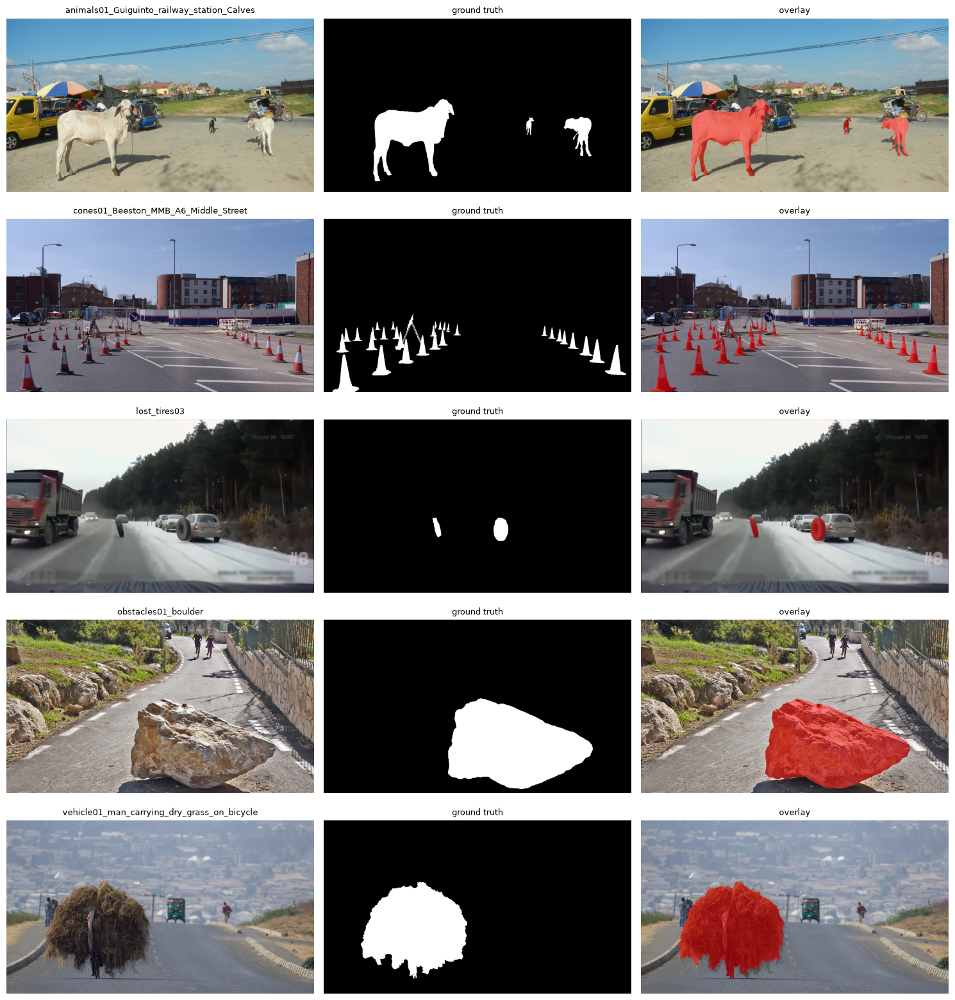

In [9]:
# Show image | mask | overlay for the first frame of each category
categories = sorted(files_df["category"].unique())
fig, ax = plt.subplots(len(categories), 3, figsize=(15, 3.2 * len(categories)), tight_layout=True)
for i, category in enumerate(categories):
    frame = files_df.loc[files_df["category"] == category, "frame"].iloc[0]
    image, mask = dp.load_frame(frame)
    overlay = image.copy()
    overlay[mask == 1] = (0.5 * overlay[mask == 1] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    for j, (panel, title) in enumerate([(image, frame), (mask, "ground truth"), (overlay, "overlay")]):
        ax[i, j].imshow(panel, cmap="gray" if panel.ndim == 2 else None)
        ax[i, j].set_title(title, fontsize=9)
        ax[i, j].axis("off")
plt.savefig(FIG_DIR / "01_examples_per_category.png", dpi=80)
plt.show()

### 5. Class imbalance (anomaly pixel ratio)
How many pixels of each image belong to the anomaly. This decides whether pixel accuracy or AUROC would be misleading.

In [10]:
# Load all binary masks at full resolution
masks_full = {frame: dp.load_frame(frame)[1] for frame in frames}
stats_df = files_df[["frame", "category"]].copy()
stats_df["anomaly_ratio"] = [masks_full[f].mean() for f in frames]
stats_df["has_anomaly"] = stats_df["anomaly_ratio"] > 0

total_ratio = np.sum([m.sum() for m in masks_full.values()]) / np.sum([m.size for m in masks_full.values()])
print("Images with at least one anomaly pixel:", stats_df["has_anomaly"].sum(), "/", len(stats_df))
print(f"Anomaly pixels over the whole dataset : {100 * total_ratio:.2f} %")
print(f"Accuracy of a model that predicts 'all background': {100 * (1 - total_ratio):.2f} %")
print()
print(stats_df["anomaly_ratio"].describe(percentiles=[.1, .25, .5, .75, .9]).apply(lambda v: f"{v:.4f}").to_string())

Images with at least one anomaly pixel: 60 / 60
Anomaly pixels over the whole dataset : 9.85 %
Accuracy of a model that predicts 'all background': 90.15 %

count    60.0000
mean      0.0985
std       0.1006
min       0.0037
10%       0.0109
25%       0.0180
50%       0.0662
75%       0.1380
90%       0.2351
max       0.4233


In [11]:
# Anomaly ratio per category
print(stats_df.groupby("category")["anomaly_ratio"].agg(["count", "mean", "median", "min", "max"]).round(4).to_string())

            count    mean  median     min     max
category                                         
animals        31  0.1267  0.0820  0.0080  0.4233
cones           8  0.0288  0.0172  0.0110  0.0656
lost_tires      3  0.0069  0.0070  0.0037  0.0099
obstacles      15  0.0950  0.0631  0.0063  0.2468
vehicle         3  0.1020  0.0997  0.0768  0.1295


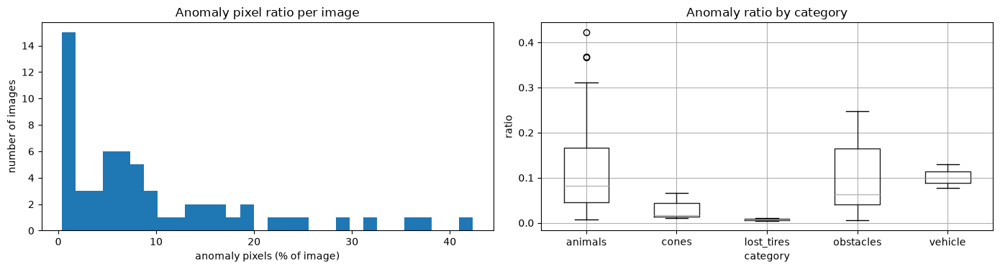

In [12]:
# Histogram of the anomaly ratio per image
fig, ax = plt.subplots(1, 2, figsize=(14, 4), tight_layout=True)
ax[0].hist(100 * stats_df["anomaly_ratio"], bins=30)
ax[0].set_xlabel("anomaly pixels (% of image)")
ax[0].set_ylabel("number of images")
ax[0].set_title("Anomaly pixel ratio per image")
stats_df.boxplot(column="anomaly_ratio", by="category", ax=ax[1])
ax[1].set_title("Anomaly ratio by category")
ax[1].set_ylabel("ratio")
plt.suptitle("")
plt.savefig(FIG_DIR / "02_anomaly_ratio.png", dpi=80)
plt.show()

### 6. Object level: how many obstacles, how big, where
Each 8-connected component of the binary mask is a candidate obstacle. Before counting obstacles we must check whether every component really is one.

In [13]:
# Connected components of every mask (full resolution 1280x720)
H, W = next(iter(masks_full.values())).shape
component_rows = []
for frame in frames:
    labeled, n = ndimage.label(masks_full[frame], structure=np.ones((3, 3)))
    for k, sl in enumerate(ndimage.find_objects(labeled), start=1):
        comp = labeled[sl] == k
        ys, xs = np.nonzero(comp)
        component_rows.append({
            "frame": frame,
            "category": dp.category_of(frame),
            "label_id": k,
            "area_px": int(comp.sum()),
            "bbox_h": sl[0].stop - sl[0].start,
            "bbox_w": sl[1].stop - sl[1].start,
            "centroid_y": (sl[0].start + ys.mean()) / H,   # 0 = top of the image, 1 = bottom
            "centroid_x": (sl[1].start + xs.mean()) / W,
        })
comp_df = pd.DataFrame(component_rows)
print("Total components:", len(comp_df))
print(comp_df["area_px"].describe(percentiles=[.1, .25, .5, .75, .9]).round(0).to_string())

Total components: 298
count       298.0
mean      18277.0
std       50722.0
min           1.0
10%           1.0
25%          45.0
50%         427.0
75%        8630.0
90%       48031.0
max      390065.0


The 10th percentile of the component area is a handful of pixels: some components are far too small to be obstacles. The histogram of log-areas below shows whether they form a separate population.

        1 -         2 px : ###################################### 38
        2 -         3 px : ############### 15
        3 -         6 px : ### 3
        6 -        10 px : ## 2
       10 -        18 px : ## 2
       18 -        32 px : ###### 6
       32 -        56 px : ################ 16
       56 -       100 px : ####################### 23
      100 -       178 px : ################### 19
      178 -       316 px : ################# 17
      316 -       562 px : #################### 20
      562 -      1000 px : ################ 16
     1000 -      1778 px : ############### 15
     1778 -      3162 px : ############ 12
     3162 -      5623 px : ########### 11
     5623 -     10000 px : ################# 17
    10000 -     17783 px : ################ 16
    17783 -     31623 px : ########## 10
    31623 -     56234 px : ############## 14
    56234 -    100000 px : ######## 8
   100000 -    177828 px : ######### 9
   177828 -    316228 px : ####### 7
   316228 -    562341 px : ##

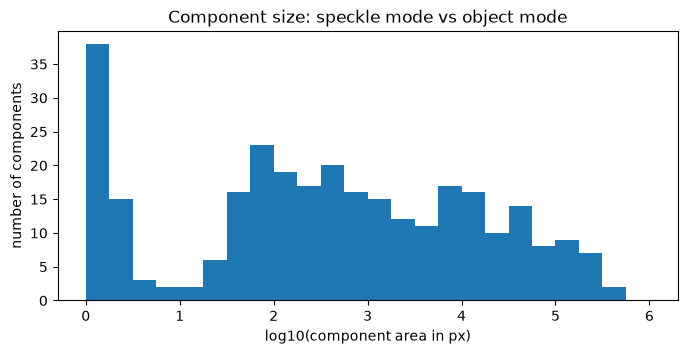

In [14]:
# Histogram of component sizes on a log scale
log_area = np.log10(comp_df["area_px"])
bins = np.arange(0, 6.25, 0.25)
counts, edges = np.histogram(log_area, bins=bins)
for c, e in zip(counts, edges, strict=False):
    print(f"{10**e:>9.0f} - {10**(e + 0.25):>9.0f} px : {'#' * c} {c}")

plt.figure(figsize=(8, 3.5))
plt.hist(log_area, bins=bins)
plt.xlabel("log10(component area in px)")
plt.ylabel("number of components")
plt.title("Component size: speckle mode vs object mode")
plt.savefig(FIG_DIR / "03_component_size_hist.png", dpi=80)
plt.show()

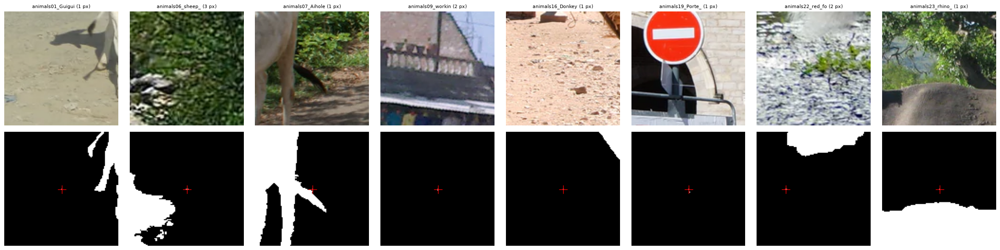

In [15]:
# Look at the tiny components in the image: are they obstacles or annotation noise?
tiny = comp_df[comp_df["area_px"] <= 16].groupby("frame").head(1).head(8)
fig, ax = plt.subplots(2, len(tiny), figsize=(3 * len(tiny), 6), tight_layout=True)
for i, row in enumerate(tiny.itertuples()):
    image, mask = dp.load_frame(row.frame)
    cy, cx = int(row.centroid_y * H), int(row.centroid_x * W)
    y0, x0 = max(cy - 60, 0), max(cx - 60, 0)
    ax[0, i].imshow(image[y0:y0 + 120, x0:x0 + 120])
    ax[0, i].set_title(f"{row.frame[:16]} ({row.area_px} px)", fontsize=8)
    ax[1, i].imshow(mask[y0:y0 + 120, x0:x0 + 120], cmap="gray")
    ax[1, i].plot(cx - x0, cy - y0, "r+", ms=14)
    ax[0, i].axis("off")
    ax[1, i].axis("off")
plt.savefig(FIG_DIR / "04_annotation_speckle.png", dpi=70)
plt.show()

In [16]:
# Threshold placed in the empty valley of the histogram, between the two modes
MIN_OBJECT_PX = 16   # at 1280x720

comp_df["is_object"] = comp_df["area_px"] >= MIN_OBJECT_PX
speckle = comp_df[~comp_df["is_object"]]
total_anomaly_px = comp_df["area_px"].sum()
print(
    f"Speckle components (< {MIN_OBJECT_PX} px): {len(speckle)} "
    f"({100 * len(speckle) / len(comp_df):.1f} % of components)"
    f" in {speckle['frame'].nunique()} images, holding "
    f"{100 * speckle['area_px'].sum() / total_anomaly_px:.4f} % of the anomaly pixels"
)
objects_df = comp_df[comp_df["is_object"]].copy()
print("Real objects:", len(objects_df))

Speckle components (< 16 px): 59 (19.8 % of components) in 16 images, holding 0.0021 % of the anomaly pixels
Real objects: 239


**Decision:** the ground truth is **not modified** (speckle is a negligible share of the pixels, so pixel metrics do not change). For everything that counts *objects* (statistics below, object-level metrics, boundary metrics) components smaller than `MIN_OBJECT_PX` are ignored.

In [17]:
# Objects per image and object sizes (speckle excluded)
stats_df["n_objects"] = stats_df["frame"].map(objects_df.groupby("frame").size()).fillna(0).astype(int)
print("Objects per image:", sorted(Counter(stats_df["n_objects"]).items()))
print(f"Images with more than one object: {(stats_df['n_objects'] > 1).sum()} / {len(stats_df)}")
print()
print("Object area (px at 1280x720):")
print(objects_df["area_px"].describe(percentiles=[.1, .25, .5, .75, .9]).round(0).to_string())
for limit in [100, 1000, 10000]:
    print(
        f"objects smaller than {limit:>6} px ({100 * limit / (H * W):.3f} % of the image): "
        f"{100 * (objects_df['area_px'] < limit).mean():5.1f} %"
    )
print()
largest_share = objects_df.groupby("frame")["area_px"].agg(lambda a: a.max() / a.sum())
print(f"In multi-object images, the largest object holds on average "
      f"{100 * largest_share[stats_df.set_index('frame')['n_objects'] > 1].mean():.1f} % of the anomaly pixels")

Objects per image: [(1, 24), (2, 13), (3, 8), (4, 3), (5, 2), (6, 1), (7, 1), (8, 2), (10, 1), (12, 1), (18, 1), (20, 1), (22, 1), (32, 1)]
Images with more than one object: 36 / 60

Object area (px at 1280x720):
count       239.0
mean      22788.0
std       55743.0
min          16.0
10%          60.0
25%         166.0
50%        1112.0
75%       12970.0
90%       66853.0
max      390065.0
objects smaller than    100 px (0.011 % of the image):  19.2 %
objects smaller than   1000 px (0.109 % of the image):  49.4 %
objects smaller than  10000 px (1.085 % of the image):  72.4 %

In multi-object images, the largest object holds on average 68.0 % of the anomaly pixels


In [18]:
# Annotated instances (labels_instance.png, 46 frames) vs objects found as components
rows = []
for frame in frames:
    path = FRAMES_DIR / f"{frame}.labels" / "labels_instance.png"
    if path.exists():
        inst = np.array(Image.open(path))
        rows.append({"frame": frame, "instances": len(np.unique(inst[inst > 0])),
                     "objects": int(stats_df.loc[stats_df["frame"] == frame, "n_objects"].iloc[0])})
inst_df = pd.DataFrame(rows)
print("Instances == objects:", (inst_df["instances"] == inst_df["objects"]).sum(), "/", len(inst_df))
print(
    "Instances >  objects (touching instances merge into one component):",
    (inst_df["instances"] > inst_df["objects"]).sum(),
)
print("Instances <  objects (one instance split into pieces):", (inst_df["instances"] < inst_df["objects"]).sum())

Instances == objects: 26 / 46
Instances >  objects (touching instances merge into one component): 13
Instances <  objects (one instance split into pieces): 7


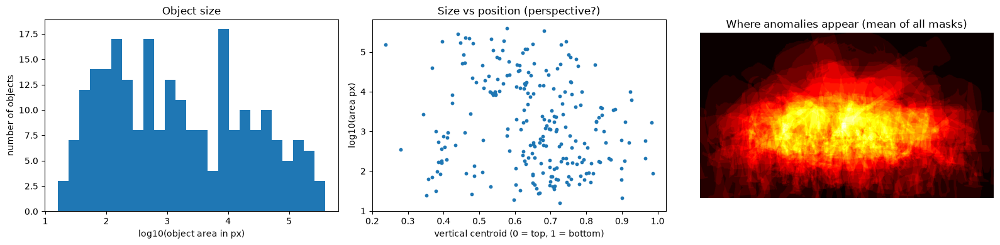

Correlation between vertical position and log-area: -0.183
Vertical centroid of objects: median 0.66 | share in the top third of the image: 0.008


In [19]:
# Size and vertical position of the objects
fig, ax = plt.subplots(1, 3, figsize=(16, 4), tight_layout=True)
ax[0].hist(np.log10(objects_df["area_px"]), bins=25)
ax[0].set_xlabel("log10(object area in px)")
ax[0].set_ylabel("number of objects")
ax[0].set_title("Object size")
ax[1].scatter(objects_df["centroid_y"], np.log10(objects_df["area_px"]), s=10)
ax[1].set_xlabel("vertical centroid (0 = top, 1 = bottom)")
ax[1].set_ylabel("log10(area px)")
ax[1].set_title("Size vs position (perspective?)")
heat = np.mean(np.stack(list(masks_full.values())), axis=0)
ax[2].imshow(heat, cmap="hot")
ax[2].set_title("Where anomalies appear (mean of all masks)")
ax[2].axis("off")
plt.savefig(FIG_DIR / "05_objects.png", dpi=80)
plt.show()
print("Correlation between vertical position and log-area:",
      round(np.corrcoef(objects_df["centroid_y"], np.log10(objects_df["area_px"]))[0, 1], 3))
print("Vertical centroid of objects: median", round(objects_df["centroid_y"].median(), 2),
      "| share in the top third of the image:", round((objects_df["centroid_y"] < 1 / 3).mean(), 3))

### 7. Resolution study
Training at 1280x720 does not fit the 6 GB RTX 2060 for most models, so the images must be downscaled, and downscaling erases small obstacles. For each candidate size (all keep the 16:9 aspect ratio, so obstacles are not distorted) we count how many **real objects** keep a usable number of pixels.

In [20]:
# Pixels left for each real object after nearest-neighbour downscaling
CANDIDATE_SIZES = [(720, 1280), (448, 800), (360, 640), (352, 640), (288, 512), (216, 384)]   # (height, width)
MIN_USABLE_PX = 16   # below ~4x4 px an object is hard to segment

rows = []
for size in CANDIDATE_SIZES:
    lost, too_small = 0, 0
    for frame in frames:
        labeled, _ = ndimage.label(masks_full[frame], structure=np.ones((3, 3)))
        small = np.array(Image.fromarray(labeled.astype(np.int32)).resize(size[::-1], Image.NEAREST))
        for k in objects_df.loc[objects_df["frame"] == frame, "label_id"]:
            remaining = int((small == k).sum())
            lost += remaining == 0
            too_small += remaining < MIN_USABLE_PX
    rows.append({"size (HxW)": f"{size[0]}x{size[1]}",
                 "objects lost": lost,
                 f"objects < {MIN_USABLE_PX} px": too_small,
                 "% objects usable": round(100 * (1 - too_small / len(objects_df)), 1),
                 "sides divisible by 32": size[0] % 32 == 0 and size[1] % 32 == 0,
                 "aspect distortion %": round(100 * abs(size[1] / size[0] / (W / H) - 1), 1),
                 "input MB / image": round(size[0] * size[1] * 4 * 4 / 1e6, 1)})
resolution_df = pd.DataFrame(rows)
resolution_df

,size (HxW),objects lost,objects < 16 px,% objects usable,sides divisible by 32,aspect distortion %,input MB / image
0,720x1280,0,0,100.0,False,0.0,14.7
1,448x800,0,13,94.6,True,0.4,5.7
2,360x640,0,26,89.1,False,0.0,3.7
3,352x640,0,25,89.5,True,2.3,3.6
4,288x512,0,41,82.8,True,0.0,2.4
5,216x384,0,60,74.9,False,0.0,1.3


In [21]:
# Working resolution chosen from the table above (justification in the markdown below)
IMG_SIZE = (352, 640)   # (height, width)
scale = IMG_SIZE[0] / H
# Speckle threshold at the working resolution (areas scale with the square of the side)
MIN_OBJECT_PX_WORK = max(1, int(round(MIN_OBJECT_PX * scale ** 2)))
print("IMG_SIZE:", IMG_SIZE, "| MIN_OBJECT_PX at this size:", MIN_OBJECT_PX_WORK)

IMG_SIZE: (352, 640) | MIN_OBJECT_PX at this size: 4


**Why `IMG_SIZE = (352, 640)`** (decided from the table above and a GPU memory test):

- **Object survival:** 352x640 keeps **89.5 %** of the real objects above 16 px. 288x512 keeps only 82.8 %, and 448x800 keeps 94.6 %.
- **Architecture:** U-Net and DeepLabV3+ downsample by 32, so each side must be divisible by 32. 360x640 is not (360 / 32 = 11.25). 352x640 is, at the cost of a 2.3 % horizontal stretch.
- **Memory on the smallest team GPU** (RTX 2060, 6 GB). Measured with `scripts/gpu_memory_check.py`, mixed precision, GPU capped at 5.5 GB:

| Model (stand-in) | 352x640 | 448x800 |
|---|---|---|
| U-Net (32 → 512 filters) | batch 8: OK, about 3.3 GB | batch 8: OK, about 4.0 GB |
| DeepLabV3+ (ResNet50) | **batch 4: OK, about 4.5 GB** (batch 8 runs out of memory) | batch 4 runs out of memory; batch 2 fits |

448x800 would force DeepLabV3+ down to batch 2, which is too small for stable BatchNorm statistics while fine-tuning. **352x640 is the largest size where all three approaches train with batch ≥ 4 on both GPUs.**

These numbers were measured with the GPU memory capped at 5.5 GB; they can be confirmed on the RTX 2060 itself with `python scripts/gpu_memory_check.py deeplab 352 640 4`. The batch sizes finally used by each model are listed in notebook 3, section 7.

### 8. Scenes that belong together (leakage check)
If two photos of the same scene end up in train and test, the test score is inflated.

A first attempt used a global average hash of the images. It failed on this dataset: `lost_tires08` and `lost_tires09` are consecutive frames of the same dash-cam video but are further apart in hash distance than unrelated photos (see below). The reliable source is `credits.txt`: frames listed under the **same source block or the same URL** come from the same video, photographer or article.

In [22]:
# Evidence that a global image hash does not find these duplicates
def average_hash(frame, size=16):
    thumb = np.array(
        Image.open(FRAMES_DIR / f"{frame}.webp").convert("L").resize((size, size), Image.BILINEAR), dtype=float
    )
    return (thumb > thumb.mean()).flatten()

hashes = {f: average_hash(f) for f in frames}
def dist(a, b):
    return int((hashes[a] != hashes[b]).sum())
print("Same video     lost_tires08 vs lost_tires09:", dist("lost_tires08", "lost_tires09"), "/ 256 bits")
print("Unrelated photos animals11 vs animals17     :",
      dist("animals11_Cock_Pheasant_on_Romford_Road", "animals17_E6_near_Kvaenangen"), "/ 256 bits")

Same video     lost_tires08 vs lost_tires09: 41 / 256 bits
Unrelated photos animals11 vs animals17     : 28 / 256 bits


In [23]:
# Scene groups from credits.txt: frames in the same source block, or sharing a source URL, form one group
# (union-find in roadanomaly.splitting.scene_groups, also used by notebook 3 to rebuild the split)
from roadanomaly.splitting import scene_groups

stats_df["scene_group"] = stats_df["frame"].map(scene_groups(frames, DATA_DIR / "credits.txt"))
groups = stats_df.groupby("scene_group")["frame"].apply(list)
print("Scene groups:", len(groups), "for", len(frames), "frames")
for members in groups:
    if len(members) > 1:
        print(f"  {len(members)} frames: {members}")

Scene groups: 51 for 60 frames
  2 frames: ['cones07', 'cones08_can']
  3 frames: ['lost_tires03', 'lost_tires08', 'lost_tires09']
  4 frames: ['obstacles03_cardboard_czech_hedgehog', 'obstacles04_cardboard_czech_hedgehog', 'obstacles05_cardboard_czech_hedgehog', 'obstacles06_cardboard_czech_hedgehog']
  4 frames: ['obstacles12_rocks2', 'obstacles12_rocks4', 'obstacles12_rocks5', 'obstacles12_rocks6']


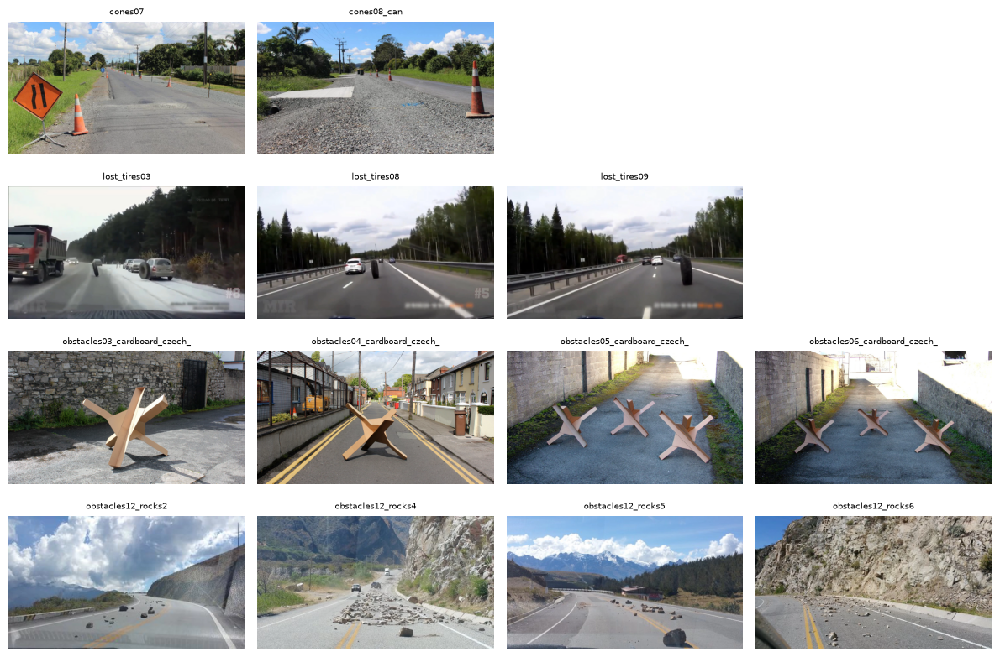

In [24]:
# Show every multi-frame group to check visually that they share scene or object
multi = [m for m in groups if len(m) > 1]
cols = max(len(m) for m in multi)
fig, ax = plt.subplots(len(multi), cols, figsize=(3 * cols, 2 * len(multi)), squeeze=False, tight_layout=True)
for i, members in enumerate(multi):
    for j in range(cols):
        ax[i, j].axis("off")
        if j < len(members):
            ax[i, j].imshow(Image.open(FRAMES_DIR / f"{members[j]}.webp"))
            ax[i, j].set_title(members[j][:28], fontsize=7)
plt.savefig(FIG_DIR / "06_scene_groups.png", dpi=70)
plt.show()

### 9. Normal data for the Autoencoder (Binôme B)
FR's autoencoder must learn to reconstruct **normal** road scenes only. Section 5 showed that no image is anomaly-free, so the only in-dataset source of normal data is **background patches**. They are counted here on all 60 images at the working resolution, to choose a patch size; notebook 3 counts them again on the final **train** split only, the only images the autoencoder may learn from.

In [25]:
# Count anomaly-free patches (all images; notebook 3 recounts them on the train split only)
def count_normal_patches(frame_list, img_size, patch, stride):
    normal, total = 0, 0
    for frame in frame_list:
        small = np.array(Image.fromarray(masks_full[frame]).resize(img_size[::-1], Image.NEAREST))
        for y in range(0, small.shape[0] - patch + 1, stride):
            for x in range(0, small.shape[1] - patch + 1, stride):
                total += 1
                normal += small[y:y + patch, x:x + patch].max() == 0
    return normal, total

rows = []
for patch in [32, 64, 96, 128]:
    normal, total = count_normal_patches(frames, IMG_SIZE, patch, patch // 2)
    rows.append({"patch": f"{patch}x{patch}", "stride": patch // 2, "patches (all 60 images)": total,
                 "anomaly-free": normal, "% anomaly-free": round(100 * normal / total, 1)})
pd.DataFrame(rows)

,patch,stride,patches (all 60 images),anomaly-free,% anomaly-free
0,32x32,16,49140,39137,79.6
1,64x64,32,11400,7852,68.9
2,96x96,48,4320,2467,57.1
3,128x128,64,2160,1049,48.6


### 10. From insights to the evaluation protocol
Each decision below comes from a measurement in this notebook. Section numbers point to the evidence.

| # | Measured insight | Consequence | Decision |
|---|---|---|---|
| 1 | All 60 images contain an anomaly. Anomaly pixels are **9.85 %** of the dataset, so predicting "all background" scores **90.15 % pixel accuracy** (§5). | Accuracy rewards a model that detects nothing. | **Pixel accuracy is not used**, not even as a Keras training metric. |
| 2 | The anomaly ratio per image ranges from **0.37 % to 42.3 %**, a factor of about 115, with a median of 6.6 % (§5). | Pooled pixel counts are dominated by a few images with huge animals. | **Primary:** the FR floor metrics (Precision, Recall, F1, IoU, Dice) as the **mean over images**. The pooled ("aggregated") scores are reported as secondary. |
| 3 | Pixel prevalence on validation is **9.07 %** (notebook 3, §2). | For a score map, AUROC has a chance level of 0.5 whatever the imbalance, so it looks good too easily. AuPRC has a chance level equal to the prevalence. | Threshold-free score maps (autoencoder error maps, model probabilities): **AuPRC is the main ranking metric**. AUROC (an FR requirement for the AE) is reported next to it with its chance level. |
| 4 | **36 / 60** images contain several obstacles. Object sizes span 16 px to 390,065 px, and **49 %** of objects are under 1000 px. In multi-object images the largest object holds **68 %** of the anomaly pixels (§6). | A model can reach a good pixel IoU while missing most obstacles, i.e. the small ones. | **Object-level scores for all three approaches** (`metrics.object_scores`): object recall (an obstacle counts as found if ≥ 50 % of it is covered), object precision (predicted blobs that are false alarms) and object F1. |
| 5 | **59** components under 16 px (20 % of all components, **0.002 %** of anomaly pixels) are isolated annotation dots, not obstacles (§6, figure 04). | They would count as missed obstacles, and they pull boundary distances (HD95) towards stray pixels. | The ground truth is **not edited** (the effect on pixel metrics is negligible). Object and boundary metrics ignore components smaller than `MIN_OBJECT_PX`: 16 px at 1280x720, which is **4 px at 352x640**, applied with `metrics.remove_small_components`. |
| 6 | Instance labels exist for only 46 / 60 frames, and they disagree with the connected components in 20 of those 46 (§6). | Instance labels cannot define "an object" for the whole dataset. | An object is a **connected component** (8-connectivity). AUPRO and the object scores use these same components. |
| 7 | At 352x640, **10.5 %** of the objects keep fewer than 16 px (§7). | The smallest obstacles are the hardest case and must not be hidden in averages. | Report object recall **separately for small (< 1000 px at full resolution, half of all objects) and large objects**. |
| 8 | Validation and test have only **9 images each** (test: 22 objects, no lost-tyre scene) (notebook 3, §1). | A one-image change moves the mean by about 11 %. | Report every test mean with a **95 % bootstrap interval over images** (`metrics.bootstrap_ci`). Don't declare a winner when the intervals overlap. Per-image results are always shown. |
| 9 | No anomaly-free image exists, but **5,488 of 7,980** 64x64 patches of the **train split** contain no anomaly at 352x640 (5,325 once each obstacle is enlarged by the 4-px training margin) (§9; notebook 3, §3). | The autoencoder can learn "normal" from background patches of the training images, without external data. | Binôme B trains on anomaly-free train patches. External normal data is added only if needed and with authorization, as FR requires. For AUPRO, state the integration limit (FPR cap). |
| 10 | Objects show no perspective size trend (correlation −0.18), and almost none are in the top third of the image (**0.8 %**) (§6). | Perspective-aware tricks are not supported by this data. The location prior is strong. | No perspective correction. Augmentation uses horizontal flips only, never vertical, and crops of at least 80 %. Errors in the upper image are analysed separately. |

**Protocol summary, common to the three binômes**
1. Data: `splits/split_manifest.csv` (built and checked in notebook 3) with `IMG_SIZE = (352, 640)`, loaded through `roadanomaly.data_pipeline`. The **test split is used once**, for the final comparison.
2. Thresholds (score → mask), early stopping and model selection use **validation only**. The default threshold maximises the per-image mean F1 on validation.
3. Required for every approach:
   - pixel Precision, Recall, F1, IoU and Dice, as per-image mean and aggregated;
   - object recall, precision and F1, overall and split into small vs large objects;
   - 95 % bootstrap intervals on the test set;
   - the pixel confusion matrix.
4. For threshold-free score maps: AuPRC (main) and AUROC (with chance level).
5. Approach-specific metrics from FR are computed on speckle-filtered masks, with units in px at 352x640 and the band width or FPR cap stated:
   - HD95 for U-Net;
   - Boundary IoU and mIoU for DeepLabV3+, the latter only if multi-class labels exist, and here they do not: the labels are binary;
   - AUPRO for the AE.

   In the end the shared report (`roadanomaly.evaluation`) computes all three for every model, so that the approaches can be compared on each of them.
6. Log for every run: seed, `IMG_SIZE`, batch size, epochs, learning rate, GPU name and TensorFlow version.

The constants of this protocol are stored once in `src/roadanomaly/protocol.py` (`IMG_SIZE`, `MIN_OBJECT_PX`, `SMALL_OBJECT_PX`, `FPR_LIMIT`, bootstrap settings), and the full report is computed by `roadanomaly.evaluation` for every model, so the three binômes cannot drift apart.

In [26]:
# The protocol module must hold exactly the values measured in this notebook
from roadanomaly import protocol

assert protocol.IMG_SIZE == IMG_SIZE
assert protocol.MIN_OBJECT_PX_FULL == MIN_OBJECT_PX
assert protocol.MIN_OBJECT_PX == MIN_OBJECT_PX_WORK
print({k: getattr(protocol, k) for k in ["SEED", "IMG_SIZE", "MIN_OBJECT_PX", "SMALL_OBJECT_PX", "FPR_LIMIT"]})

{'SEED': 1337, 'IMG_SIZE': (352, 640), 'MIN_OBJECT_PX': 4, 'SMALL_OBJECT_PX': 239, 'FPR_LIMIT': 0.3}


### 11. What this dataset supports and its limitations

| The data supports | The data does not establish |
|---|---|
| Comparing methods for **binary pixel-level anomaly segmentation** on the 60 provided images. | Multi-class pixel segmentation of animals, cones, rocks, or other anomaly categories: masks only label background vs. anomaly. |
| Analysis of image/mask resolution, anomaly-pixel imbalance, obstacle sizes, and grouped train/validation/test evaluation. | Robustness across lighting, weather, road types, or other environmental conditions. These attributes are not systematically recorded or evaluated here. |
| A controlled comparison using the shared split and validation-only model selection. | Reliable real-world performance estimates: the dataset and validation/test splits are small, so results are uncertain and may not generalize. |

The dataset occupies **about 12.53 MiB** in this repository (the notebook computes the current value at runtime). All 60 image/mask pairs were readable in the current local copy. Re-run the integrity cell if the data files change.


In [ ]:
# End of 2 · Data Understanding: clean up before the next phase (cell added by scripts/build_master_notebook.py).
# The namespace and the Keras session are cleared, so the next phase starts as in its own kernel. TensorFlow
# settings of the process (GPU memory configuration, deterministic GPU kernels) stay for the whole kernel.
%reset -f
import gc

import keras

keras.backend.clear_session()
gc.collect()

# 3 · Data Preparation — shared split, loader and conventions

**CRISP-DM phase 3.**

What this notebook prepares for the three binômes:
1. **The frozen train / validation / test split** (`splits/split_manifest.csv`). It is **checked, never rewritten**: the documented procedure is run again and must give back exactly the same split.
2. **Split statistics** and the normal data available to the autoencoder in the train split.
3. **The shared DataLoader** (`roadanomaly.data_pipeline`): resizing, mask convention, augmentation.
4. **Normalisation conventions** and what each binôme reuses.

The test split is never loaded here: only its file names and statistics from the full-resolution masks are used, as when the split was made.

### TL;DR — one sealed envelope, one loader, one floor

Think of a fair exam: everyone sits it on the same day, with the same paper, and nobody sees the questions in advance. This notebook builds that fairness for the three binômes.

- **The sealed envelope (§1).** The 60 photographs are split 42 train / 9 validation / 9 test. The split is rebuilt from the raw files on every run (the best of 500 seeded candidates) and must come out **identical** to `splits/split_manifest.csv`, or the notebook stops. The test photographs are never loaded here; they are opened once, in notebook 5.
- **Same difficulty in every split (§2).** Each split keeps a median of about 7 % obstacle pixels. The test split holds **22 obstacles** and no lost-tyre scene; validation holds 37 (36 once resized to 352×640, where one of them falls under the 4-px speckle limit).
- **One loader for everyone (§4).** Images in [0, 1] at 352×640, binary masks, and the same training augmentation (horizontal flip, crop of at least 80 %, brightness and contrast). If two models differ, it is because of the model, not the data feeding.
- **The floor (§6).** Flagging every pixel as obstacle scores F1 **0.159** on validation, and a random score map scores AuPRC **0.0907**. A model is only interesting above these numbers.
- **Normal data for the autoencoders (§3).** 5,325 obstacle-free 64×64 tiles in the training photos, counted with the same code the autoencoders use.

### 0. Setup

In [1]:
# Import libraries
import os

# hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

import keras
import tensorflow as tf

tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

import warnings

from roadanomaly import data_pipeline as dp
from roadanomaly import evaluation, splitting
from roadanomaly.gpu import setup_gpu
from roadanomaly.normal_regions import MASK_MARGIN, normal_patches
from roadanomaly.protocol import IMG_SIZE, SEED

warnings.filterwarnings('ignore')

FIG_DIR = dp.FIG_DIR
keras.utils.set_random_seed(SEED)
GPU_NAME = setup_gpu()
print("TensorFlow:", tf.__version__, "| IMG_SIZE:", IMG_SIZE)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)
TensorFlow: 2.20.0 | IMG_SIZE: (352, 640)


### 1. The frozen split: rebuild it and check it
How the split is made (`roadanomaly.splitting`):
- **Group-aware:** a scene group (notebook 2, section 8) never spans two splits.
- **Stratified by category:** validation and test get at least one image of every category that has enough independent groups.
- Target about 70 / 15 / 15: with 60 images this leaves 9 images each for validation and test.
- **Representative:** 500 seeded candidate splits are generated, and the one whose validation and test sets are closest to the whole dataset (anomaly ratio and number of objects per image) is kept.
- **The test split is frozen:** it is used once, in notebook 5, for the final comparison of the three approaches. Thresholds, early stopping and model selection use validation only.

The cell below runs this procedure again from the raw data and **asserts that it gives the saved manifest exactly**. Nothing is written: the manifest is the reference of the whole project.

In [2]:
# Rebuild the split from the raw data with the documented procedure
stats_df = splitting.frame_statistics()
stats_df["scene_group"] = stats_df["frame"].map(
    splitting.scene_groups(stats_df["frame"].tolist(), dp.DATA_DIR / "credits.txt"))
rebuilt, best_seed, best_distance = splitting.best_split(stats_df)
print(f"Best of {len(splitting.SPLIT_SEEDS)} candidate splits: seed {best_seed}, distance {best_distance:.3f}")

# The saved manifest: sizes, unique frames, no scene group in two splits
manifest = splitting.verify_manifest().set_index("frame")
same = (rebuilt.values == manifest.loc[stats_df["frame"], "split"].values)
assert same.all(), f"the procedure does not give the saved manifest for {list(stats_df['frame'][~same])}"
stats_df["split"] = rebuilt.values
print("The rebuilt split is identical to splits/split_manifest.csv (60 / 60 frames)")
print(stats_df["split"].value_counts().to_string())

Best of 500 candidate splits: seed 415, distance 0.340
The rebuilt split is identical to splits/split_manifest.csv (60 / 60 frames)
split
train    42
val       9
test      9


### 2. Statistics per split

In [3]:
# Statistics per split: categories, anomaly ratio, number of objects
print(pd.crosstab(stats_df["category"], stats_df["split"]).to_string())
print()
summary = stats_df.groupby("split").agg(images=("frame", "count"),
                                        median_anomaly_ratio=("anomaly_ratio", "median"),
                                        min_anomaly_ratio=("anomaly_ratio", "min"),
                                        max_anomaly_ratio=("anomaly_ratio", "max"),
                                        mean_objects=("n_objects", "mean"),
                                        objects=("n_objects", "sum"))
print(summary.round(4).to_string())
print("\nWhole dataset: median anomaly ratio", round(stats_df["anomaly_ratio"].median(), 4),
      "| mean objects per image", round(stats_df["n_objects"].mean(), 2))

split       test  train  val
category                    
animals        5     21    5
cones          1      6    1
lost_tires     0      3    0
obstacles      2     11    2
vehicle        1      1    1

       images  median_anomaly_ratio  min_anomaly_ratio  max_anomaly_ratio  mean_objects  objects
split                                                                                           
test        9                0.0703             0.0162             0.1905        2.4444       22
train      42                0.0644             0.0037             0.4233        4.2857      180
val         9                0.0664             0.0135             0.2468        4.1111       37

Whole dataset: median anomaly ratio 0.0662 | mean objects per image 3.98


### 3. Normal data for the autoencoder (train split only)
Binôme B learns "normal road" from the background of the **train** images only. Two counts: without margin (pure anomaly-free patches) and with the `MASK_MARGIN` used in training (each obstacle dilated by a few pixels, because annotation borders are loose). `roadanomaly.normal_regions` is the code used by the autoencoders themselves.

In [4]:
# Anomaly-free patches available for the autoencoder in the final TRAIN split only
_, x_train, y_train = dp.load_split("train", IMG_SIZE)
rows = []
for patch in [64, 128]:
    for margin in [0, MASK_MARGIN]:
        patches, total = normal_patches(x_train, y_train, patch=patch, stride=patch // 2, margin=margin)
        rows.append({"patch": f"{patch}x{patch}", "stride": patch // 2, "obstacle margin (px)": margin,
                     "candidates": total, "normal": len(patches), "% normal": round(100 * len(patches) / total, 1)})
pd.DataFrame(rows)

,patch,stride,obstacle margin (px),candidates,normal,% normal
0,64x64,32,0,7980,5488,68.8
1,64x64,32,4,7980,5325,66.7
2,128x128,64,0,1512,740,48.9
3,128x128,64,4,1512,715,47.3


### 4. Shared DataLoader
`roadanomaly.data_pipeline` loads each split into memory (60 images), resizes the image (bilinear) and the mask (nearest, so it stays binary) to `IMG_SIZE`, and builds a `tf.data` pipeline. Only training batches are augmented, and the geometric part of the augmentation (horizontal flip, random crop of at least 80 %) is applied to the image and the mask together. Brightness and contrast jitter touch the image only. There is no vertical flip: the road is always at the bottom (notebook 2, section 6).

In [5]:
# Load the splits at the working resolution
BATCH_SIZE = 8

val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)
print("x_train:", x_train.shape, x_train.dtype, "range", (float(x_train.min()), float(x_train.max())))
print("y_train:", y_train.shape, y_train.dtype, "values", np.unique(y_train))
print("x_val  :", x_val.shape)
print("y_val  :", y_val.shape)

train_dataset = dp.get_dataset(x_train, y_train, BATCH_SIZE, training=True, seed=SEED)
valid_dataset = dp.get_dataset(x_val, y_val, BATCH_SIZE)

x_train: (42, 352, 640, 3) float32 range (0.0, 1.0)
y_train: (42, 352, 640, 1) float32 values [0. 1.]
x_val  : (9, 352, 640, 3)
y_val  : (9, 352, 640, 1)


I0000 00:00:1793563077.344705 2498021 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6249 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


batch images: (8, 352, 640, 3) | batch masks: (8, 352, 640, 1) | mask values: [0. 1.]


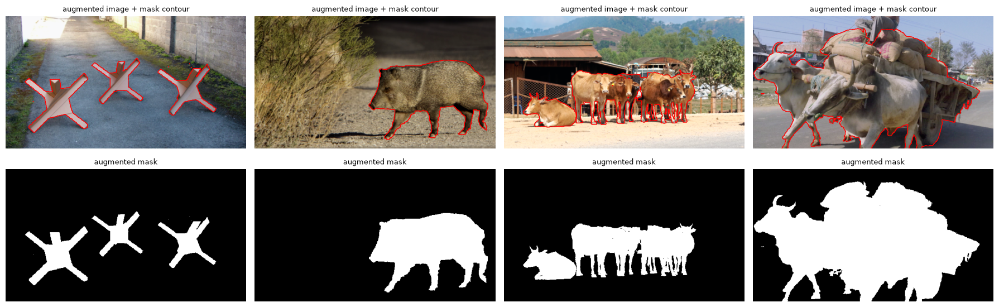

Input batch in memory: 29 MB (the rest of the 6 GB budget is for the model and its activations)


In [6]:
# One augmented training batch: the mask contour must sit on the object after augmentation
images, masks = next(iter(train_dataset))
print("batch images:", images.shape, "| batch masks:", masks.shape, "| mask values:", np.unique(masks.numpy()))
assert set(np.unique(masks.numpy())) <= {0.0, 1.0}

fig, ax = plt.subplots(2, 4, figsize=(18, 6), tight_layout=True)
for i in range(4):
    ax[0, i].imshow(images[i])
    ax[0, i].contour(masks[i, ..., 0], levels=[0.5], colors="red", linewidths=1)
    ax[0, i].set_title("augmented image + mask contour", fontsize=9)
    ax[1, i].imshow(masks[i, ..., 0], cmap="gray")
    ax[1, i].set_title("augmented mask", fontsize=9)
    ax[0, i].axis("off")
    ax[1, i].axis("off")
plt.savefig(FIG_DIR / "07_augmented_batch.png", dpi=70)
plt.show()

batch_mb = BATCH_SIZE * IMG_SIZE[0] * IMG_SIZE[1] * 4 * 4 / 1e6
print(f"Input batch in memory: {batch_mb:.0f} MB (the rest of the 6 GB budget is for the model and its activations)")

### 5. Normalisation conventions
| Stage | Convention | Where |
|---|---|---|
| Loader output | RGB float32 in **[0, 1]**, masks float32 {0, 1} of shape (H, W, 1) | `data_pipeline.load_split` |
| Pretrained backbones (A: ResNet50; B: VGG16, and VGG19 in the pixel AE's perceptual loss; C: ResNet50 of the pretrained U-Net) | each backbone's own `preprocess_input` on 0–255 images, applied **inside** the model, the loss or the feature extractor | `models/deeplabv3plus.py`, `models/feature_ae.py`, `models/unet.py` |
| Feature autoencoder (B) | per-channel z-score with the mean / std of the **train** normal cells only | `models/feature_ae.feature_statistics` |
| Score maps of autoencoders | Gaussian smoothing + per-image z-score, settings chosen on validation | `postprocessing.anomaly_scores` |

Every statistic is fitted on the train split; validation and test only reuse it.

### 6. The floor every model must beat
What trivial predictors score on the validation split, computed with the shared evaluation code. The metric functions themselves are checked against hand-computed cases in `tests/test_metrics_and_postprocessing.py` (`mise run test`).

In [7]:
# Trivial predictors on validation: per-image mean scores
_, x_val, y_val = dp.load_split("val", IMG_SIZE)
gt_val = y_val[..., 0].astype(bool)
print(pd.DataFrame(evaluation.trivial_baselines(gt_val)).T.round(3).to_string())
print(f"\nAuPRC chance level on val = anomaly pixel prevalence = {gt_val.mean():.4f} (AUROC chance is always 0.5)")

                precision  recall     f1    iou   dice
all background      0.000     0.0  0.000  0.000  0.000
all anomaly         0.091     1.0  0.159  0.091  0.159

AuPRC chance level on val = anomaly pixel prevalence = 0.0907 (AUROC chance is always 0.5)


### 7. What each binôme reuses
```python
from roadanomaly import data_pipeline as dp, evaluation, postprocessing
from roadanomaly.protocol import IMG_SIZE, SEED, MIN_OBJECT_PX
from roadanomaly.inference import save_artifact          # the shared model format (README, rule 2)
from roadanomaly.gpu import setup_gpu

setup_gpu(mixed_precision=True)     # float16 works on RTX 4060 and RTX 2060 (no bfloat16)
_, x_train, y_train = dp.load_split("train", IMG_SIZE)
_, x_val, y_val = dp.load_split("val", IMG_SIZE)          # the test split is loaded only in notebook 5
train_dataset = dp.get_dataset(x_train, y_train, BATCH_SIZE, training=True)
valid_dataset = dp.get_dataset(x_val, y_val, BATCH_SIZE)
# model.compile(..., jit_compile=False)  # TF 2.20 XLA fails with mixed precision on some graphs
```

| Binôme | Model | Training batch | Notes |
|---|---|---|---|
| A: Ines & Emna | DeepLabV3+ with transfer learning | 2 (Ines's setting; 4 fits in 6 GB) | Backbone `preprocess_input` **inside** the model (the loader returns [0, 1]). Binary labels, so mIoU reduces to 2 classes. Saves `models/A_deeplabv3plus/`. |
| B: Khaled & Adrian | Convolutional autoencoder (pixel baseline + feature-space AE) | 64 patches (pixel AE), 8 feature maps (feature AE) | Trains on normal regions of the **train** split (`normal_regions`). Error-map threshold on validation. AuPRC, AUROC and AUPRO. Saves `models/B_pixel_ae/` and `models/B_feature_ae/`. |
| C: Hejer & Walid | CNN baseline + U-Nets | 4 (CNN, U-Net), 8 (U-Net ResNet50, 4.6 GB peak) | ImageNet preprocessing **inside** the pretrained U-Net. HD95 on masks filtered with `remove_small_components`, in px at 352x640. Saves `models/C_cnn/`, `models/C_unet/` and `models/C_unet_resnet50/`. |

In [ ]:
# End of 3 · Data Preparation: clean up before the next phase (cell added by scripts/build_master_notebook.py).
# The namespace and the Keras session are cleared, so the next phase starts as in its own kernel. TensorFlow
# settings of the process (GPU memory configuration, deterministic GPU kernels) stay for the whole kernel.
%reset -f
import gc

import keras

keras.backend.clear_session()
gc.collect()

# 4 · Modeling — three binômes, six models

The three approaches use the same split, the same loader and the same protocol (phase 3), and every setting is chosen on the validation split only. Each part below is marked with its binôme, and the training code explains why each hyper-parameter was chosen.

| Binôme | Members | Approach | Saved models |
|---|---|---|---|
| A | Ines Trabelsi & Emna Trabelsi | DeepLabV3+ with transfer learning (frozen ImageNet ResNet50 encoder) | `A_deeplabv3plus` |
| B | Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono | convolutional autoencoders: a pixel autoencoder (baseline) and a feature-space autoencoder on frozen VGG16 features (final) | `B_pixel_ae`, `B_feature_ae` |
| C | Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets) | a CNN baseline, a U-Net from scratch and a U-Net with an ImageNet ResNet50 encoder | `C_cnn`, `C_unet`, `C_unet_resnet50` |

## 4 · Modeling — Binôme A: DeepLabV3+ with transfer learning

**CRISP-DM phase 4 (Modeling).** Team: Ines Trabelsi & Emna Trabelsi (FR, Binôme A).

Supervised binary segmentation of road anomalies: a **ResNet50 encoder pretrained on ImageNet** (frozen), an **ASPP** module and a **decoder** trained on RoadAnomaly. The model is defined in `src/roadanomaly/models/deeplabv3plus.py`.

**Protocol.** The checkpoint is chosen by the minimum validation loss, then the threshold by the per-image mean F1 on validation. This notebook never loads the test split: the single test evaluation is in notebook 5 and the explanations (Grad-CAM++ for *where*, exact SHAP for *what*, and the deletion / insertion check) in notebook 6.

**Provenance.** This notebook reproduces Ines's experiment `20261101T012507Z-f4ec27a0` with the same settings (batch 2, Adam 1e-3, binary cross-entropy, at most 20 epochs, patience 5, 51 threshold quantiles). Her original run (Windows, CPU, TensorFlow 2.21) is kept with its outputs in `archive/A_deeplabv3plus_original_run_ines.ipynb`: validation F1 0.680, AP 0.767, AUROC 0.940. The run below uses the team's reference environment (Linux, TensorFlow 2.20, GPU, deterministic ops), so its numbers differ slightly; the numbers reported for the group are those of this run.

> **Binôme A · Ines Trabelsi & Emna Trabelsi**  
> DeepLabV3+ with transfer learning (frozen ImageNet ResNet50 encoder). Saved models: `A_deeplabv3plus`.  
> Every code cell of this part starts with a comment naming the binôme.

#### TL;DR — borrow the eyes, train the brain

**The idea.** Recognising edges, fur, wheels and textures takes millions of photographs; we have 42. So Ines and Emna borrowed the "eyes" of a ResNet50 that has already looked at 1.2 million ImageNet photographs and kept them **frozen**, and trained only the "brain" on top: an atrous pyramid (ASPP, which looks at each spot through several window sizes at once, to see both the obstacle and its surroundings) and a decoder that draws the mask. Only 4.25 M of its 12.8 M weights are trained.

**What happened (validation only).**
- Trained 16 epochs; the best one (epoch 11) is chosen by validation loss, then the threshold **0.482** by the best mean F1 per photo.
- Validation AuPRC **0.754** (a blind guess scores 0.091), mean F1 **0.695**, outline quality (Boundary IoU) **0.476**.
- It finds the big obstacles well but **none of the 12 small ones** (0/12), and 42 of its 85 predicted blobs are false alarms.

**Takeaway.** Pretrained eyes make a strong detector out of 42 photographs. Its weak spots are small obstacles and scattered small false alarms, which notebook 5 confirms on the test split.

#### 0. Setup

In [1]:
# Binôme A · Ines Trabelsi & Emna Trabelsi
# Import libraries
import os

# hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

import keras
import tensorflow as tf

tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

import warnings

from roadanomaly import data_pipeline as dp
from roadanomaly import evaluation
from roadanomaly import postprocessing as pp
from roadanomaly.gpu import setup_gpu
from roadanomaly.inference import save_artifact
from roadanomaly.models.deeplabv3plus import build_deeplabv3plus
from roadanomaly.protocol import IMG_SIZE, MIN_OBJECT_PX, SEED

warnings.filterwarnings('ignore')

In [2]:
# Binôme A · Ines Trabelsi & Emna Trabelsi
# Hyper-parameters of Ines's experiment, kept unchanged so that this run reproduces her recipe (see "Provenance")
BATCH_SIZE = 2            # her setting: 21 steps per epoch over the 42 training photographs. A batch of 4 would also
                          # fit the 6 GB RTX 2060 (notebook 2, section 7); the recipe was kept as it was
LEARNING_RATE = 1e-3      # Adam's default step size; it only moves the new layers (the encoder is frozen)
MAX_EPOCHS = 20           # an upper bound only: early stopping on the validation loss decides when to stop
PATIENCE = 5              # stop after 5 epochs without a lower validation loss, keeping the best epoch's weights
DECODER_CHANNELS = 128    # width of every ASPP branch and decoder block: with the encoder frozen, these new layers
                          # hold the 4.25 M weights that are trained
THRESHOLD_QUANTILES = np.linspace(0.01, 0.99, 51)   # 51 candidate thresholds on the validation probabilities

FIG_DIR = dp.FIG_DIR
CHECKPOINT = dp.REPO_ROOT / "checkpoints" / "A_deeplabv3plus" / "best.keras"   # git-ignored
CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)

# Reproducibility: one seed for Python, NumPy and TensorFlow, and deterministic GPU kernels
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
GPU_NAME = setup_gpu()
print("TensorFlow:", tf.__version__, "| GPU:", GPU_NAME)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)
TensorFlow: 2.20.0 | GPU: NVIDIA GeForce RTX 4060 Laptop GPU


#### 1. Load and check the data
Images and masks come from the shared loader; masks are resized with nearest neighbour so they stay binary. Anomaly pixels are about 10 % of the images: the classes are imbalanced.

In [3]:
# Binôme A · Ines Trabelsi & Emna Trabelsi
train_frames, x_train, y_train = dp.load_split("train", IMG_SIZE)
val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)
assert len(train_frames) == 42 and len(val_frames) == 9 and set(train_frames).isdisjoint(val_frames)
for name, images, masks in [("train", x_train, y_train), ("validation", x_val, y_val)]:
    assert images.shape[1:] == (*IMG_SIZE, 3) and masks.shape == (*images.shape[:3], 1)
    assert np.isfinite(images).all() and images.min() >= 0 and images.max() <= 1 and np.isin(masks, [0, 1]).all()
    print(f"{name:10s}: {len(images)} images, anomaly pixels {masks.mean():.2%}")
gt_val = y_val[..., 0].astype(bool)

train     : 42 images, anomaly pixels 10.29%
validation: 9 images, anomaly pixels 9.07%


#### 2. Architecture
- **Encoder:** ResNet50 pretrained on ImageNet, **frozen** (its BatchNorm statistics are kept). Features are taken at 1/4 and 1/16 of the resolution; the ResNet50 preprocessing is inside the model.
- **ASPP:** a 1x1 branch, 3x3 branches with dilation 6, 12 and 18, and a global-context branch, concatenated and projected.
- **Decoder:** fusion of the ASPP output with the low-level features, two convolution blocks, upsampling to the input size.
- **Output:** a sigmoid, one anomaly probability per pixel. Adam (learning rate 0.001), binary cross-entropy, batch 2.

Only the encoder is pretrained; ASPP and decoder learn from the project's annotations. Training batches are augmented by the shared pipeline (horizontal flip, crop, brightness / contrast); validation is not.

In [4]:
# Binôme A · Ines Trabelsi & Emna Trabelsi
keras.utils.set_random_seed(SEED)   # same initial weights and data order on every run
# Transfer learning: the ResNet50 encoder keeps its ImageNet weights (frozen). 42 photographs are far too few to
# learn visual features from scratch, so only the ASPP (several fields of view) and the decoder are trained
model = build_deeplabv3plus(input_shape=(*IMG_SIZE, 3), weights="imagenet", decoder_channels=DECODER_CHANNELS)
# Binary cross-entropy: one yes / no decision per pixel (obstacle or background) on the sigmoid probability.
# jit_compile=False is the team convention (notebook 3, section 7): XLA in TensorFlow 2.20 fails on some graphs
model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=keras.losses.BinaryCrossentropy(),
              jit_compile=False)
# Training batches are shuffled and augmented (horizontal flip, crop of at least 80 %, brightness / contrast)
# by the shared loader; validation batches are never augmented
train_ds = dp.get_dataset(x_train, y_train, BATCH_SIZE, training=True, seed=SEED)
val_ds = dp.get_dataset(x_val, y_val, BATCH_SIZE)

sample = model(x_train[:1], training=False).numpy()
assert sample.shape == (1, *IMG_SIZE, 1) and np.isfinite(sample).all() and sample.min() >= 0 and sample.max() <= 1
print("input:", model.input_shape, "| output:", model.output_shape,
      "| encoder frozen:", not model.get_layer("resnet50_encoder").trainable,
      f"| trainable parameters: {sum(int(np.prod(w.shape)) for w in model.trainable_weights) / 1e6:.2f} M")

I0000 00:00:1793563083.856177 2500846 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6249 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


input: (None, 352, 640, 3) | output: (None, 352, 640, 1) | encoder frozen: True | trainable parameters: 4.25 M


#### 3. Training and checkpoint selection
The best checkpoint is chosen on `val_loss`; early stopping waits 5 epochs without improvement, with at most 20 epochs. The test split plays no part.

In [5]:
# Binôme A · Ines Trabelsi & Emna Trabelsi
callbacks = [
    # Save the weights of the epoch with the lowest validation loss (Ines's selection rule)
    keras.callbacks.ModelCheckpoint(str(CHECKPOINT), monitor="val_loss", mode="min", save_best_only=True),
    # Stop once the validation loss has not improved for PATIENCE epochs: with 42 training photographs the network
    # soon starts to memorise them (below: after epoch 11 the training loss keeps falling while the validation loss
    # no longer improves)
    keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=PATIENCE, restore_best_weights=True),
    keras.callbacks.TerminateOnNaN(),   # stop at once if the loss ever becomes NaN
]
# Training: at most MAX_EPOCHS passes over the 42 augmented training photographs, each followed by the validation
# loss on the 9 validation photographs. The test split is never used here (it is opened once, in notebook 5)
history = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, callbacks=callbacks, verbose=2).history
best_epoch = int(np.argmin(history["val_loss"])) + 1
model = keras.models.load_model(CHECKPOINT, compile=False)   # reload the best checkpoint explicitly
print(f"Stopped after {len(history['loss'])} epochs | best epoch {best_epoch} | "
      f"best validation loss {min(history['val_loss']):.4f}")

Epoch 1/20


21/21 - 6s - 307ms/step - loss: 0.4354 - val_loss: 2.4785


Epoch 2/20


21/21 - 1s - 49ms/step - loss: 0.1768 - val_loss: 3.0866


Epoch 3/20


21/21 - 1s - 64ms/step - loss: 0.1383 - val_loss: 1.0252


... (23 outputs left out)

21/21 - 1s - 48ms/step - loss: 0.0341 - val_loss: 0.1819


Epoch 16/20


21/21 - 1s - 48ms/step - loss: 0.0319 - val_loss: 0.1687


Stopped after 16 epochs | best epoch 11 | best validation loss 0.1683


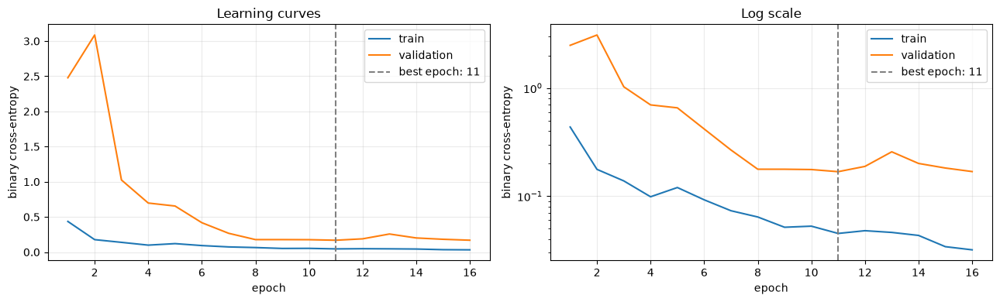

In [6]:
# Binôme A · Ines Trabelsi & Emna Trabelsi
# Learning curves (the log scale shows the small variations)
epochs = np.arange(1, len(history["loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4), tight_layout=True)
for a in ax:
    a.plot(epochs, history["loss"], label="train")
    a.plot(epochs, history["val_loss"], label="validation")
    a.axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch: {best_epoch}")
    a.set_xlabel("epoch")
    a.set_ylabel("binary cross-entropy")
    a.legend()
    a.grid(alpha=0.25)
ax[0].set_title("Learning curves")
ax[1].set_yscale("log")
ax[1].set_title("Log scale")
plt.savefig(FIG_DIR / "A_01_learning_curves.png", dpi=80)
plt.show()

#### 4. Threshold chosen on validation
The search compares 51 quantiles of the validation probabilities (0.01 to 0.99) and keeps the best per-image mean F1. Predicted components under `MIN_OBJECT_PX` (4 px, 8-connectivity) are removed, as for every model. The probabilities are used as they are: no smoothing and no per-image z-score.

In [7]:
# Binôme A · Ines Trabelsi & Emna Trabelsi
# From probabilities to a mask, with the shared rule: the threshold is the one of the 51 candidates that maximises
# the mean F1 per validation photograph, and predicted blobs smaller than MIN_OBJECT_PX (4 px) are removed
prob_val = model.predict(x_val, batch_size=BATCH_SIZE, verbose=0)[..., 0]
THRESHOLD, MIN_BLOB, best_f1, _ = pp.select_threshold(gt_val, prob_val, quantiles=THRESHOLD_QUANTILES,
                                                      min_blob_candidates=(MIN_OBJECT_PX,))
masks_val = pp.to_masks(prob_val, THRESHOLD, MIN_BLOB)
free_val = evaluation.threshold_free_scores(gt_val, prob_val)
report_val = evaluation.mask_report(gt_val, masks_val)
print(f"Threshold chosen on validation: {THRESHOLD:.6f} (per-image mean F1 {best_f1:.4f})")
pd.Series(evaluation.summary(free_val, report_val), name="validation").to_frame()

Threshold chosen on validation: 0.482264 (per-image mean F1 0.6950)


,validation
AuPRC (main),0.753624
AUROC,0.927511
AUPRO@0.3,0.825802
FPR95 (lower is better),0.437995
F1 = Dice (per-image mean),0.695027
IoU (per-image mean),0.57529
precision (per-image mean),0.735071
recall (per-image mean),0.792561
F1 (aggregated),0.691341
Boundary IoU (15 px band),0.47599


#### 5. Validation examples
Three fixed validation images (first, middle, last), not chosen by their scores. White: correctly detected; red: false alarm; blue: missed.

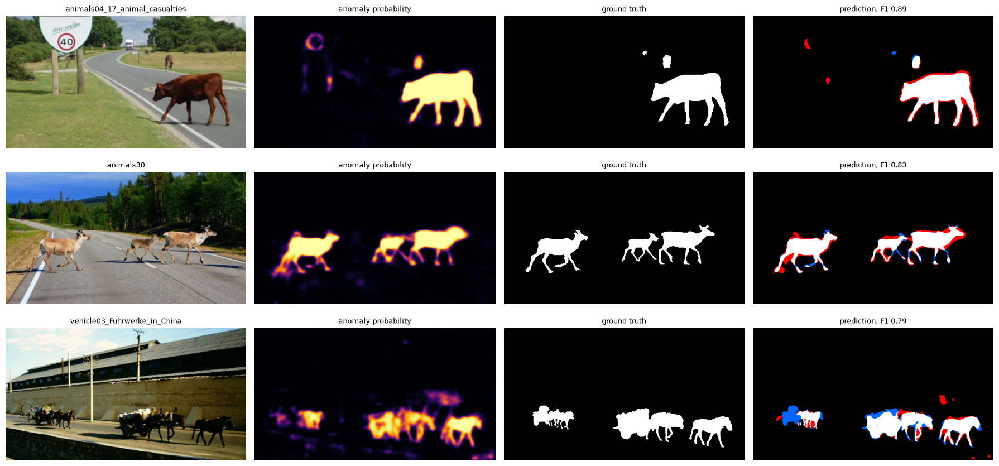

In [8]:
# Binôme A · Ines Trabelsi & Emna Trabelsi
def error_overlay(truth, pred):
    """RGB map: white = TP, red = FP, blue = FN, black = TN."""
    errors = np.zeros((*truth.shape, 3), np.float32)
    errors[truth & pred] = (1, 1, 1)
    errors[~truth & pred] = (1, 0, 0)
    errors[truth & ~pred] = (0, 0.4, 1)
    return errors

indices = [0, len(x_val) // 2, len(x_val) - 1]
fig, ax = plt.subplots(len(indices), 4, figsize=(18, 3 * len(indices)), tight_layout=True)
for row, i in enumerate(indices):
    f1 = report_val["pixel"]["per_image"][i]["f1"]
    for col, (panel, title) in enumerate(
        [
            (x_val[i], val_frames[i][:30]),
            (prob_val[i], "anomaly probability"),
            (gt_val[i], "ground truth"),
            (error_overlay(gt_val[i], masks_val[i].astype(bool)), f"prediction, F1 {f1:.2f}"),
        ]
    ):
        ax[row, col].imshow(panel, cmap="inferno" if col == 1 else ("gray" if panel.ndim == 2 else None))
        ax[row, col].set_title(title, fontsize=9)
        ax[row, col].axis("off")
plt.savefig(FIG_DIR / "A_02_validation_examples.png", dpi=60)
plt.show()

In [9]:
# Binôme A · Ines Trabelsi & Emna Trabelsi
# Save the model in the shared format (models/A_deeplabv3plus/)
save_artifact(
    dp.MODELS_DIR / "A_deeplabv3plus",
    model,
    {
        "name": "A_deeplabv3plus",
        "binome": "A",
        "title": "DeepLabV3+ (frozen ImageNet ResNet50 encoder)",
        "model_type": "segmentation",
        "input": {"image_size": list(IMG_SIZE), "channels": "RGB", "range": [0, 1]},
        "postprocessing": {"sigma": 0, "per_image_z_score": False, "threshold": THRESHOLD, "min_blob_px": MIN_BLOB},
        "selection": {
            "split": "val",
            "checkpoint_rule": "minimum validation loss",
            "threshold_rule": "best per-image mean F1 over 51 quantiles (0.01-0.99)",
        },
        "validation": {**free_val, **report_val["pixel"]["per_image_mean"]},
        "training": {
            "seed": SEED,
            "batch_size": BATCH_SIZE,
            "learning_rate": LEARNING_RATE,
            "loss": "binary_crossentropy",
            "max_epochs": MAX_EPOCHS,
            "patience": PATIENCE,
            "epochs_ran": len(history["loss"]),
            "best_epoch": best_epoch,
            "encoder": "ResNet50 ImageNet, frozen",
            "decoder_channels": DECODER_CHANNELS,
        },
    },
)
print("saved models/A_deeplabv3plus")

saved models/A_deeplabv3plus


#### 6. Findings of the modeling phase (validation)
- A frozen ImageNet encoder with a trained ASPP and decoder learns the task from 42 annotated images; the checkpoint and the threshold are fixed on validation before any test image is seen.
- AuPRC and AUROC pool all pixels and use the raw probabilities; F1 / IoU use the thresholded, speckle-filtered masks, with every image weighing the same.
- The validation examples show the typical errors: main regions found, but fine details, contours and the separation of neighbouring objects remain difficult.
- Not claimed here: fine-tuning of the encoder, or a multi-class mIoU (the labels are binary, so mIoU reduces to the two classes).

The test evaluation (with A, B and C side by side) is in [`../5_Evaluation.ipynb`](5_Evaluation.ipynb), its paired explanation (Grad-CAM++ and exact SHAP) and the deletion / insertion check in [`../6_XAI.ipynb`](6_XAI.ipynb).

In [ ]:
# End of 4 · Modeling, Binôme A: clean up before the next phase (cell added by scripts/build_master_notebook.py).
# The namespace and the Keras session are cleared, so the next phase starts as in its own kernel. TensorFlow
# settings of the process (GPU memory configuration, deterministic GPU kernels) stay for the whole kernel.
%reset -f
import gc

import keras

keras.backend.clear_session()
gc.collect()

## 4 · Modeling — Binôme B: convolutional autoencoders

**CRISP-DM phase 4 (Modeling).** Team: Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono (FR, Binôme B).

**Idea** (DL notes, Cap. 9.11): train an autoencoder **only on normal data**. It reconstructs normal road scenes well and unexpected objects badly, so the **reconstruction error** is the anomaly score; a threshold turns it into a mask.

| Part | Model | Role |
|---|---|---|
| 1 | **Pixel autoencoder** on 64x64 normal patches, four reconstruction losses (MSE, MAE, MAE + VGG19 perceptual, SSIM) | baseline → `models/B_pixel_ae/` |
| 2 | **Feature-space autoencoder** on frozen ImageNet VGG16 features, with control experiments | **final model** → `models/B_feature_ae/` |

**Protocol.** Every choice (architecture, loss, depth, smoothing, threshold, minimum blob) is made on the **validation split only**. This notebook never loads the test split: the single test evaluation of all models is in notebook 5, and the explanations (Grad-CAM++ for *where*, exact SHAP for *what*) are in notebook 6.

**Decisions inherited from notebooks 2 and 3**

| Data finding | What this notebook does |
|---|---|
| No image is anomaly-free, but thousands of 64x64 patches of the **train** images are (nb 2 §9, nb 3 §3) | Learn "normal" from anomaly-free regions of the train split (`normal_regions`) |
| Working resolution 352x640 (nb 2 §7) | The autoencoders are fully convolutional and run on whole images at test time |
| Almost no object in the top of the image; no perspective trend (nb 2 §6) | Augmentation: horizontal flip only |
| 9.85 % anomaly pixels, so accuracy is meaningless (nb 2 §10) | AuPRC is the main metric; AUROC and AUPRO next to their chance levels |
| Several obstacles per image, many of them small (nb 2 §10) | Object recall and false alarms, small objects reported apart |

> **Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono**  
> Convolutional autoencoders: a pixel autoencoder (baseline) and a feature-space autoencoder on frozen VGG16 features (final). Saved models: `B_pixel_ae`, `B_feature_ae`.  
> Every code cell of this part starts with a comment naming the binôme.

#### TL;DR — a copier that only ever copied normal roads

**The idea.** An autoencoder is like a student who has only ever practised copying normal road scenes, through a very narrow memory (the bottleneck). Ask it to copy a road with a cow on it and the cow comes out wrong. **The copying error is the alarm.** Nice property: it never needs an outlined obstacle to learn, only the obstacle-free parts of the training photos (5,325 tiles of 64×64).

**Part 1, copying pixels (baseline).** The pixel autoencoder copies colours and textures, so what it finds "unusual" is unusual *texture*: foliage, façades, sky gradients. A grey boulder on a grey road is copied fine, and missed. Validation AuPRC **0.157** (a blind guess scores 0.091), whatever the loss (MSE, MAE, MAE + VGG19, SSIM: 0.121–0.157).

**Part 2, copying meanings (final model).** The same idea, moved from pixels to the **features of a frozen VGG16** (one 512-number description per 16×16-px cell): the autoencoder now copies *what is there*, not *which colour*. Validation AuPRC **0.596**, almost four times the pixel version. A threshold of 0.595 and a minimum blob of 256 px, both chosen on validation, keep its warnings few: 29 blobs on validation, against 67 for the pixel version.

**The honest part.** A control with **no autoencoder at all**, only the size of the VGG feature vectors, scores about the same (0.627 on validation), and so does a Gaussian on the same features across 11 backbones. Most of the detection comes from ImageNet pre-training, not from the autoencoder. We report it rather than hide it: Binôme B's result must be read as "pretrained features + feature autoencoder".

**Weak spots.** Small obstacles (4 of 12 found on validation) and coarse 16-px outlines.

#### 0. Setup

In [1]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
# Import libraries
import os

# hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

import keras
import tensorflow as tf

tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

import warnings

from roadanomaly import data_pipeline as dp
from roadanomaly import evaluation
from roadanomaly import postprocessing as pp
from roadanomaly.gpu import setup_gpu
from roadanomaly.inference import save_artifact
from roadanomaly.models import autoencoder as pixel_ae
from roadanomaly.models import feature_ae
from roadanomaly.normal_regions import MASK_MARGIN, normal_cells, normal_patches
from roadanomaly.protocol import IMG_SIZE, MIN_OBJECT_PX, SEED

warnings.filterwarnings('ignore')

In [2]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
# Hyper-parameters of this notebook (the protocol constants come from roadanomaly.protocol)
# 64x64 tiles, a trade-off measured in notebook 2, section 9: smaller tiles are more often obstacle-free
# (32x32: 80 %) but see less of the scene, larger ones rarely are (128x128: 49 %; 64x64: 69 %).
# A stride of 32 makes the tiles overlap by half, which gives more training tiles from the same 42 photographs
PATCH, STRIDE = 64, 32
PIXEL_LEARNING_RATE = 1e-3              # Adam's default step size
PIXEL_BATCH_SIZE = 64                   # 64 tiles per step: about 84 steps per epoch over the 5,325 normal tiles
PIXEL_MAX_EPOCHS = 150                  # an upper bound only: early stopping decides (the runs stop after 26-46 epochs)
PIXEL_PATIENCE = 8                      # stop after 8 epochs without a lower validation loss
VGG_PERCEPTUAL_WEIGHT = 0.1  # weight of the VGG19 perceptual term (variant "mae_vgg19", Khaled's comparison):
# the pixel MAE stays the main term, the VGG term adds texture and structure

FEATURE_LAYERS = ["block3_conv3", "block4_conv3", "block5_conv3"]   # VGG16 depths: 1 cell = 4, 8, 16 px
ENSEMBLE_SEEDS = [SEED, SEED + 1, SEED + 2]
ROAD_PRIOR_SHARE = 0.01                 # ignore the top rows that hold < 1 % of the TRAIN anomaly pixels
MIN_BLOB_CANDIDATES = [MIN_OBJECT_PX, 64, 256]   # smallest predicted blob kept (px), chosen on validation
KEEP_MARGIN = 0.002                     # seed noise of the val AuPRC: smaller gains are not real

FIG_DIR = dp.FIG_DIR

# Reproducibility: same seed for Python, NumPy and TensorFlow, and deterministic GPU ops, so that the
# four losses and the feature AE variants are compared on the same initial weights and data order
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
GPU_NAME = setup_gpu()
print("TensorFlow:", tf.__version__, "| GPU:", GPU_NAME)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)
TensorFlow: 2.20.0 | GPU: NVIDIA GeForce RTX 4060 Laptop GPU


#### 1. Load the shared split (train + validation)
Same split, resolution and mask convention as the other binômes. The masks of the train images are used **only** to find their normal regions; the masks of the validation images to choose settings.

In [3]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
train_frames, x_train, y_train = dp.load_split("train", IMG_SIZE)
val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)
gt_val = y_val[..., 0].astype(bool)
print("x_train:", x_train.shape, "| x_val:", x_val.shape)
print(f"AuPRC chance level on validation = prevalence = {gt_val.mean():.4f}")

x_train: (42, 352, 640, 3) | x_val: (9, 352, 640, 3)
AuPRC chance level on validation = prevalence = 0.0907


### Part 1 — Baseline: pixel autoencoder

#### 2. Normal training patches
The autoencoder must see **normal** content only. Every image is cut into overlapping 64x64 patches, and only the patches with **no anomaly pixel** are kept, after dilating each obstacle by `MASK_MARGIN` px (annotation borders are loose). The validation images go through the same steps; their normal patches give the validation loss for early stopping (DL notes, Cap. 5.4: never the test set).

train: kept 5325 normal patches of 7980 | val: kept 1128 of 1710


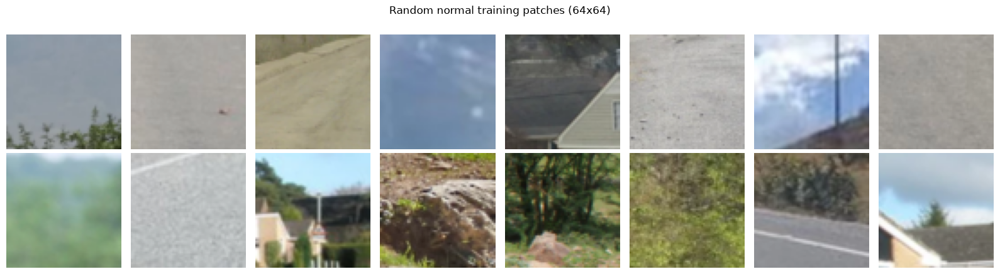

In [4]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
p_train, n_train = normal_patches(x_train, y_train, PATCH, STRIDE, MASK_MARGIN)
p_val, n_val = normal_patches(x_val, y_val, PATCH, STRIDE, MASK_MARGIN)
print(f"train: kept {len(p_train)} normal patches of {n_train} | val: kept {len(p_val)} of {n_val}")

fig, ax = plt.subplots(2, 8, figsize=(16, 4.5), tight_layout=True)
for a, i in zip(ax.flat, np.random.default_rng(SEED).choice(len(p_train), 16, replace=False), strict=True):
    a.imshow(p_train[i])
    a.axis("off")
plt.suptitle("Random normal training patches (64x64)")
plt.show()

In [5]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
# tf.data pipelines: shuffled + horizontally flipped for training, plain for validation
def augment_patch(patch):
    """Random horizontal flip only (scenes are never upside down). Returns (input, target)."""
    patch = tf.image.random_flip_left_right(patch)
    return patch, patch

# The target of an autoencoder is its own input; the training tiles are reshuffled at every epoch
train_patches = (tf.data.Dataset.from_tensor_slices(p_train).shuffle(len(p_train), seed=SEED)
                 .map(augment_patch, num_parallel_calls=tf.data.AUTOTUNE)
                 .batch(PIXEL_BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_patches = tf.data.Dataset.from_tensor_slices((p_val, p_val)).batch(PIXEL_BATCH_SIZE)

I0000 00:00:1793563122.195118 2513391 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6249 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


#### 3. Model: convolutional autoencoder (`roadanomaly.models.autoencoder`)
- **Encoder:** four stride-2 convolutions with ReLU halve the size four times (64 → 4).
- **Bottleneck:** a **linear** 4x4x2 code = 32 values for a 12,288-value patch (384x compression). The AE is strongly undercomplete, so it can only reproduce the *typical* appearance of a road scene.
- **Decoder:** mirrored `Conv2DTranspose` layers and a **sigmoid** output (pixels in [0, 1]).
- **No skip connections:** the information would bypass the bottleneck (that would be a U-Net, Cap. 10.3).
- **Fully convolutional:** trained on 64x64 patches, it reconstructs a whole 352x640 image (both sides divisible by 16).

**Why such a narrow bottleneck** (earlier model selection, validation only, sigma = 8; full record in `archive/B_feature_ae_and_backbone_study_adrian.ipynb`, section 3.1). A first version with 3 levels and 16 code channels (12x) reconstructed the obstacles **as well as the road** (Cap. 9.6: an AE that is too powerful "learns to reconstruct almost anything"). Narrowing the code raised the validation AuPRC from 0.096 (3 levels, 16 channels) to 0.151 (4 levels, 2 channels). A ReLU code collapsed on one of three seeds (a "dead" unit deletes half of a 2-channel code), so the code is linear.

In [6]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
pixel_ae.build_autoencoder().summary()

Model: "conv_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_1 (Conv2D)              │ (None, None, None, 32) │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_2 (Conv2D)              │ (None, None, None, 64) │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_3 (Conv2D)              │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_4 (Conv2D)              │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ code (Conv2D)                   │ (None, None, None, 2)  │         4,610 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_1 (Conv2DTranspose)     │ (None, None, None,     │         4,864 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_2 (Conv2DTranspose)     │ (None, None, None,     │       295,040 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_3 (Conv2DTranspose)     │ (None, None, None, 64) │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_4 (Conv2DTranspose)     │ (None, None, None, 32) │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Conv2D)         │ (None, None, None, 3)  │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 786,053 (3.00 MB)

 Trainable params: 786,053 (3.00 MB)

 Non-trainable params: 0 (0.00 B)

#### 4. Reconstruction losses (Khaled's comparison)
Same architecture, patches, split and seed; only the loss changes:
- **MSE**: the classic choice; the anomaly score is the same quantity per pixel.
- **MAE**: less sensitive to a few very bad pixels.
- **MAE + VGG19 perceptual loss**: adds the distance between the frozen ImageNet VGG19 features of the patch and of its reconstruction (weight 0.1), so the AE is pushed to keep textures and structures, not only colours.
- **SSIM**: structural similarity (luminance, contrast, structure) instead of a pixel difference.

The anomaly score stays the per-pixel squared RGB error for all four, so the comparison is about what the loss teaches the model, not about a different score.

In [7]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
def fit_variant(loss_name, perceptual=False):
    """Train one pixel AE at a fixed seed; returns (model, history)."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)   # the same seed for the four variants: only the loss differs between them
    # Section 3: four stride-2 convolutions down to a linear 4x4x2 code (384x compression). Such a narrow code
    # can only reproduce the typical appearance of the road, so an obstacle comes back badly
    model = pixel_ae.build_autoencoder()
    if perceptual:
        training_model = pixel_ae.PerceptualAutoencoder(model, pixel_ae.build_vgg19_feature_model(PATCH),
                                                        VGG_PERCEPTUAL_WEIGHT)
        training_model.compile(optimizer=keras.optimizers.Adam(PIXEL_LEARNING_RATE))
    else:
        training_model = model
        pixel_ae.compile_reconstruction_loss(model, loss_name, PIXEL_LEARNING_RATE)   # Adam + MSE, MAE or SSIM
    # Early stopping on the reconstruction loss of the VALIDATION normal tiles, keeping the best epoch's weights
    early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PIXEL_PATIENCE,
                                                   restore_best_weights=True)
    # Training: input = target = the normal tiles (the autoencoder learns to copy normal road only)
    history = training_model.fit(train_patches, validation_data=val_patches, epochs=PIXEL_MAX_EPOCHS,
                                 callbacks=[early_stopping], verbose=0)
    return model, history.history

variants = {"mse": fit_variant("mse"), "mae": fit_variant("mae"),
            "mae_vgg19": fit_variant("mae", perceptual=True), "ssim": fit_variant("ssim")}
for name, (_, history) in variants.items():
    print(f"{name:10s} epochs {len(history['loss']):3d} | best epoch {int(np.argmin(history['val_loss'])) + 1:3d}")

mse        epochs  46 | best epoch  38
mae        epochs  45 | best epoch  37
mae_vgg19  epochs  33 | best epoch  25
ssim       epochs  26 | best epoch  18


#### 5. From reconstruction to a score map, calibrated on validation
For each variant, the per-pixel squared error of the whole validation images goes through the shared post-processing (`roadanomaly.postprocessing`):
1. **Gaussian smoothing**, `sigma` chosen on validation by AuPRC: raw pixel errors are noisy, smoothing makes region-like scores;
2. **per-image z-score**: texture-rich images have a high error *everywhere*, so the score becomes "how unusual is this pixel compared with the rest of its own image" (assumes each image is mostly normal);
3. **threshold** maximising the per-image mean F1 on validation, then removal of blobs under `MIN_OBJECT_PX`.

The variant is chosen by validation **AuPRC** (main metric), with the per-image mean F1 as tie-breaker.

In [8]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
def calibrate(raw_maps, min_blob_candidates=(MIN_OBJECT_PX,)):
    """Sigma, threshold and minimum blob chosen on validation; returns settings, scores and the reports."""
    # Section 5: Gaussian smoothing (sigma chosen by validation AuPRC), per-image z-score, then the threshold
    # with the best mean F1 per validation photograph
    sigma, sigma_table = pp.select_sigma(gt_val, raw_maps)
    scores = pp.anomaly_scores(raw_maps, sigma)
    threshold, min_blob, _, _ = pp.select_threshold(gt_val, scores, min_blob_candidates=min_blob_candidates)
    free = evaluation.threshold_free_scores(gt_val, scores)
    report = evaluation.mask_report(gt_val, pp.to_masks(scores, threshold, min_blob))
    return {"sigma": sigma, "sigma_table": sigma_table, "threshold": threshold, "min_blob": min_blob,
            "scores": scores, "free": free, "report": report}

pixel_results = {}
for name, (model, _) in variants.items():
    recon_val, err_val = pixel_ae.reconstruction_error_maps(model, x_val)
    pixel_results[name] = {**calibrate(err_val), "recon": recon_val, "error": err_val}

pixel_table = pd.DataFrame({name: {**evaluation.summary(r["free"], r["report"]), "sigma": r["sigma"],
                                   "threshold": round(r["threshold"], 3)}
                            for name, r in pixel_results.items()})
PIXEL_WINNER = max(pixel_results, key=lambda n: (round(pixel_results[n]["free"]["AuPRC"], 3),
                                                 pixel_results[n]["report"]["pixel"]["per_image_mean"]["f1"]))
print("Baseline variant chosen on validation:", PIXEL_WINNER)
pixel_table

Baseline variant chosen on validation: mae_vgg19


,mse,mae,mae_vgg19,ssim
AuPRC (main),0.147674,0.150231,0.157301,0.120592
AUROC,0.676523,0.677968,0.694229,0.6109
AUPRO@0.3,0.506097,0.506821,0.527589,0.427339
FPR95 (lower is better),0.715087,0.729804,0.702401,0.777759
F1 = Dice (per-image mean),0.234211,0.237688,0.248721,0.196891
IoU (per-image mean),0.137817,0.140088,0.147532,0.112933
precision (per-image mean),0.168736,0.173223,0.179773,0.151029
recall (per-image mean),0.568787,0.573336,0.595062,0.505239
F1 (aggregated),0.227647,0.232094,0.246503,0.189427
Boundary IoU (15 px band),0.094684,0.095792,0.099324,0.124129


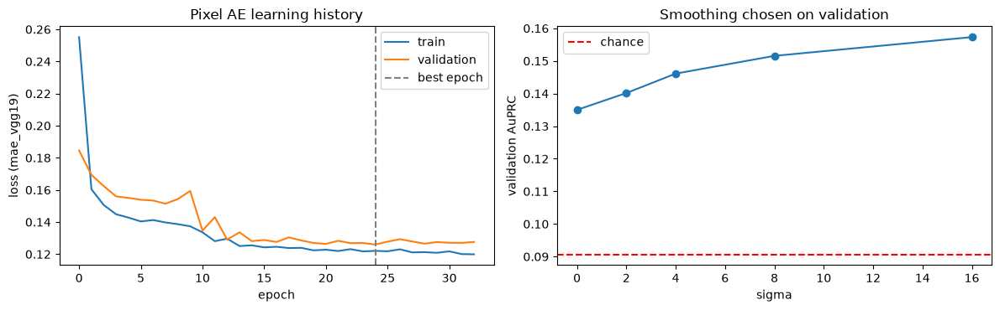

In [9]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
# Learning curves of the chosen variant and its sigma selection
history = variants[PIXEL_WINNER][1]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), tight_layout=True)
ax[0].plot(history["loss"], label="train")
ax[0].plot(history["val_loss"], label="validation")
ax[0].axvline(int(np.argmin(history["val_loss"])), color="gray", linestyle="--", label="best epoch")
ax[0].set_xlabel("epoch")
ax[0].set_ylabel(f"loss ({PIXEL_WINNER})")
ax[0].legend()
ax[0].set_title("Pixel AE learning history")
table = pixel_results[PIXEL_WINNER]["sigma_table"]
ax[1].plot(list(table), list(table.values()), marker="o")
ax[1].axhline(gt_val.mean(), color="red", linestyle="--", label="chance")
ax[1].set_xlabel("sigma")
ax[1].set_ylabel("validation AuPRC")
ax[1].legend()
ax[1].set_title("Smoothing chosen on validation")
plt.savefig(FIG_DIR / "B_01_pixel_ae_training.png", dpi=80)
plt.show()

#### 6. Where the false alarms come from (validation)
The 64x64 windows of the validation images with the most false-positive pixels, for the chosen variant. They show what a pixel autoencoder finds "unusual".

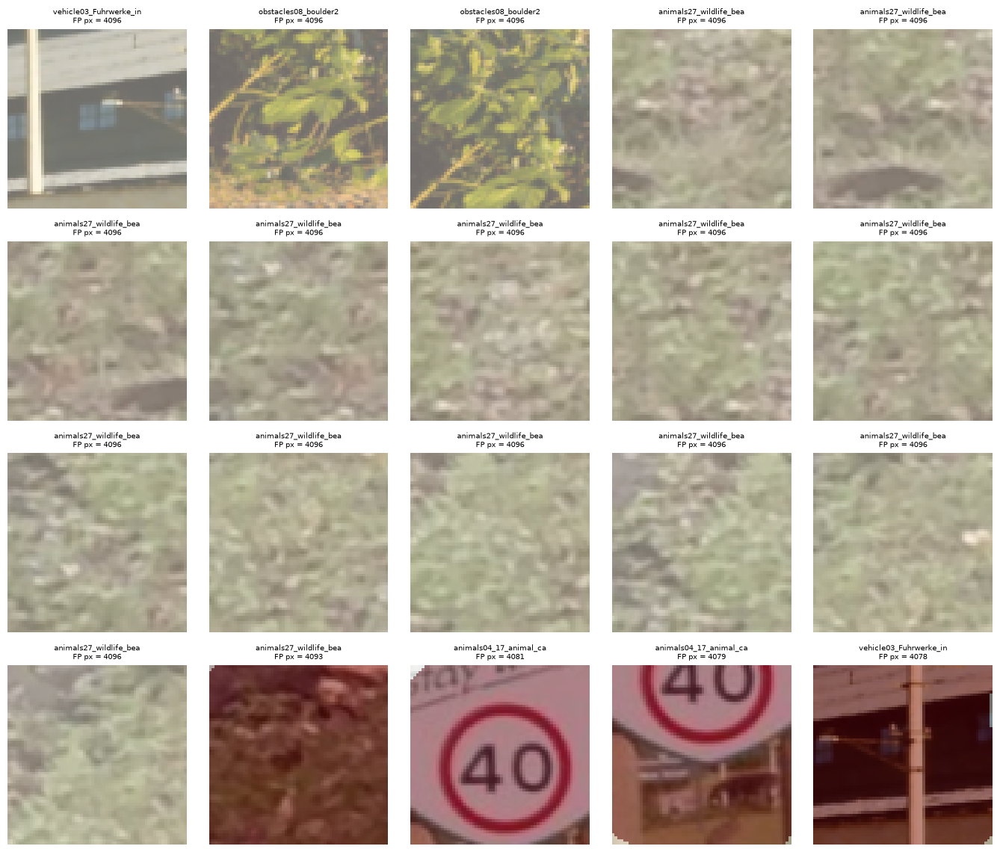

In [10]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
best = pixel_results[PIXEL_WINNER]
masks = pp.to_masks(best["scores"], best["threshold"], best["min_blob"]).astype(bool)
windows = []
for i, (truth, pred) in enumerate(zip(gt_val, masks, strict=True)):
    for top in range(0, IMG_SIZE[0] - PATCH + 1, STRIDE):
        for left in range(0, IMG_SIZE[1] - PATCH + 1, STRIDE):
            fp = int((pred[top:top + PATCH, left:left + PATCH] & ~truth[top:top + PATCH, left:left + PATCH]).sum())
            if fp:
                windows.append((fp, i, top, left))
windows = sorted(windows, reverse=True)[:20]
fig, ax = plt.subplots(4, 5, figsize=(14, 11.5), tight_layout=True)
for a, (fp, i, top, left) in zip(ax.flat, windows, strict=False):
    a.imshow(x_val[i, top:top + PATCH, left:left + PATCH])
    a.imshow((masks[i] & ~gt_val[i])[top:top + PATCH, left:left + PATCH], cmap="Reds", alpha=0.45)
    a.set_title(f"{val_frames[i][:22]}\nFP px = {fp}", fontsize=7)
for a in ax.flat:
    a.axis("off")
plt.savefig(FIG_DIR / "B_02_pixel_ae_false_positives.png", dpi=70)
plt.show()

**Reading the baseline.** The pixel autoencoder flags *unusual colour and texture*, not *unexpected objects*: foliage, leaf litter, building facades, sky gradients and high-contrast stripes produce most false alarms, while obstacles with ordinary colours (grey boulders on a grey road, a brown boar on brown leaves) are reconstructed well and missed. Changing the loss changes how textures are reproduced but not this limit, which is what Part 2 addresses.

In [11]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
# Save the baseline in the shared format (models/B_pixel_ae/)
best = pixel_results[PIXEL_WINNER]
history = variants[PIXEL_WINNER][1]
save_artifact(dp.MODELS_DIR / "B_pixel_ae", variants[PIXEL_WINNER][0], {
    "name": "B_pixel_ae", "binome": "B", "title": f"Pixel autoencoder ({PIXEL_WINNER} loss), baseline",
    "model_type": "pixel_autoencoder",
    "input": {"image_size": list(IMG_SIZE), "channels": "RGB", "range": [0, 1]},
    "postprocessing": {"sigma": best["sigma"], "per_image_z_score": True, "threshold": best["threshold"],
                       "min_blob_px": best["min_blob"]},
    "selection": {"split": "val", "variant_rule": "best AuPRC, then per-image mean F1",
                  "threshold_rule": "best per-image mean F1"},
    "validation": {**best["free"], **best["report"]["pixel"]["per_image_mean"]},
    "training": {"loss": PIXEL_WINNER, "seed": SEED, "patch": PATCH, "stride": STRIDE, "mask_margin": MASK_MARGIN,
                 "normal_patches_train": len(p_train), "learning_rate": PIXEL_LEARNING_RATE,
                 "batch_size": PIXEL_BATCH_SIZE, "epochs_ran": len(history["loss"]),
                 "best_epoch": int(np.argmin(history["val_loss"])) + 1},
})
print("saved models/B_pixel_ae")

saved models/B_pixel_ae


### Part 2 — Final model: feature-space autoencoder

The pixel autoencoder measures *unusual appearance*. Part 2 keeps the autoencoder idea but moves it to a better space: a network pretrained on ImageNet (VGG16, **frozen**, used only as a fixed measuring tool) turns each image region into a feature vector, and the autoencoder learns to reconstruct the feature vectors of **normal road scenes**. An obstacle is a region whose features it cannot reconstruct.

Rules of this part:
- every choice uses the **validation split only**; the train masks are used only for normal cells and the road prior;
- the list of candidates is **short on purpose**: with 9 validation images, trying many variants would fit the validation set itself;
- a component is kept only if it raises the validation AuPRC by more than the seed noise (`KEEP_MARGIN` = 0.002);
- every result of the feature AE is shown next to a **control without any autoencoder**, so its own contribution stays visible.

#### 7. Control experiment: where would a gain come from?
The simplest use of VGG is a *perceptual error*: compare the VGG features of the image with those of the pixel autoencoder's reconstruction. Before trusting it, it is compared with a **control that uses no reconstruction at all**: the size (L2 norm) of the feature vector at each position. If both score the same, the gain comes from the pretrained network and not from an autoencoder.

In [12]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
recon_val = pixel_results[PIXEL_WINNER]["recon"]
sigma_v1 = pixel_results[PIXEL_WINNER]["sigma"]

def free_auprc_auroc(raw_maps, sigma):
    free = evaluation.threshold_free_scores(gt_val, pp.anomaly_scores(raw_maps, sigma))
    return {"AuPRC": free["AuPRC"], "AUROC": free["AUROC"]}

control_rows = [{"layer": "pixels", "score map": f"pixel AE ({PIXEL_WINNER}), squared error",
                 **free_auprc_auroc(pixel_results[PIXEL_WINNER]["error"], sigma_v1)}]
for layer in FEATURE_LAYERS:
    f_image = feature_ae.extract_features(x_val, layer=layer)
    f_recon = feature_ae.extract_features(recon_val, layer=layer)
    control_rows.append({"layer": layer, "score map": "pixel AE, perceptual error",
                         **free_auprc_auroc(((f_image - f_recon) ** 2).mean(axis=-1), sigma_v1)})
    control_rows.append({"layer": layer, "score map": "control: feature norm, no AE",
                         **free_auprc_auroc(np.linalg.norm(f_image, axis=-1), sigma_v1)})
pd.DataFrame(control_rows).round(3)

,layer,score map,AuPRC,AUROC
0,pixels,"pixel AE (mae_vgg19), squared error",0.157,0.694
1,block3_conv3,"pixel AE, perceptual error",0.227,0.788
2,block3_conv3,"control: feature norm, no AE",0.217,0.789
3,block4_conv3,"pixel AE, perceptual error",0.300,0.809
4,block4_conv3,"control: feature norm, no AE",0.278,0.780
5,block5_conv3,"pixel AE, perceptual error",0.592,0.924
6,block5_conv3,"control: feature norm, no AE",0.598,0.918


**Reading the control.** The perceptual error is far better than the pixel error, but the plain feature norm, without any reconstruction, scores about **the same** at every depth: the improvement comes from the ImageNet features (an obstacle simply activates VGG more strongly than asphalt), not from the pixel autoencoder. The autoencoder therefore has to work **in feature space** to contribute.

#### 8. Features for the autoencoder
- **Normal cells.** A feature cell is normal if its image region holds no anomaly pixel after dilating each obstacle by `MASK_MARGIN` px (`normal_regions.normal_cells`). The training input is the whole feature map; anomaly cells get **weight 0 in the loss**.
- **Standardisation.** VGG channels have very different scales, so each channel is z-scored with the mean and standard deviation of the **train** normal cells.

In [13]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
def prepare_features(layer):
    """Standardised train / val features of one VGG16 layer, their normal cells and the train statistics."""
    f_train = feature_ae.extract_features(x_train, layer=layer)
    f_val = feature_ae.extract_features(x_val, layer=layer)
    ok_train, ok_val = normal_cells(y_train, f_train.shape[1:3]), normal_cells(y_val, f_val.shape[1:3])
    mean, std = feature_ae.feature_statistics(f_train, ok_train)
    return {"train": feature_ae.standardise(f_train, mean, std), "val": feature_ae.standardise(f_val, mean, std),
            "ok_train": ok_train, "ok_val": ok_val, "mean": mean, "std": std}

def train_on(data, seed):
    """One feature AE trained on the normal cells of `data` (roadanomaly.models.feature_ae)."""
    # Inside feature_ae.train_feature_ae: Adam (learning rate 1e-3), MSE on the standardised features with weight 0
    # for every cell that touches an obstacle (masked MSE), batches of 8 whole feature maps, at most 300 epochs
    # with early stopping (patience 15) on the normal cells of the validation photographs
    return feature_ae.train_feature_ae(data["train"], data["ok_train"], data["val"], data["ok_val"], seed)

# 512 VGG16 channels -> 256 -> a linear code of 8 channels per cell -> 256 -> 512: the code is 64 times narrower
# than its input, so the feature vectors of normal road come back well and unusual ones badly
feature_ae.build_feature_ae(512).summary()

Model: "feature_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Conv2D)                │ (None, None, None,     │     1,179,904 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ code (Conv2D)                   │ (None, None, None, 8)  │         2,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Conv2D)                │ (None, None, None,     │        18,688 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Conv2D)         │ (None, None, None,     │       131,584 │
│                                 │ 512)                   │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,332,232 (5.08 MB)

 Trainable params: 1,332,232 (5.08 MB)

 Non-trainable params: 0 (0.00 B)

**Model** (`roadanomaly.models.feature_ae`): the same design rules as the pixel AE, adapted to features. No stride (a cell already summarises a region, so the AE compresses the channels of each cell with a 3x3 neighbourhood); a narrow **linear** code of 8 channels per cell; a **linear** output (standardised features are unbounded); **masked MSE**; early stopping on the validation normal cells.

#### 9. Which VGG depth? (validation only)
One feature AE per depth (seed `SEED`). The depth with the best **feature-AE** AuPRC is kept; the "no AE" columns use the same standardised features without any reconstruction.

In [14]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
# One feature AE per VGG16 depth, same seed; the depth is chosen by validation AuPRC only
layer_rows = []
for layer in FEATURE_LAYERS:
    data = prepare_features(layer)
    model, history = train_on(data, SEED)
    layer_rows.append(
        {
            "layer": layer,
            "cells": f"{data['val'].shape[1]}x{data['val'].shape[2]}",
            "epochs": len(history.history["loss"]),
            **{
                f"feature AE {k}": v
                for k, v in free_auprc_auroc(feature_ae.cell_error_maps(model, data["val"]), sigma_v1).items()
            },
            **{f"no AE {k}": v for k, v in free_auprc_auroc(np.linalg.norm(data["val"], axis=-1), sigma_v1).items()},
        }
    )
del data, model
layer_df = pd.DataFrame(layer_rows).round(3)
FEATURE_LAYER = layer_df.loc[layer_df["feature AE AuPRC"].idxmax(), "layer"]
print("Chosen depth (best feature-AE AuPRC on validation):", FEATURE_LAYER)
layer_df

Chosen depth (best feature-AE AuPRC on validation): block5_conv3


,layer,cells,epochs,feature AE AuPRC,feature AE AUROC,no AE AuPRC,no AE AUROC
0,block3_conv3,88x160,224,0.26,0.812,0.274,0.831
1,block4_conv3,44x80,212,0.43,0.877,0.418,0.869
2,block5_conv3,22x40,62,0.59,0.920,0.629,0.939


#### 10. Smoothing, road prior and seed ensemble (ablation on validation)
- **Smoothing:** sigma is chosen again, because a feature map is coarser than a pixel map.
- **Road prior:** notebook 2 found almost no obstacle in the top of the image. `ROAD_TOP_ROW` is learned from the **train masks only** (rows above it hold < 1 % of the train anomaly pixels), and their scores are set to the lowest score of the image.
- **Seed ensemble:** the feature AE trained with 3 seeds, error maps averaged.

Each component is added in turn and **kept only if the validation AuPRC rises by more than `KEEP_MARGIN`**.

In [15]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
anomaly_per_row = y_train[..., 0].sum(axis=(0, 2))
ROAD_TOP_ROW = int(np.argmax(np.cumsum(anomaly_per_row) / anomaly_per_row.sum() >= ROAD_PRIOR_SHARE))
print(f"ROAD_TOP_ROW = {ROAD_TOP_ROW} of {IMG_SIZE[0]} rows")

def feature_scores(cell_maps_per_seed, sigma, use_ensemble, use_prior):
    """Average over seeds (optional) -> upsample + smoothing + per-image z-score -> road prior (optional)."""
    cells = np.mean(cell_maps_per_seed, axis=0) if use_ensemble else cell_maps_per_seed[0]
    scores = pp.anomaly_scores(cells, sigma)
    if use_prior:
        scores = scores.copy()
        scores[:, :ROAD_TOP_ROW] = scores.min(axis=(1, 2), keepdims=True)
    return scores

data = prepare_features(FEATURE_LAYER)
ensemble = [train_on(data, seed)[0] for seed in ENSEMBLE_SEEDS]
cells_val = [feature_ae.cell_error_maps(model, data["val"]) for model in ensemble]

SIGMA_FEATURE, _ = pp.select_sigma(gt_val, cells_val[0])
config = {"sigma": sigma_v1, "use_ensemble": False, "use_prior": False}
scores_val = feature_scores(cells_val, **config)
ablation = [{"step": f"baseline: pixel AE ({PIXEL_WINNER})", **pixel_results[PIXEL_WINNER]["free"], "kept": "-"},
            {"step": f"feature AE on {FEATURE_LAYER} (1 seed, sigma {sigma_v1})",
             **evaluation.threshold_free_scores(gt_val, scores_val), "kept": "-"}]
for name, change in [(f"+ smoothing chosen on val (sigma {SIGMA_FEATURE})", {"sigma": SIGMA_FEATURE}),
                     (f"+ road prior (rows < {ROAD_TOP_ROW})", {"use_prior": True}),
                     (f"+ {len(ENSEMBLE_SEEDS)}-seed ensemble", {"use_ensemble": True})]:
    trial = {**config, **change}
    trial_scores = feature_scores(cells_val, **trial)
    row = evaluation.threshold_free_scores(gt_val, trial_scores)
    kept = row["AuPRC"] > pp.auprc(gt_val, scores_val) + KEEP_MARGIN
    if kept:
        config, scores_val = trial, trial_scores
    ablation.append({"step": name, **row, "kept": "yes" if kept else "no"})

control_val = feature_scores([np.linalg.norm(data["val"], axis=-1)], config["sigma"], False, config["use_prior"])
ablation.append({"step": f"control: {FEATURE_LAYER} features, no AE (same post-processing)",
                 **evaluation.threshold_free_scores(gt_val, control_val), "kept": "-"})
ablation_df = pd.DataFrame(ablation).drop(columns=["AuPRC chance", "AUROC chance", "AUPRO chance"]).round(3)
print("Final configuration:", config)
ablation_df

ROAD_TOP_ROW = 42 of 352 rows


Final configuration: {'sigma': 8, 'use_ensemble': False, 'use_prior': False}


,step,AuPRC,AUROC,FPR95,AUPRO,kept
0,baseline: pixel AE (mae_vgg19),0.157,0.694,0.702,0.528,-
1,"feature AE on block5_conv3 (1 seed, sigma 16)",0.590,0.920,0.358,0.706,-
2,+ smoothing chosen on val (sigma 8),0.596,0.913,0.409,0.700,yes
3,+ road prior (rows < 42),0.580,0.891,0.744,0.701,no
4,+ 3-seed ensemble,0.596,0.913,0.409,0.703,no
5,"control: block5_conv3 features, no AE (same po...",0.627,0.935,0.255,0.718,-


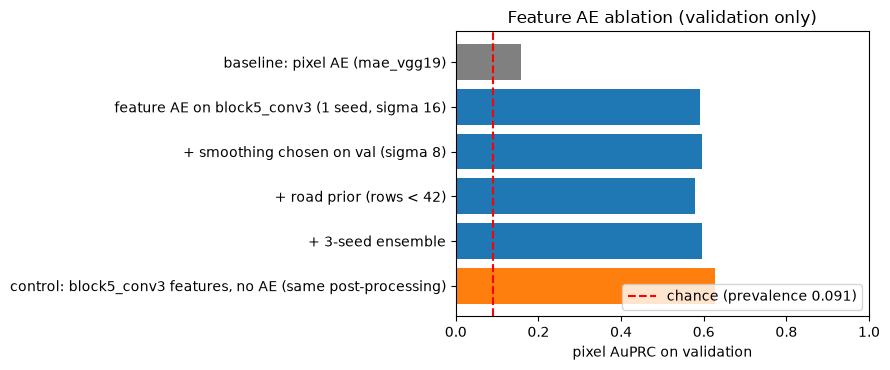

In [16]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
fig, ax = plt.subplots(figsize=(9, 3.8), tight_layout=True)
colours = ["grey"] + ["tab:blue"] * (len(ablation_df) - 2) + ["tab:orange"]
ax.barh(ablation_df["step"][::-1], ablation_df["AuPRC"][::-1], color=colours[::-1])
ax.axvline(gt_val.mean(), color="red", linestyle="--", label=f"chance (prevalence {gt_val.mean():.3f})")
ax.set_xlim(0, 1)
ax.set_xlabel("pixel AuPRC on validation")
ax.set_title("Feature AE ablation (validation only)")
ax.legend(loc="lower right")
plt.savefig(FIG_DIR / "B_03_feature_ae_ablation.png", dpi=80)
plt.show()

#### 11. Threshold and minimum blob size (validation only)
The threshold maximises the per-image mean F1 on validation, and the minimum size of a predicted blob is chosen at the same time (removing blobs smaller than a real obstacle may remove many false alarms). Only the **predictions** are filtered; the ground truth keeps the speckle limit of the protocol.

In [17]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
assert not config["use_ensemble"] and not config["use_prior"], \
    "the shared Predictor serves one model without road prior: extend inference.py before keeping these"
# Threshold and minimum blob size are chosen together on validation: dropping predicted blobs smaller than a real
# obstacle removes many false alarms (the candidates are 4, 64 and 256 px)
THRESHOLD, MIN_BLOB, best_f1, _ = pp.select_threshold(gt_val, scores_val, min_blob_candidates=MIN_BLOB_CANDIDATES)
print(f"Threshold {THRESHOLD:.4f} | minimum blob {MIN_BLOB} px | validation per-image mean F1 {best_f1:.4f}")

final_free = evaluation.threshold_free_scores(gt_val, scores_val)
final_report = evaluation.mask_report(gt_val, pp.to_masks(scores_val, THRESHOLD, MIN_BLOB))
pd.DataFrame({f"baseline: pixel AE ({PIXEL_WINNER})": evaluation.summary(pixel_results[PIXEL_WINNER]["free"],
                                                                          pixel_results[PIXEL_WINNER]["report"]),
              "final: feature AE": evaluation.summary(final_free, final_report)})

Threshold 0.5948 | minimum blob 256 px | validation per-image mean F1 0.5750


,baseline: pixel AE (mae_vgg19),final: feature AE
AuPRC (main),0.157301,0.59601
AUROC,0.694229,0.912895
AUPRO@0.3,0.527589,0.699699
FPR95 (lower is better),0.702401,0.409246
F1 = Dice (per-image mean),0.248721,0.575039
IoU (per-image mean),0.147532,0.421448
precision (per-image mean),0.179773,0.574594
recall (per-image mean),0.595062,0.710423
F1 (aggregated),0.246503,0.565917
Boundary IoU (15 px band),0.099324,0.224365


In [18]:
# Binôme B · Khaled Gannoun & Adrian Salvador Ekomo Mesi Obono
# Save the final model in the shared format (models/B_feature_ae/): AE weights + train feature statistics
model = ensemble[0]   # the seed-SEED model; the ensemble was not kept (section 10)
save_artifact(
    dp.MODELS_DIR / "B_feature_ae",
    model,
    {
        "name": "B_feature_ae",
        "binome": "B",
        "title": f"Feature-space autoencoder on frozen VGG16 {FEATURE_LAYER}",
        "model_type": "feature_autoencoder",
        "input": {"image_size": list(IMG_SIZE), "channels": "RGB", "range": [0, 1]},
        "features": {"backbone": feature_ae.BACKBONE, "layer": FEATURE_LAYER, "weights": "imagenet (frozen)"},
        "postprocessing": {
            "sigma": config["sigma"],
            "per_image_z_score": True,
            "threshold": THRESHOLD,
            "min_blob_px": MIN_BLOB,
        },
        "selection": {
            "split": "val",
            "depth_rule": "best feature-AE AuPRC",
            "component_rule": f"AuPRC gain > {KEEP_MARGIN}",
            "threshold_rule": "best per-image mean F1 (threshold and min blob together)",
        },
        "validation": {**final_free, **final_report["pixel"]["per_image_mean"]},
        "controls_validation_auprc": {"feature norm, no AE": pp.auprc(gt_val, control_val)},
        "training": {
            "seed": SEED,
            "hidden": feature_ae.HIDDEN,
            "code_channels": feature_ae.CODE_CHANNELS,
            "learning_rate": feature_ae.LEARNING_RATE,
            "batch_size": feature_ae.BATCH_SIZE,
            "mask_margin": MASK_MARGIN,
            "normal_cells_train": int(data["ok_train"].sum()),
        },
    },
    feature_stats=(data["mean"], data["std"]),
)
print("saved models/B_feature_ae")

saved models/B_feature_ae


#### 12. Is VGG16 the right backbone? (summary of the archived study)
Ten other ImageNet encoders from `keras.applications` were compared with the same feature AE, plus a PaDiM-style Gaussian control (Ledoit-Wolf covariance, Mahalanobis distance), on **validation only**. The full study, with its code and outputs, is kept in `archive/B_feature_ae_and_backbone_study_adrian.ipynb` (section 14); its result fixed the backbone used above.

| Rank | Backbone | AE AuPRC | AE AUPRO | Best control AuPRC | AE − control | ms / image (RTX 4060) |
|---|---|---|---|---|---|---|
| 1 | **VGG16** | **0.596** | 0.700 | 0.629 | −0.033 | 24.4 |
| 2 | VGG19 | 0.592 | 0.655 | 0.604 | −0.012 | 30.1 |
| 3 | Xception | 0.588 | **0.788** | 0.587 | +0.001 | 22.1 |
| 4 | ResNet50 | 0.541 | 0.730 | 0.523 | +0.018 | 26.3 |
| 5 | DenseNet121 | 0.527 | 0.748 | 0.513 | +0.014 | 32.9 |
| 6–11 | ResNet101, EfficientNetV2S, ConvNeXtTiny, EfficientNetB0, MobileNetV3Large, ResNet50V2 | 0.31–0.51 | | | | 15–44 |

VGG16, VGG19 and Xception are within noise of each other. Newer batch-normalised networks are worse here; a likely reason (a hypothesis) is that VGG has no batch normalisation, so the *size* of its activations still signals a salient object.

#### 13. Findings of the modeling phase (validation)
- **Feature space is what matters.** Moving the autoencoder from pixels to frozen ImageNet features multiplies the validation AuPRC several times (sections 10–11). The worst baseline failures (grey boulder on a grey road, brown boar on leaves) are typical successes of the feature AE.
- **The autoencoder itself adds little.** At the chosen depth, the plain feature norm without any AE scores about as well as the feature AE (section 10, orange bar), and across 11 backbones the AE is about equal to a Gaussian on the same features (section 12). With 42 training images, most of the detection ability comes from ImageNet pre-training. This is reported as a finding, and the group comparison must read Binôme B as "pretrained features + feature AE".
- **Dropped on validation evidence:** the road prior (the bear and the Czech hedgehog of validation reach the top of the frame) and the 3-seed ensemble (no variance left to remove).
- **Known weaknesses:** small objects (a 16-px cell and a large minimum blob trade them for fewer false alarms), coarse boundaries, and ordinary objects that are not labelled as anomalies (bollards, pedestrians, a house).
- **External knowledge:** VGG16 / VGG19 weights come from ImageNet, the same kind of transfer learning as Binôme A's backbone; to be stated in the report and confirmed as allowed for Binôme B.

The test split has not been used here. Both B models are evaluated once, with A and C, in [`../5_Evaluation.ipynb`](5_Evaluation.ipynb); their paired explanations (Grad-CAM++ and exact SHAP) are in [`../6_XAI.ipynb`](6_XAI.ipynb).

In [ ]:
# End of 4 · Modeling, Binôme B: clean up before the next phase (cell added by scripts/build_master_notebook.py).
# The namespace and the Keras session are cleared, so the next phase starts as in its own kernel. TensorFlow
# settings of the process (GPU memory configuration, deterministic GPU kernels) stay for the whole kernel.
%reset -f
import gc

import keras

keras.backend.clear_session()
gc.collect()

## 4 · Modeling — Binôme C: CNN baseline and U-Nets

**CRISP-DM phase 4 (Modeling).** Team: Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets) (FR, Binôme C).

Supervised binary segmentation, three models in increasing order of capacity:

| Part | Model | Author | Saved as |
|---|---|---|---|
| 1 | **CNN baseline**: encoder–decoder without skip connections | Hejer | `models/C_cnn/` |
| 2 | **U-Net from scratch**: the same idea with skip connections | Walid | `models/C_unet/` |
| 3 | **U-Net with an ImageNet ResNet50 encoder**, focal + Tversky loss, flip test-time augmentation | Walid | `models/C_unet_resnet50/` |

**Provenance.** Hejer and Walid built these models in PyTorch (`archive/C_cnn_original_run_hejer.ipynb`, `archive/C_unet_original_run_walid.ipynb`). Their runs used their own split, which differs from the group's frozen split:
- 40/10/10 by category, not group-aware;
- 288×512 resolution;
- pooled metrics.

This notebook ports their architectures and training recipes to Keras and retrains them **on the shared split, at 352×640, with the shared metrics and threshold rule**, so that C can be compared with A and B. Their original numbers (validation IoU 0.27 CNN, 0.39 U-Net, 0.815 U-Net ResNet34) are **not comparable** with the numbers below:
- their split can put near-duplicate frames of one scene in both train and validation, which inflates validation scores;
- Walid's best encoder was ResNet34, which Keras does not provide (ResNet50 is used here).

**Protocol.** Checkpoints are chosen on the validation IoU (their rule) and thresholds by the shared rule (best per-image mean F1 on validation, blobs under `MIN_OBJECT_PX` removed), as for A and B. The test split is not loaded here; the single test evaluation is in notebook 5 and the explanations (Grad-CAM++ and exact SHAP) in notebook 6.

> **Binôme C · Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets)**  
> A CNN baseline, a U-Net from scratch and a U-Net with an ImageNet ResNet50 encoder. Saved models: `C_cnn`, `C_unet`, `C_unet_resnet50`.  
> Every code cell of this part starts with a comment naming the binôme.

#### TL;DR — from a thumbnail sketch to borrowed eyes

Three supervised models, each adding one idea to the previous one, all trained on the same 42 photographs and judged by the same rules:

| Model | The idea, in one sentence | Trained weights | Validation AuPRC | False-alarm blobs |
|---|---|---|---|---|
| **CNN baseline** (Hejer) | Shrink the photo to 1/8, then redraw the mask from that thumbnail | 0.19 M | 0.411 | 132 of 199 |
| **U-Net** (Walid) | Same, but **skip connections** pass the full-detail notes of the encoder to the decoder, so outlines need not be guessed | 1.9 M | 0.453 | 33 of 47 |
| **U-Net + ImageNet ResNet50** (Walid) | Same U-Net, with an encoder that already learned to see on 1.2 M ImageNet photographs, plus a loss that punishes missed pixels more than false alarms | 30.4 M | **0.728** | 36 of 80 |

(A blind guess scores AuPRC 0.091.)

- **Skip connections help**, as the theory says: the U-Net raises AuPRC and cuts the false-alarm blobs from 132 to 33. Its recipe also differs from the CNN's (10 times more weights, another optimiser), so this is consistent with the effect of the skips rather than a clean ablation.
- **Borrowed eyes help most:** the pretrained encoder adds about **0.28 AuPRC**. 42 photographs are too few to learn to see from scratch.
- **The price:** the pretrained U-Net finds only 2 of the 12 small validation obstacles.
- **Their original PyTorch numbers are not comparable** (validation IoU 0.815 for Walid's ResNet34 U-Net): they came from a split where frames of one video could sit on both sides, which makes validation easier.

#### 0. Setup

In [1]:
# Binôme C · Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets)
# Import libraries
import os

# hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

import keras
import tensorflow as tf

tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

import warnings

from roadanomaly import data_pipeline as dp
from roadanomaly import evaluation, losses
from roadanomaly import postprocessing as pp
from roadanomaly.gpu import setup_gpu
from roadanomaly.inference import save_artifact
from roadanomaly.models.cnn import build_cnn_baseline
from roadanomaly.models.unet import build_unet, build_unet_resnet50
from roadanomaly.protocol import IMG_SIZE, MIN_OBJECT_PX, SEED

warnings.filterwarnings('ignore')

In [2]:
# Binôme C · Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets)
THRESHOLD_QUANTILES = np.linspace(0.01, 0.99, 51)   # candidate thresholds on validation probabilities (as A)
KEEP_MARGIN = 0.002                                  # a component (here TTA) must raise val AuPRC by more than this
FIG_DIR = dp.FIG_DIR
CHECKPOINTS = dp.REPO_ROOT / "checkpoints"            # git-ignored

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
GPU_NAME = setup_gpu()
print("TensorFlow:", tf.__version__, "| GPU:", GPU_NAME)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)
TensorFlow: 2.20.0 | GPU: NVIDIA GeForce RTX 4060 Laptop GPU


#### 1. Data
The shared loader: images in [0, 1] at 352×640, binary masks, and the shared training augmentation:
- horizontal flip;
- random crop of at least 80 %;
- brightness and contrast.

Hejer and Walid used a similar augmentation (flip, small shift / scale / rotation, brightness / contrast), and Walid used a stronger one for his improved U-Net. The shared one is kept so that the three binômes differ only by their models. ImageNet normalisation is inside each model.

In [3]:
# Binôme C · Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets)
train_frames, x_train, y_train = dp.load_split("train", IMG_SIZE)
val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)
gt_val = y_val[..., 0].astype(bool)
print(
    "x_train:",
    x_train.shape,
    "| x_val:",
    x_val.shape,
    f"| anomaly pixels: train {y_train.mean():.2%}, val {y_val.mean():.2%}",
)

x_train: (42, 352, 640, 3) | x_val: (9, 352, 640, 3) | anomaly pixels: train 10.29%, val 9.07%


#### 2. Training and calibration helpers
Both helpers are shared by the three models, so that the three are trained and calibrated the same way:
- **`train`** keeps the epoch with the best **validation IoU** at threshold 0.5. That is Hejer's and Walid's selection rule, through a Keras `BinaryIoU` metric on the anomaly class. Early stopping is optional.
- **`calibrate`** chooses the threshold on the validation probabilities with the shared rule and computes the shared validation report.

In [4]:
# Binôme C · Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets)
def train(name, model, loss, optimizer, epochs, batch_size, patience=None):
    """Fit on the shared loader, keep the best validation-IoU checkpoint; returns (best model, history)."""
    keras.utils.set_random_seed(SEED)   # same initial weights and data order on every run
    path = CHECKPOINTS / name / "best.keras"
    path.parent.mkdir(parents=True, exist_ok=True)
    # Validation IoU of the anomaly class at threshold 0.5: Hejer's and Walid's checkpoint metric, kept so that
    # their selection rule is unchanged (the final threshold is chosen afterwards with the shared rule)
    model.compile(optimizer=optimizer, loss=loss, jit_compile=False,
                  metrics=[keras.metrics.BinaryIoU(target_class_ids=[1], threshold=0.5, name="iou")])
    # Keep the epoch with the best validation IoU, not the last one
    callbacks = [keras.callbacks.ModelCheckpoint(str(path), monitor="val_iou", mode="max", save_best_only=True),
                 keras.callbacks.TerminateOnNaN()]
    if patience:   # optional early stopping on the same metric (used by the U-Net ResNet50 only)
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_iou", mode="max", patience=patience))
    # Training on the shared loader: shuffled and augmented batches (flip, crop, brightness / contrast), then the
    # validation IoU on the 9 validation photographs after every epoch. The test split is never used here
    history = model.fit(dp.get_dataset(x_train, y_train, batch_size, training=True, seed=SEED),
                        validation_data=dp.get_dataset(x_val, y_val, batch_size), epochs=epochs,
                        callbacks=callbacks, verbose=0).history
    best = int(np.argmax(history["val_iou"]))
    print(
        f"{name}: {len(history['loss'])} epochs | best epoch {best + 1} | best val IoU {history['val_iou'][best]:.3f}"
    )
    return keras.models.load_model(path, compile=False), history

def probabilities(model, images, tta=False, batch_size=4):
    """Anomaly probabilities; with tta, averaged with the prediction of the mirrored image (as the Predictor)."""
    p = model.predict(images, batch_size=batch_size, verbose=0)[..., 0]
    if tta:
        p = (p + model.predict(images[:, :, ::-1], batch_size=batch_size, verbose=0)[..., 0][:, :, ::-1]) / 2
    return p

def calibrate(prob_val):
    """Threshold with the shared rule, and the shared validation report."""
    threshold, min_blob, f1, _ = pp.select_threshold(gt_val, prob_val, quantiles=THRESHOLD_QUANTILES,
                                                      min_blob_candidates=(MIN_OBJECT_PX,))
    free = evaluation.threshold_free_scores(gt_val, prob_val)
    report = evaluation.mask_report(gt_val, pp.to_masks(prob_val, threshold, min_blob))
    return {"threshold": threshold, "min_blob": min_blob, "prob": prob_val, "free": free, "report": report}

def save(name, model, title, result, training, tta=False):
    save_artifact(dp.MODELS_DIR / name, model, {
        "name": name, "binome": "C", "title": title, "model_type": "segmentation",
        "input": {"image_size": list(IMG_SIZE), "channels": "RGB", "range": [0, 1]},
        "postprocessing": {"sigma": 0, "per_image_z_score": False, "threshold": result["threshold"],
                           "min_blob_px": result["min_blob"], "tta_flip": tta},
        "selection": {"split": "val", "checkpoint_rule": "best validation IoU at threshold 0.5",
                      "threshold_rule": "best per-image mean F1 over 51 quantiles (0.01-0.99)"},
        "validation": {**result["free"], **result["report"]["pixel"]["per_image_mean"]},
        "training": {"seed": SEED, **training},
    })
    print("saved models/" + name)

def plot_history(history, title, path):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), tight_layout=True)
    ax[0].plot(history["loss"], label="train")
    ax[0].plot(history["val_loss"], label="validation")
    ax[0].set_xlabel("epoch")
    ax[0].set_ylabel("loss")
    ax[0].legend()
    ax[0].set_title(f"{title}: loss")
    ax[1].plot(history["val_iou"], color="tab:green")
    ax[1].axvline(int(np.argmax(history["val_iou"])), color="gray", linestyle="--")
    ax[1].set_xlabel("epoch")
    ax[1].set_ylabel("validation IoU (threshold 0.5)")
    ax[1].set_title("checkpoint selection")
    plt.savefig(FIG_DIR / path, dpi=75)
    plt.show()

### Part 1 — CNN baseline (Hejer)

**Architecture** (`roadanomaly.models.cnn`):
- **Encoder:** three Conv 3×3 → BatchNorm → ReLU blocks with max pooling (32, 64, 128 channels), down to 1/8 resolution.
- **Decoder:** three ConvTranspose 2×2 upsamplings, each followed by Conv → BatchNorm → ReLU (64, 32, 16 channels).
- **Output:** a 1×1 logit per pixel.
- **No skip connections:** the detail lost by pooling cannot come back, which makes this the teaching baseline.

**Loss: BCE + Dice.** The Dice term counterbalances the 90 / 10 class imbalance.

**Recipe** (Hejer):
- AdamW, learning rate 1e-3, weight decay 1e-4;
- cosine decay over 80 epochs;
- batch 4;
- the best validation IoU is kept.

I0000 00:00:1793564483.029093 2978146 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6249 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


C_cnn: 80 epochs | best epoch 48 | best val IoU 0.292
trainable parameters: 185,553


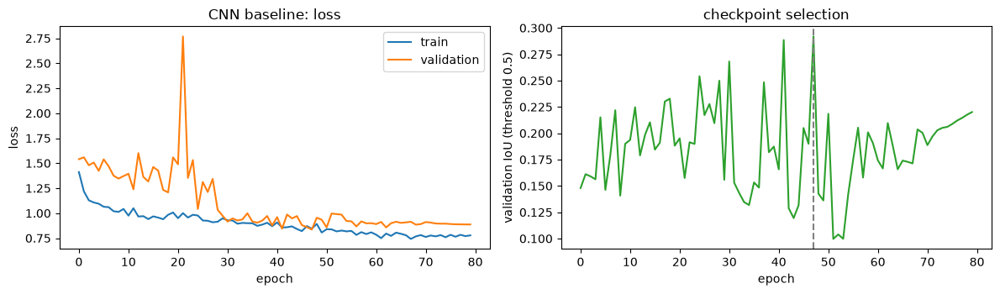

In [5]:
# Binôme C · Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets)
# Hejer's recipe, kept unchanged:
# - 80 epochs, a fixed budget without early stopping (the epoch with the best validation IoU is kept);
# - batch 4, i.e. 11 steps per epoch over the 42 training photographs;
CNN_EPOCHS, CNN_BATCH = 80, 4
steps = int(np.ceil(len(x_train) / CNN_BATCH)) * CNN_EPOCHS   # total number of optimiser steps, for the schedule
keras.utils.set_random_seed(SEED)
# - loss BCE + Dice: the cross-entropy judges each pixel, the Dice term the overlap of the whole mask, which
#   counterbalances the 90 / 10 background / obstacle imbalance;
# - AdamW: learning rate 1e-3 decayed to 0 along a cosine over the 80 epochs (large steps first, fine ones at the
#   end) and weight decay 1e-4, a light regularisation of the weights
cnn, cnn_history = train("C_cnn", build_cnn_baseline((*IMG_SIZE, 3)), losses.bce_dice_loss,
                         keras.optimizers.AdamW(keras.optimizers.schedules.CosineDecay(1e-3, steps), weight_decay=1e-4),
                         CNN_EPOCHS, CNN_BATCH)
print(f"trainable parameters: {sum(int(np.prod(w.shape)) for w in cnn.trainable_weights):,}")
plot_history(cnn_history, "CNN baseline", "C_01_cnn_training.png")

In [6]:
# Binôme C · Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets)
cnn_result = calibrate(probabilities(cnn, x_val))
save("C_cnn", cnn, "CNN baseline (encoder-decoder, no skips)", cnn_result,
     {"author": "Hejer", "loss": "BCE + Dice", "optimizer": "AdamW 1e-3, wd 1e-4, cosine", "epochs": CNN_EPOCHS,
      "batch_size": CNN_BATCH, "best_epoch": int(np.argmax(cnn_history["val_iou"])) + 1})

saved models/C_cnn


### Part 2 — U-Net from scratch (Walid)

**Architecture** (`roadanomaly.models.unet.build_unet`):
- **Encoder:** four stages of two Conv-BN-ReLU blocks (16, 32, 64, 128 channels) with max pooling.
- **Bottleneck:** 256 channels.
- **Decoder:** ConvTranspose upsampling, then **concatenation with the encoder features of the same resolution** (skip connections), then two Conv-BN-ReLU blocks.
- **What the skips do:** they bring back the edges and small structures that the bottleneck loses. This is the difference FR asks Binôme C to measure (CNN vs U-Net).

**Recipe** (Walid): BCE + Dice, Adam with learning rate 1e-3, 50 epochs, batch 4, best validation IoU kept.

C_unet: 50 epochs | best epoch 43 | best val IoU 0.346


trainable parameters: 1,944,049


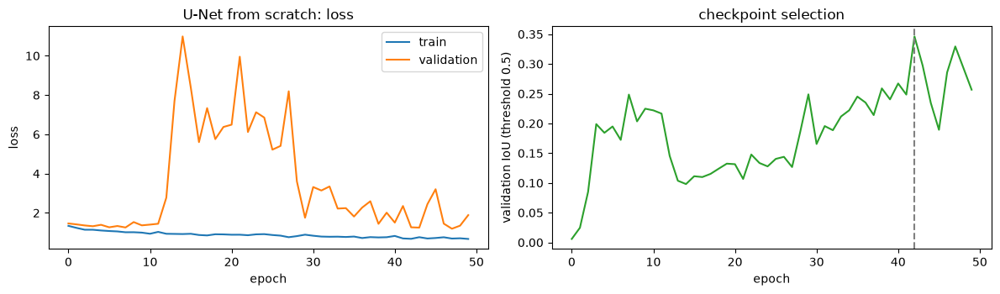

saved models/C_unet


In [7]:
# Binôme C · Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets)
# Walid's recipe, kept unchanged: BCE + Dice loss (as the CNN), Adam with a constant learning rate of 1e-3,
# 50 epochs, batch 4, best validation-IoU epoch kept. The U-Net differs from the CNN by its skip connections, but
# also by its size (1.9 M weights against 0.19 M) and its optimiser, so the comparison is between two recipes
UNET_EPOCHS, UNET_BATCH = 50, 4
unet, unet_history = train("C_unet", build_unet((*IMG_SIZE, 3)), losses.bce_dice_loss,
                           keras.optimizers.Adam(1e-3), UNET_EPOCHS, UNET_BATCH)
print(f"trainable parameters: {sum(int(np.prod(w.shape)) for w in unet.trainable_weights):,}")
plot_history(unet_history, "U-Net from scratch", "C_02_unet_training.png")
unet_result = calibrate(probabilities(unet, x_val))
save("C_unet", unet, "U-Net from scratch", unet_result,
     {"author": "Walid", "loss": "BCE + Dice", "optimizer": "Adam 1e-3", "epochs": UNET_EPOCHS,
      "batch_size": UNET_BATCH, "best_epoch": int(np.argmax(unet_history["val_iou"])) + 1})

### Part 3 — U-Net with a pretrained ImageNet encoder (Walid's improvement)

Walid's diagnosis was that 40 training images are too few to learn good features from scratch, so he used an encoder pretrained on ImageNet.

**Encoder.** `roadanomaly.models.unet.build_unet_resnet50`:
- A **ResNet50** is used instead of his ResNet34, which Keras does not provide.
- The skips come from its outputs at strides 2, 4, 8 and 16, and its stride-32 output is the bridge.
- The convolutions are fine-tuned. The BatchNorm statistics stay frozen, because batches of 8 are too small to re-estimate them.

**Recipe** (Walid):
- **Loss: focal + focal-Tversky** (α 0.3, β 0.7, γ 0.75). The focal term spends less effort on easy background pixels, and the Tversky term penalises missed anomaly pixels more than false alarms, to raise recall.
- **Optimiser:** AdamW with learning rate 3e-4 and weight decay 1e-4, cosine decay to 1e-6, and gradient clipping at 1.0.
- **Batch and stopping:** batch 8 (measured peak 4.6 GB at 352×640, within the 6 GB budget), at most 80 epochs, early stopping after 15 epochs without a better validation IoU.
- **Test-time augmentation:** the prediction is averaged with that of the mirrored image. It is kept only if it raises the validation AuPRC by more than `KEEP_MARGIN`.

The stronger augmentation of his notebook is replaced by the shared one (section 1). The threshold uses the shared rule, not his Dice-based grid.

C_unet_resnet50: 46 epochs | best epoch 31 | best val IoU 0.518


trainable parameters: 30,442,529


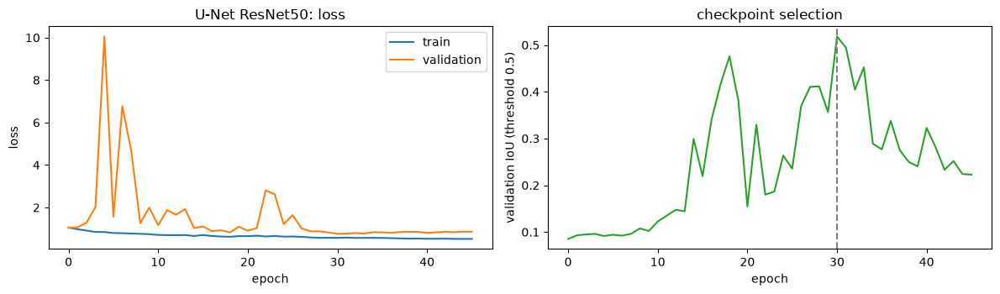

In [8]:
# Binôme C · Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets)
# Walid's improved recipe (section text above):
# - at most 80 epochs, with early stopping after 15 epochs without a better validation IoU;
# - batch 8: measured peak 4.6 GB at 352x640, within the 6 GB budget of the RTX 2060;
R50_EPOCHS, R50_BATCH, R50_PATIENCE = 80, 8, 15
steps = int(np.ceil(len(x_train) / R50_BATCH)) * R50_EPOCHS   # 6 steps per epoch x 80 epochs
# - learning rate 3e-4, lower than the 1e-3 used from scratch, as usual when fine-tuning pretrained weights,
#   decayed along a cosine down to 1e-6;
schedule = keras.optimizers.schedules.CosineDecay(3e-4, steps, alpha=1e-6 / 3e-4)
keras.utils.set_random_seed(SEED)
# - loss focal + focal-Tversky (alpha 0.3, beta 0.7, gamma 0.75): the focal term spends less effort on the many
#   easy background pixels, and the Tversky term penalises a missed obstacle pixel (beta) more than a false alarm
#   (alpha), to raise recall;
# - AdamW with weight decay 1e-4, and clipnorm=1.0 caps the size of each gradient step while the 30 M weights
#   (most of them pretrained) are fine-tuned. The encoder's BatchNorm statistics stay frozen: batches of 8 are
#   too small to re-estimate them
unet_r50, r50_history = train("C_unet_resnet50", build_unet_resnet50((*IMG_SIZE, 3)), losses.focal_plus_tversky_loss,
                              keras.optimizers.AdamW(schedule, weight_decay=1e-4, clipnorm=1.0),
                              R50_EPOCHS, R50_BATCH, patience=R50_PATIENCE)
print(f"trainable parameters: {sum(int(np.prod(w.shape)) for w in unet_r50.trainable_weights):,}")
plot_history(r50_history, "U-Net ResNet50", "C_03_unet_resnet50_training.png")

In [9]:
# Binôme C · Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets)
# Flip test-time augmentation (the mean of the predictions for the photograph and its mirror image), kept only
# if it raises the validation AuPRC by more than KEEP_MARGIN (0.002, the seed noise)
plain, with_tta = probabilities(unet_r50, x_val), probabilities(unet_r50, x_val, tta=True)
auprc_plain, auprc_tta = pp.auprc(gt_val, plain), pp.auprc(gt_val, with_tta)
USE_TTA = auprc_tta > auprc_plain + KEEP_MARGIN
print(f"validation AuPRC: without TTA {auprc_plain:.4f} | with flip-TTA {auprc_tta:.4f} -> TTA kept: {USE_TTA}")
r50_result = calibrate(with_tta if USE_TTA else plain)
save("C_unet_resnet50", unet_r50, "U-Net with ImageNet ResNet50 encoder", r50_result,
     {"author": "Walid (ResNet34 in the original, ResNet50 here)", "loss": "focal + focal-Tversky (0.3, 0.7, 0.75)",
      "optimizer": "AdamW 3e-4, wd 1e-4, cosine to 1e-6, clipnorm 1.0", "max_epochs": R50_EPOCHS,
      "epochs_ran": len(r50_history["loss"]), "patience": R50_PATIENCE, "batch_size": R50_BATCH,
      "best_epoch": int(np.argmax(r50_history["val_iou"])) + 1, "encoder": "ResNet50 ImageNet, BatchNorm frozen"},
     tta=bool(USE_TTA))

validation AuPRC: without TTA 0.7003 | with flip-TTA 0.7279 -> TTA kept: True


saved models/C_unet_resnet50


#### 4. The three C models on validation
The shared report is used, with the same threshold rule for all three models. This table compares C's models with each other; A, B and C are compared on the test split in notebook 5.

In [10]:
# Binôme C · Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets)
results = {"CNN baseline (Hejer)": cnn_result, "U-Net from scratch (Walid)": unet_result,
           "U-Net ResNet50 (Walid)": r50_result}
table = pd.DataFrame({name: {**evaluation.summary(r["free"], r["report"]), "threshold": round(r["threshold"], 3)}
                      for name, r in results.items()})
table

,CNN baseline (Hejer),U-Net from scratch (Walid),U-Net ResNet50 (Walid)
AuPRC (main),0.41053,0.452569,0.727943
AUROC,0.905192,0.910704,0.914745
AUPRO@0.3,0.649404,0.707502,0.706482
FPR95 (lower is better),0.263867,0.360878,0.64515
F1 = Dice (per-image mean),0.502924,0.461488,0.642578
IoU (per-image mean),0.38194,0.364414,0.538199
precision (per-image mean),0.449695,0.409851,0.674884
recall (per-image mean),0.648364,0.582213,0.716533
F1 (aggregated),0.508552,0.558826,0.71045
Boundary IoU (15 px band),0.299457,0.268057,0.427988


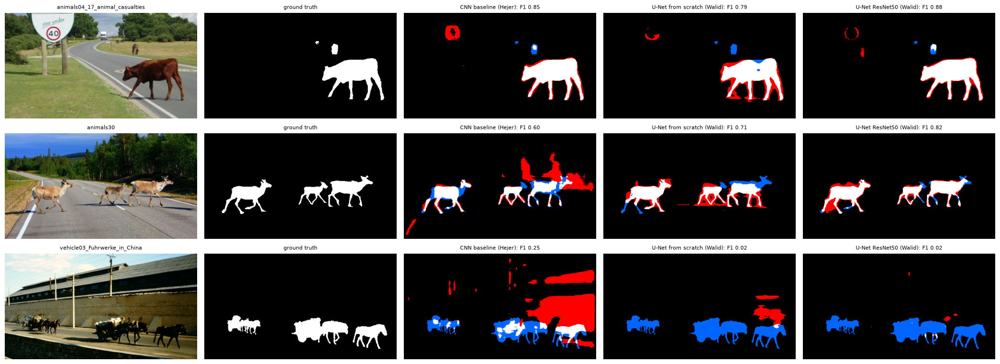

In [11]:
# Binôme C · Hejer Mnejja (CNN baseline) & Walid Fehry (U-Nets)
# Validation examples (first, middle, last): white = found, red = false alarm, blue = missed
def error_overlay(truth, pred):
    errors = np.zeros((*truth.shape, 3), np.float32)
    errors[truth & pred] = (1, 1, 1)
    errors[~truth & pred] = (1, 0, 0)
    errors[truth & ~pred] = (0, 0.4, 1)
    return errors

indices = [0, len(x_val) // 2, len(x_val) - 1]
fig, ax = plt.subplots(
    len(indices), 2 + len(results), figsize=(4.2 * (2 + len(results)), 2.6 * len(indices)), tight_layout=True
)
for row, i in enumerate(indices):
    ax[row, 0].imshow(x_val[i])
    ax[row, 0].set_title(val_frames[i][:30], fontsize=8)
    ax[row, 1].imshow(gt_val[i], cmap="gray")
    ax[row, 1].set_title("ground truth", fontsize=8)
    for col, (name, r) in enumerate(results.items(), start=2):
        mask = pp.to_masks(r["prob"][i:i + 1], r["threshold"], r["min_blob"])[0].astype(bool)
        ax[row, col].imshow(error_overlay(gt_val[i], mask))
        ax[row, col].set_title(f"{name}: F1 {r['report']['pixel']['per_image'][i]['f1']:.2f}", fontsize=8)
for a in ax.flat:
    a.axis("off")
plt.savefig(FIG_DIR / "C_04_validation_examples.png", dpi=55)
plt.show()

#### 5. Findings of the modeling phase (validation)
| Model (validation, shared protocol) | AuPRC | AUPRO@0.3 | F1 (per-image mean) | Objects found | Small objects | False alarms / blobs |
|---|---|---|---|---|---|---|
| CNN baseline (Hejer) | 0.411 | 0.649 | 0.503 | 27/36 | 7/12 | 132/199 |
| U-Net from scratch (Walid) | 0.453 | 0.708 | 0.461 | 26/36 | 9/12 | 33/47 |
| U-Net ResNet50 + flip-TTA (Walid) | **0.728** | 0.706 | **0.643** | 17/36 | 2/12 | 36/80 |

- **Skip connections help where they should.** The U-Net from scratch has a higher AuPRC and AUPRO than the CNN and four times fewer false-alarm blobs, and finds more small obstacles (9/12 vs 7/12): the encoder features of full resolution bring back the detail that pooling removes. The two recipes also differ (1.9 M against 0.19 M weights, Adam against AdamW with a cosine schedule, 50 against 80 epochs), so this is consistent with the effect of the skips, not an isolated ablation. Its per-image F1 on validation is lower, because its probabilities saturate (threshold 0.952); on the test split it is established as better than the CNN (notebook 5).
- **The pretrained encoder is decisive.** With an ImageNet ResNet50 encoder, the U-Net gains about 0.28 AuPRC; with 42 training photographs, learning features from scratch is the bottleneck, as Hejer's ResNet18 experiment already suggested. Flip test-time augmentation added 0.028 AuPRC on validation and was kept.
- **What the pretrained U-Net loses: small obstacles** (2/12 on validation). A likely reason, not tested here: its deep encoder stages see the image at 1/16 and 1/32 of its size, where a small obstacle is only a pixel or two.
- **Not comparable with the original runs.** Walid's ResNet34 U-Net reached a validation IoU of 0.815 on his own split; here the ResNet50 version reaches 0.518 at threshold 0.5. The difference most likely comes from the split (his was not group-aware, so frames of the same scene could be in both train and validation); the encoder also differs (ResNet34 is not in Keras), so the two runs cannot be compared directly.

The test evaluation of the three C models, next to A and B, is in [`../5_Evaluation.ipynb`](5_Evaluation.ipynb); their paired explanations (Grad-CAM++ and exact SHAP) in [`../6_XAI.ipynb`](6_XAI.ipynb).

In [ ]:
# End of 4 · Modeling, Binôme C: clean up before the next phase (cell added by scripts/build_master_notebook.py).
# The namespace and the Keras session are cleared, so the next phase starts as in its own kernel. TensorFlow
# settings of the process (GPU memory configuration, deterministic GPU kernels) stay for the whole kernel.
%reset -f
import gc

import keras

keras.backend.clear_session()
gc.collect()

# 5 · Evaluation — the three approaches on the frozen test split

**CRISP-DM phase 5.**

This is the **only notebook that loads the test split**. Every model saved in `models/` (the shared format of README rule 2) is evaluated once, with the settings frozen on validation in its modeling notebook, through the same `inference.Predictor` and the same `evaluation` report. Nothing is tuned here: if a result is disappointing, it is reported, not fixed.

**Earlier looks at the test split (disclosure).** The test images were evaluated before this notebook existed:

| Model | Earlier test evaluations | Where |
|---|---|---|
| A — DeepLabV3+ | 1 (Ines's original run); the test images had also been scored by an earlier CamVid model | `archive/A_deeplabv3plus_original_run_ines.ipynb` |
| B — pixel AE | 2 (ReLU code, then linear code) + Khaled's historical evaluation | `archive/B_feature_ae_and_backbone_study_adrian.ipynb`, `archive/B_pixel_ae_final_evaluation_khaled.ipynb` |
| B — feature AE | 1 | `archive/B_feature_ae_and_backbone_study_adrian.ipynb` |
| C — U-Nets (Walid) | 2, on Walid's own split (U-Net from scratch, U-Net ResNet34), before the port to the shared split | `archive/C_unet_original_run_walid.ipynb` |
| C — CNN (Hejer) | 0 | `archive/C_cnn_original_run_hejer.ipynb` |

No setting of the models below was changed because of those results (each change is documented with its validation evidence in the modeling notebooks), but the test set is not a perfectly untouched holdout and is reported as such.

**Business success criteria**, fixed in [`1_Business_Understanding.md`](1_Business_Understanding.md) before this run, are checked in section 6.

### TL;DR — the exam, taken once

**The exam.** Nine sealed photographs with 22 obstacles, all six models, every setting frozen on validation beforehand. Nothing is tuned after looking.

| Model | Test F1 [95 % interval] | Obstacles found | False alarms / blobs | Business tests passed |
|---|---|---|---|---|
| DeepLabV3+ (A) | **0.739** [0.62, 0.84] | **20/22** | 38/67 | 3 of 4 |
| U-Net ResNet50 (C) | 0.708 [0.59, 0.81] | 16/22 | 64/93 | 3 of 4 |
| Feature autoencoder (B) | 0.623 [0.51, 0.73] | 16/22 | **10/22** | **4 of 4** |
| U-Net from scratch (C) | 0.447 [0.35, 0.54] | 10/22 | 80/117 | 2 of 4 |
| CNN baseline (C) | 0.340 [0.23, 0.44] | 9/22 | 155/219 | 2 of 4 |
| Pixel autoencoder (B) | 0.248 [0.12, 0.39] | 16/22 | 40/45 | 2 of 4 |

**How to read the intervals.** With 9 photographs, luck matters: one easy photo more and a model looks better. The bootstrap redraws the 9 photographs 2,000 times (with repeats) and watches how much the score moves. The **paired** version compares two models on the same redraw, so a hard photo hurts both and cancels out. A difference counts only if its interval stays on one side of zero.

1. **A three-way tie at the top.** DeepLabV3+ leads the pretrained U-Net by +0.030 F1 [−0.010, 0.081] and the feature autoencoder by +0.115 [−0.030, 0.256]: both intervals cross zero, so no winner is declared. Each of the three is clearly better than each of the bottom three.
2. **Pretrained ImageNet features are the dividing line.** The three models that look at the image through an ImageNet network (as their encoder or as their input) score F1 ≥ 0.62; the three whose network learned to see from our 42 photographs alone score ≤ 0.45 (the pixel autoencoder uses VGG19 only inside its training loss).
3. **They fail differently.** The supervised models find the most obstacles (20/22 for DeepLabV3+) but sprinkle small false-alarm blobs, so fewer than half of their warnings are right (SC2 fails). The feature autoencoder drops blobs under 256 px, so 12 of its 22 warnings are right: it is the **only model that passes all four business tests**.
4. **Speed is not a problem:** 13–48 ms per photograph on a laptop RTX 4060 (the test needs < 100 ms).

**Recommendation.** DeepLabV3+ by default (the most accurate and among the fastest, 21 ms); the feature autoencoder where a false alarm is expensive.

### 0. Setup

In [1]:
# Import libraries
import os

# hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import json
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

import keras
import tensorflow as tf

tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

import warnings

from roadanomaly import data_pipeline as dp
from roadanomaly import evaluation
from roadanomaly import postprocessing as pp
from roadanomaly.gpu import setup_gpu
from roadanomaly.inference import Predictor, available_models
from roadanomaly.protocol import IMG_SIZE, SEED

warnings.filterwarnings('ignore')

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
GPU_NAME = setup_gpu()
FIG_DIR = dp.FIG_DIR
RESULTS_DIR = dp.REPO_ROOT / "reports" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)


### 1. The models and a check before the test
Each model must give back, from its saved files, the validation AuPRC its modeling notebook recorded (to within 0.001: float32 GPU kernels reorder the many tied pixels of saturated sigmoids by about 0.0001, while a wrong model or post-processing moves it far more). This proves the saved model, its preprocessing and its post-processing are exactly those that were selected, before any test image is loaded.

In [2]:
MODEL_NAMES = available_models(dp.MODELS_DIR)
predictors = {name: Predictor(dp.MODELS_DIR / name) for name in MODEL_NAMES}
missing = [b for b in "ABC" if not any(p.config["binome"] == b for p in predictors.values())]
print("Models found:", MODEL_NAMES)
if missing:
    print("Not delivered yet (no folder in models/):", ["Binôme " + b for b in missing])

_, x_val, y_val = dp.load_split("val", IMG_SIZE)
gt_val = y_val[..., 0].astype(bool)
# Tolerance: models whose sigmoid saturates at exactly 1.0 have many tied pixels, and float32 GPU kernels
# (batch size, deterministic cuDNN algorithms) reorder those ties, moving AuPRC by ~1e-4. A wrong model,
# preprocessing or post-processing moves it by far more than 1e-3.
TOLERANCE = 1e-3
check = {}
for name, predictor in predictors.items():
    recorded = predictor.config["validation"]["AuPRC"]
    reproduced = pp.auprc(gt_val, predictor.score_maps(x_val))
    check[name] = {"recorded val AuPRC": recorded, "reproduced": reproduced, "difference": abs(recorded - reproduced)}
    assert abs(recorded - reproduced) < TOLERANCE, f"{name}: the saved model does not reproduce its validation score"
pd.DataFrame(check).T.round(6)

I0000 00:00:1793565177.204433 3216001 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6249 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Models found: ['A_deeplabv3plus', 'B_feature_ae', 'B_pixel_ae', 'C_cnn', 'C_unet', 'C_unet_resnet50']


,recorded val AuPRC,reproduced,difference
A_deeplabv3plus,0.753624,0.753624,0.000000
B_feature_ae,0.596010,0.596010,0.000000
B_pixel_ae,0.157301,0.157301,0.000000
C_cnn,0.410530,0.410531,0.000000
C_unet,0.452569,0.452675,0.000106
C_unet_resnet50,0.727943,0.727690,0.000253


### 2. Test evaluation (once)

In [3]:
test_frames, x_test, y_test = dp.load_split("test", IMG_SIZE)
gt_test = y_test[..., 0].astype(bool)
print(f"test: {len(test_frames)} images | anomaly prevalence {gt_test.mean():.4f} (AuPRC chance level)")

results = {}
for name, predictor in predictors.items():
    out = predictor.predict(x_test)
    results[name] = {"scores": out["scores"], "masks": out["masks"],
                     "free": evaluation.threshold_free_scores(gt_test, out["scores"]),
                     "report": evaluation.mask_report(gt_test, out["masks"])}
    val_out = predictor.predict(x_val)
    results[name]["val_free"] = evaluation.threshold_free_scores(gt_val, val_out["scores"])
    results[name]["val_report"] = evaluation.mask_report(gt_val, val_out["masks"])

title = {name: f"{p.config['binome']}: {p.config['title']}" for name, p in predictors.items()}
test_table = pd.DataFrame({title[n]: evaluation.summary(r["free"], r["report"]) for n, r in results.items()})
test_table.loc["AuPRC chance (prevalence)"] = gt_test.mean()
test_table

test: 9 images | anomaly prevalence 0.0859 (AuPRC chance level)


,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),B: Feature-space autoencoder on frozen VGG16 block5_conv3,"B: Pixel autoencoder (mae_vgg19 loss), baseline","C: CNN baseline (encoder-decoder, no skips)",C: U-Net from scratch,C: U-Net with ImageNet ResNet50 encoder
AuPRC (main),0.754601,0.631239,0.177529,0.352574,0.378494,0.686802
AUROC,0.964664,0.921758,0.676064,0.818376,0.868656,0.924826
AUPRO@0.3,0.899617,0.822724,0.503121,0.491579,0.684444,0.843764
FPR95 (lower is better),0.143854,0.44238,0.978125,0.563028,0.440452,0.533457
F1 = Dice (per-image mean),0.738747,0.623388,0.247633,0.339939,0.44725,0.708449
IoU (per-image mean),0.612923,0.47386,0.159458,0.216277,0.297905,0.569842
precision (per-image mean),0.717555,0.590333,0.180957,0.40341,0.559998,0.731378
recall (per-image mean),0.845606,0.769278,0.503058,0.417628,0.477456,0.777535
F1 (aggregated),0.74568,0.617737,0.244356,0.366147,0.447202,0.708771
Boundary IoU (15 px band),0.475897,0.235924,0.073142,0.182008,0.239167,0.446015


**How to read it.** AuPRC is the main ranking metric for score maps (chance = prevalence); AUROC looks good too easily on imbalanced pixels (chance 0.5); AUPRO weighs every obstacle the same up to FPR 0.3. F1 = Dice and IoU are per-image means of the thresholded masks. Boundary IoU (15-px band) and HD95 (px, lower is better) judge the outlines. The validation column below shows whether the settings chosen on validation transfer to unseen scenes.

In [4]:
# Validation vs test: do the choices made on validation transfer?
rows = {}
for name, r in results.items():
    rows[title[name]] = {"val AuPRC": r["val_free"]["AuPRC"], "test AuPRC": r["free"]["AuPRC"],
                         "val F1": r["val_report"]["pixel"]["per_image_mean"]["f1"],
                         "test F1": r["report"]["pixel"]["per_image_mean"]["f1"]}
pd.DataFrame(rows).T.round(3)

,val AuPRC,test AuPRC,val F1,test F1
A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),0.754,0.755,0.695,0.739
B: Feature-space autoencoder on frozen VGG16 block5_conv3,0.596,0.631,0.575,0.623
"B: Pixel autoencoder (mae_vgg19 loss), baseline",0.157,0.178,0.249,0.248
"C: CNN baseline (encoder-decoder, no skips)",0.411,0.353,0.503,0.340
C: U-Net from scratch,0.453,0.378,0.462,0.447
C: U-Net with ImageNet ResNet50 encoder,0.728,0.687,0.642,0.708


### 3. Uncertainty: bootstrap intervals and paired comparisons
With 9 test images, a single mean hides a large uncertainty. Each model gets 95 % bootstrap intervals over images; each **pair** of models gets a paired bootstrap interval of the per-image difference (same images, so image difficulty cancels out). A difference is established only when its interval excludes 0.

In [5]:
ci_rows = []
for name, r in results.items():
    table = evaluation.bootstrap_table(r["report"])
    table.insert(0, "model", title[name])
    ci_rows.append(table)
pd.concat(ci_rows).round(3).reset_index(drop=True)

,model,metric,mean,low,high
0,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),pixel f1,0.739,0.622,0.842
1,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),pixel iou,0.613,0.480,0.735
2,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),pixel precision,0.718,0.596,0.824
3,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),pixel recall,0.846,0.684,0.952
4,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),object f1,0.597,0.432,0.755
5,B: Feature-space autoencoder on frozen VGG16 b...,pixel f1,0.623,0.506,0.729
6,B: Feature-space autoencoder on frozen VGG16 b...,pixel iou,0.474,0.355,0.583
7,B: Feature-space autoencoder on frozen VGG16 b...,pixel precision,0.590,0.463,0.698
8,B: Feature-space autoencoder on frozen VGG16 b...,pixel recall,0.769,0.617,0.903
9,B: Feature-space autoencoder on frozen VGG16 b...,object f1,0.669,0.424,0.878


In [6]:
pair_rows = []
for a, b in combinations(results, 2):
    for key in ["f1", "iou"]:
        va = [s[key] for s in results[a]["report"]["pixel"]["per_image"]]
        vb = [s[key] for s in results[b]["report"]["pixel"]["per_image"]]
        mean, low, high = evaluation.paired_difference(va, vb)
        pair_rows.append({"A - B": f"{a} - {b}", "metric": f"per-image {key}", "mean difference": mean,
                          "95% low": low, "95% high": high, "established": "yes" if low > 0 or high < 0 else "no"})
pd.DataFrame(pair_rows).round(3)

,A - B,metric,mean difference,95% low,95% high,established
0,A_deeplabv3plus - B_feature_ae,per-image f1,0.115,-0.030,0.256,no
1,A_deeplabv3plus - B_feature_ae,per-image iou,0.139,-0.015,0.292,no
2,A_deeplabv3plus - B_pixel_ae,per-image f1,0.491,0.267,0.699,yes
3,A_deeplabv3plus - B_pixel_ae,per-image iou,0.453,0.251,0.638,yes
4,A_deeplabv3plus - C_cnn,per-image f1,0.399,0.229,0.539,yes
5,A_deeplabv3plus - C_cnn,per-image iou,0.397,0.236,0.533,yes
6,A_deeplabv3plus - C_unet,per-image f1,0.291,0.180,0.403,yes
7,A_deeplabv3plus - C_unet,per-image iou,0.315,0.194,0.434,yes
8,A_deeplabv3plus - C_unet_resnet50,per-image f1,0.030,-0.010,0.081,no
9,A_deeplabv3plus - C_unet_resnet50,per-image iou,0.043,-0.015,0.117,no


### 4. Per image: where each approach works and fails

In [7]:
per_image = pd.DataFrame({"frame": [f[:32] for f in test_frames],
                          "anomaly %": (100 * gt_test.mean(axis=(1, 2))).round(1),
                          "objects": results[MODEL_NAMES[0]]["report"]["objects"]["gt_objects"].values})
for name, r in results.items():
    per_image[f"{name} F1"] = [round(s["f1"], 3) for s in r["report"]["pixel"]["per_image"]]
    per_image[f"{name} found"] = r["report"]["objects"]["detected"].values
    per_image[f"{name} false alarms"] = r["report"]["objects"]["false_alarms"].values
per_image

,frame,anomaly %,objects,A_deeplabv3plus F1,A_deeplabv3plus found,A_deeplabv3plus false alarms,B_feature_ae F1,B_feature_ae found,B_feature_ae false alarms,B_pixel_ae F1,...,B_pixel_ae false alarms,C_cnn F1,C_cnn found,C_cnn false alarms,C_unet F1,C_unet found,C_unet false alarms,C_unet_resnet50 F1,C_unet_resnet50 found,C_unet_resnet50 false alarms
0,animals14_Dekemhare_Road,10.0,2,0.839,2,4,0.763,2,0,0.098,...,3,0.525,2,21,0.624,2,11,0.750,2,3
1,animals17_E6_near_Kvaenangen,1.6,1,0.728,1,3,0.447,1,3,0.138,...,1,0.279,0,11,0.509,1,5,0.726,1,9
2,animals20_Marcassin_Conchiglio,4.3,1,0.814,1,15,0.772,1,0,0.013,...,3,0.278,1,18,0.550,0,1,0.818,1,17
3,animals21_On_The_Road_to_Gondar_,15.2,2,0.632,2,4,0.659,1,0,0.468,...,11,0.469,2,31,0.441,2,11,0.675,2,16
4,animals29_Zebra_Crossing_Abbey_R,7.0,2,0.858,2,3,0.697,2,0,0.599,...,1,0.123,0,6,0.422,1,11,0.801,2,1
5,cones06_VnA_traffic_cones,5.0,6,0.563,6,5,0.339,4,4,0.263,...,4,0.029,1,38,0.150,1,24,0.579,3,10
6,obstacles09_boulder3,5.1,1,0.910,1,0,0.825,1,0,0.000,...,4,0.446,0,9,0.598,0,0,0.940,1,0
7,obstacles10_boulder4,19.1,3,0.925,2,2,0.399,1,1,0.135,...,5,0.393,0,5,0.322,0,5,0.735,1,6
8,vehicle02_Broadmoor_Cones_Skidlo,10.0,4,0.379,3,2,0.710,3,2,0.514,...,8,0.517,3,16,0.410,3,12,0.351,3,2


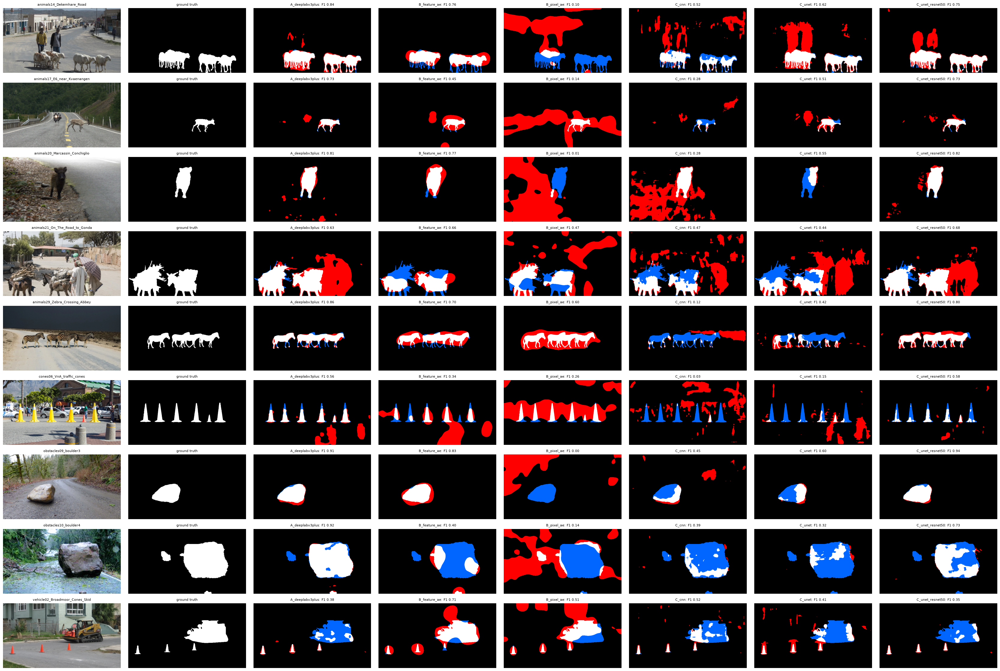

In [8]:
# Every test image: image | ground truth | prediction of each model (TP white, FP red, FN blue)
def error_overlay(truth, pred):
    errors = np.zeros((*truth.shape, 3), np.float32)
    errors[truth & pred] = (1, 1, 1)
    errors[~truth & pred] = (1, 0, 0)
    errors[truth & ~pred] = (0, 0.4, 1)
    return errors

n_cols = 2 + len(results)
fig, ax = plt.subplots(len(test_frames), n_cols, figsize=(4.2 * n_cols, 2.5 * len(test_frames)), tight_layout=True)
for i, frame in enumerate(test_frames):
    ax[i, 0].imshow(x_test[i])
    ax[i, 0].set_title(frame[:30], fontsize=8)
    ax[i, 1].imshow(gt_test[i], cmap="gray")
    ax[i, 1].set_title("ground truth", fontsize=8)
    for j, (name, r) in enumerate(results.items(), start=2):
        ax[i, j].imshow(error_overlay(gt_test[i], r["masks"][i].astype(bool)))
        ax[i, j].set_title(f"{name}: F1 {r['report']['pixel']['per_image'][i]['f1']:.2f}", fontsize=8)
for a in ax.flat:
    a.axis("off")
plt.savefig(FIG_DIR / "5_01_test_predictions.png", dpi=55)
plt.show()

### 5. Cost, complexity and data needs
FR asks to compare the approaches also on computation, complexity and the training data they need. Latency is the full `Predictor.predict` (score map + mask, post-processing included) on this notebook's GPU, batch of 9 images; it is a measurement, not a real-time promise.

In [9]:
cost = {}
for name, predictor in predictors.items():
    model = predictor.model
    trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    total = model.count_params()
    if predictor.model_type == "feature_autoencoder":   # the frozen backbone runs too
        from roadanomaly.models.feature_ae import get_extractor
        total += get_extractor(predictor.backbone, predictor.layer).count_params()
    cost[title[name]] = {
        "parameters, total (M)": total / 1e6, "trained parameters (M)": trainable / 1e6,
        "model file (MB)": (predictor.directory / predictor.config["model_file"]).stat().st_size / 1e6,
        f"latency (ms / image, {GPU_NAME})": evaluation.latency_ms(predictor.predict, x_test),
        "training labels needed": "pixel masks" if predictor.model_type == "segmentation"
                                  else "normal regions only (masks used to exclude obstacles)",
    }
cost_table = pd.DataFrame(cost).T
cost_table.round(2)

,"parameters, total (M)",trained parameters (M),model file (MB),"latency (ms / image, NVIDIA GeForce RTX 4060 Laptop GPU)",training labels needed
A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),12.838721,4.247649,51.997426,21.082778,pixel masks
B: Feature-space autoencoder on frozen VGG16 block5_conv3,16.04692,1.332232,16.020657,39.672716,normal regions only (masks used to exclude obs...
"B: Pixel autoencoder (mae_vgg19 loss), baseline",0.786053,0.786053,3.193364,26.486059,normal regions only (masks used to exclude obs...
"C: CNN baseline (encoder-decoder, no skips)",0.186225,0.185553,0.847846,12.872058,pixel masks
C: U-Net from scratch,1.946993,1.944049,8.03855,15.624219,pixel masks
C: U-Net with ImageNet ResNet50 encoder,30.550753,30.442529,122.998646,48.477373,pixel masks


### 6. Business success criteria
The criteria of [`1_Business_Understanding.md`](1_Business_Understanding.md) (section 4), checked on the test split:
- **SC1 — better than doing nothing smart:** the lower bound of the 95 % interval of the per-image F1 is above the "all anomaly" baseline on test.
- **SC2 — useful warnings:** more than half of the predicted blobs are real obstacles (object precision over all blobs > 0.5), so an alert is more often right than wrong.
- **SC3 — obstacles found:** at least half of the annotated obstacles are detected (object recall over all objects ≥ 0.5).
- **SC4 — demonstrable:** inference under 100 ms per image on a laptop GPU (≥ 10 images per second, enough for the demo and frame-by-frame video).

In [10]:
baseline_f1 = evaluation.trivial_baselines(gt_test)["all anomaly"]["f1"]
criteria = {}
for name, r in results.items():
    objects = r["report"]["objects"]
    low_f1 = evaluation.bootstrap_table(r["report"]).set_index("metric").loc["pixel f1", "low"]
    precision = 1 - objects["false_alarms"].sum() / max(objects["pred_objects"].sum(), 1)
    recall = objects["detected"].sum() / objects["gt_objects"].sum()
    latency = cost[title[name]][f"latency (ms / image, {GPU_NAME})"]
    criteria[title[name]] = {
        "SC1 F1 low bound > all-anomaly": (
            f"{low_f1:.3f} > {baseline_f1:.3f}: {'pass' if low_f1 > baseline_f1 else 'FAIL'}"
        ),
        "SC2 object precision > 0.5": f"{precision:.2f}: {'pass' if precision > 0.5 else 'FAIL'}",
        "SC3 object recall >= 0.5": f"{recall:.2f}: {'pass' if recall >= 0.5 else 'FAIL'}",
        "SC4 latency < 100 ms": f"{latency:.0f} ms: {'pass' if latency < 100 else 'FAIL'}",
    }
pd.DataFrame(criteria)

,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),B: Feature-space autoencoder on frozen VGG16 block5_conv3,"B: Pixel autoencoder (mae_vgg19 loss), baseline","C: CNN baseline (encoder-decoder, no skips)",C: U-Net from scratch,C: U-Net with ImageNet ResNet50 encoder
SC1 F1 low bound > all-anomaly,0.622 > 0.154: pass,0.506 > 0.154: pass,0.118 > 0.154: FAIL,0.230 > 0.154: pass,0.351 > 0.154: pass,0.594 > 0.154: pass
SC2 object precision > 0.5,0.43: FAIL,0.55: pass,0.11: FAIL,0.29: FAIL,0.32: FAIL,0.31: FAIL
SC3 object recall >= 0.5,0.91: pass,0.73: pass,0.73: pass,0.41: FAIL,0.45: FAIL,0.73: pass
SC4 latency < 100 ms,21 ms: pass,40 ms: pass,26 ms: pass,13 ms: pass,16 ms: pass,48 ms: pass


### 7. Save the results
Every number of this notebook is written to `reports/results/` (tracked in git), so the report, the README and the demo quote the same values.

In [11]:
def jsonable(report):
    return {"pixel": report["pixel"], "objects": report["objects"].to_dict(orient="list"), "sizes": report["sizes"],
            "boundary": report["boundary"], "confusion": report["confusion"]}

saved = {"split": "test", "frames": test_frames, "environment": {"gpu": GPU_NAME, "tensorflow": tf.__version__},
         "models": {name: {"title": title[name], "binome": predictors[name].config["binome"],
                           "model_type": predictors[name].model_type, "config": predictors[name].config,
                           "threshold_free": r["free"], "summary": evaluation.summary(r["free"], r["report"]),
                           "bootstrap": evaluation.bootstrap_table(r["report"]).to_dict(orient="records"),
                           "criteria": criteria[title[name]], "cost": cost[title[name]],
                           "report": jsonable(r["report"]), "validation_threshold_free": r["val_free"]}
                    for name, r in results.items()},
         "paired_differences": pair_rows}
(RESULTS_DIR / "test_results.json").write_text(json.dumps(saved, indent=2, default=float), encoding="utf-8")
test_table.to_csv(RESULTS_DIR / "test_summary.csv")
pd.DataFrame(pair_rows).to_csv(RESULTS_DIR / "test_paired_differences.csv", index=False)
cost_table.to_csv(RESULTS_DIR / "cost.csv")
print("saved:", sorted(p.name for p in RESULTS_DIR.iterdir()))

saved: ['cost.csv', 'test_paired_differences.csv', 'test_results.json', 'test_summary.csv']


### 8. Conclusions
**Ranking (per-image mean F1 on the 9 test photographs, 95 % bootstrap interval).**

| Model | Test AuPRC | Test F1 [95 % CI] | Obstacles found | False alarms / blobs | Business criteria met |
|---|---|---|---|---|---|
| A — DeepLabV3+ | **0.755** | **0.739** [0.62, 0.84] | 20/22 | 38/67 | 3 of 4 (fails SC2) |
| C — U-Net ResNet50 | 0.687 | 0.708 [0.59, 0.81] | 16/22 | 64/93 | 3 of 4 (fails SC2) |
| B — feature autoencoder | 0.631 | 0.623 [0.51, 0.73] | 16/22 | 10/22 | **4 of 4** |
| C — U-Net from scratch | 0.378 | 0.447 [0.35, 0.54] | 10/22 | 80/117 | 2 of 4 |
| C — CNN baseline | 0.353 | 0.340 [0.23, 0.44] | 9/22 | 155/219 | 2 of 4 |
| B — pixel autoencoder | 0.178 | 0.248 [0.12, 0.39] | 16/22 | 40/45 | 2 of 4 |

1. **No winner among the top three.** The paired bootstrap differences are not established: A − U-Net ResNet50 = +0.030 [−0.010, 0.081], A − feature AE = +0.115 [−0.030, 0.256], feature AE − U-Net ResNet50 = −0.085 [−0.199, 0.051]. Each of the three is established as better than the CNN baseline, the U-Net from scratch and the pixel autoencoder.
2. **Pretrained features decide.** The three models above 0.6 all build on frozen or fine-tuned ImageNet encoders; the models trained from scratch on 42 photographs stay below 0.45. For the autoencoders this is the finding of notebook 4/B: a Gaussian on the same features does about as well.
3. **Validation transferred for the strong models, not for the CNN.** A (0.695 → 0.739), the feature AE (0.575 → 0.623) and the U-Net ResNet50 (0.642 → 0.708) held up; the CNN baseline fell from 0.503 to 0.340, a sign that choosing its best epoch among 80 on nine validation photographs over-fitted the validation set.
4. **How they fail differs.** The supervised models find the most obstacles and draw the best outlines (Boundary IoU 0.48 for A) but scatter small false-alarm blobs, which is why they fail SC2 (object precision 0.43 and 0.31). The feature AE removes blobs under 256 px (chosen on validation), so most of its warnings are real, at the cost of coarse 16-px outlines and small obstacles. The pixel AE reacts to texture, not to objects.
5. **Cost is not a constraint.** Every model runs in 13–48 ms per photograph on the RTX 4060. The U-Net ResNet50 is the heaviest (30.4 M trained parameters, 123 MB); the feature AE needs no annotated obstacle to learn, only masks to exclude obstacles from its normal data.

**Recommendation.** For the demo, DeepLabV3+ by default (the most accurate and among the fastest); for a warning system where false alarms are costly, the feature autoencoder, the only model that meets all four business criteria. The next step that can be justified without touching the test set again: choose a minimum blob size on validation for the supervised models, as Binôme B did, to lower their false alarms.

**Caveats.** Nine test photographs and 22 obstacles, none of them small (small-object behaviour is judged on validation only); earlier looks at the test set are disclosed at the top of this notebook; RoadAnomaly is used here for training and testing, so these are not out-of-distribution benchmark scores.

In [ ]:
# End of 5 · Evaluation: clean up before the next phase (cell added by scripts/build_master_notebook.py).
# The namespace and the Keras session are cleared, so the next phase starts as in its own kernel. TensorFlow
# settings of the process (GPU memory configuration, deterministic GPU kernels) stay for the whole kernel.
%reset -f
import gc

import keras

keras.backend.clear_session()
gc.collect()

# 6 · Explainable AI — where each model looks, and what it relies on

**CRISP-DM phase 5 (Evaluation), XAI part.**

Every model is explained by a **pair of complementary methods**, always together:

| Question | Method | What it gives |
|---|---|---|
| **Where?** | **Grad-CAM++** (Chattopadhay et al., 2018), with Grad-CAM (Selvaraju et al., 2017) as a comparison | a heatmap of the image regions whose activations raise the model's score on the predicted region |
| **What?** | **SHAP, exact Shapley values** (Lundberg & Lee, 2017) over five interpretable image factors | how much each factor (colour, fine texture, brightness and contrast, the obstacle itself, the surrounding scene) contributes to that score |

**The target is the same for both**, a fixed scalar computed on the model's predicted region: the mean anomaly **logit** for the segmentation models (A, C), and the mean **reconstruction error** for the autoencoders (B; per 16-px cell for the feature AE). Explaining one number with two methods is what makes the pair coherent.

**How the "what" works.** A factor is removed by a defined transform: colour → grey luminance; fine texture → Gaussian blur (σ 2 px); brightness and contrast → contrast flattened to 35 %; the obstacle → the region filled with a heavy blur of its surroundings; the scene → everything outside the region heavily blurred. For one image, all 2⁵ = 32 combinations of kept and removed factors are scored, so the Shapley values are **exact** (no sampling) and add up to the score of the original image minus the score with every factor removed (the efficiency property, checked in section 6).

**Rules.** Validation images only. The region is fixed before any gradient or perturbation. Each half of the pair is tested: deletion / insertion for the maps (section 5), the efficiency identity for the Shapley values (section 6). An explanation describes a model; it is never used to choose one, and it never replaces a segmentation metric.

### TL;DR — a flashlight and a recipe

To trust a warning, we ask two questions about **one number**: the model's score on the region it flagged.

- **Where did the score come from? Grad-CAM++ is a flashlight.** It follows the gradients back to a deep layer and lights up the parts of the photograph that pushed the score up.
- **What is the score made of? Exact SHAP is a fair split of the credit.** We describe each photograph with five "ingredients": colour, fine texture, brightness and contrast, the obstacle itself, the surrounding scene. Each can be switched off by a stated transform (grey instead of colour, a light blur instead of texture, and so on). We score all 2⁵ = **32** on/off combinations and give each ingredient its average extra contribution, like splitting a taxi fare fairly between passengers who joined at different stops. Because every combination is computed, the shares add up **exactly** to the change in score (the largest gap over 54 explanations stays below 1e-13, float rounding).

**What we found.**
- **The flashlight points at the right place for 5 of 6 models.** Removing the blocks it ranks first lowers the score faster than random orders, and restoring them raises it faster. Grad-CAM++ even fixes the feature autoencoder, where plain Grad-CAM did worse than random (deletion area 65.5 against 31.3 for random orders, then 29.9 with Grad-CAM++). The U-Net trained from scratch fails with both methods.
- **Contrast is the main ingredient.** It is the largest factor for four models (37 % to 63 % of the credit), about 30 % or more for all six (just under 30 % for DeepLabV3+), and on every validation photograph it raises the score. RoadAnomaly's obstacles mostly stand out by contrast with the road.
- **Two exceptions tell the models apart.** DeepLabV3+ leans most on the **surrounding scene** (31 %): it judges an obstacle in its context. The pixel autoencoder leans most on **the obstacle itself** (38 %) and not at all on the scene (0 %).

**Limits.** The ingredients are defined by our transforms (another blur would give other numbers). The explanations describe what a model uses, they do not prove why. None of them was used to choose a model or a threshold.

### 0. Setup

In [1]:
# Import libraries
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")   # hide TensorFlow C++ log lines
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

import keras
import tensorflow as tf

tf.get_logger().setLevel("ERROR")

import warnings

from roadanomaly import data_pipeline as dp
from roadanomaly import evaluation, xai
from roadanomaly.gpu import setup_gpu
from roadanomaly.inference import Predictor, available_models
from roadanomaly.protocol import IMG_SIZE, SEED

warnings.filterwarnings('ignore')

keras.utils.set_random_seed(SEED)
GPU_NAME = setup_gpu()
FIG_DIR = dp.FIG_DIR
RESULTS_DIR = dp.REPO_ROOT / "reports" / "results"

predictors = {name: Predictor(dp.MODELS_DIR / name) for name in available_models(dp.MODELS_DIR)}
val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)
gt_val = y_val[..., 0].astype(bool)
outputs = {name: p.predict(x_val) for name, p in predictors.items()}
FACTORS, LABELS = xai.FACTORS, xai.FACTOR_LABELS
print("Models:", list(predictors))

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9) 


I0000 00:00:1793604473.761024 1239055 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4074 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


I0000 00:00:1793604489.823484 1240387 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Models: ['A_deeplabv3plus', 'B_feature_ae', 'B_pixel_ae', 'C_cnn', 'C_unet', 'C_unet_resnet50']


### 1. Common cases
The same two validation photographs are explained for every model: the **success** case (highest F1 averaged over the models) and the **failure** case (lowest), chosen from the validation scores only.

In [2]:
f1 = pd.DataFrame({name: [s["f1"] for s in evaluation.mask_report(gt_val, out["masks"])["pixel"]["per_image"]]
                   for name, out in outputs.items()}, index=[f[:30] for f in val_frames])
SUCCESS, FAILURE = int(np.argmax(f1.mean(axis=1).values)), int(np.argmin(f1.mean(axis=1).values))
print("success case:", val_frames[SUCCESS], "| failure case:", val_frames[FAILURE])
f1.round(3)

success case: animals04_17_animal_casualties_so_far_in_2006 | failure case: obstacles08_boulder2


,A_deeplabv3plus,B_feature_ae,B_pixel_ae,C_cnn,C_unet,C_unet_resnet50
animals04_17_animal_casualties,0.889,0.763,0.280,0.850,0.791,0.884
animals10_bovine_cattle_beside,0.918,0.736,0.407,0.667,0.000,0.918
animals19_Porte_de_Roubaix,0.584,0.676,0.206,0.287,0.359,0.577
animals27_wildlife_bear,0.938,0.537,0.037,0.852,0.864,0.956
animals30,0.827,0.633,0.344,0.602,0.708,0.818
cones01_Beeston_MMB_A6_Middle_,0.641,0.242,0.209,0.316,0.636,0.691
obstacles07_czech_hedgehog,0.307,0.569,0.422,0.682,0.762,0.682
obstacles08_boulder2,0.358,0.343,0.109,0.026,0.017,0.239
vehicle03_Fuhrwerke_in_China,0.794,0.677,0.225,0.245,0.017,0.017


### 2. The paired explanation of every model
`xai.explain(predictor, image)` returns the predicted region, the **where** map (Grad-CAM++) and the **what** attribution (exact Shapley values). The same function serves this notebook, the API (`POST /explain`) and the demo, so all three show the same explanation.

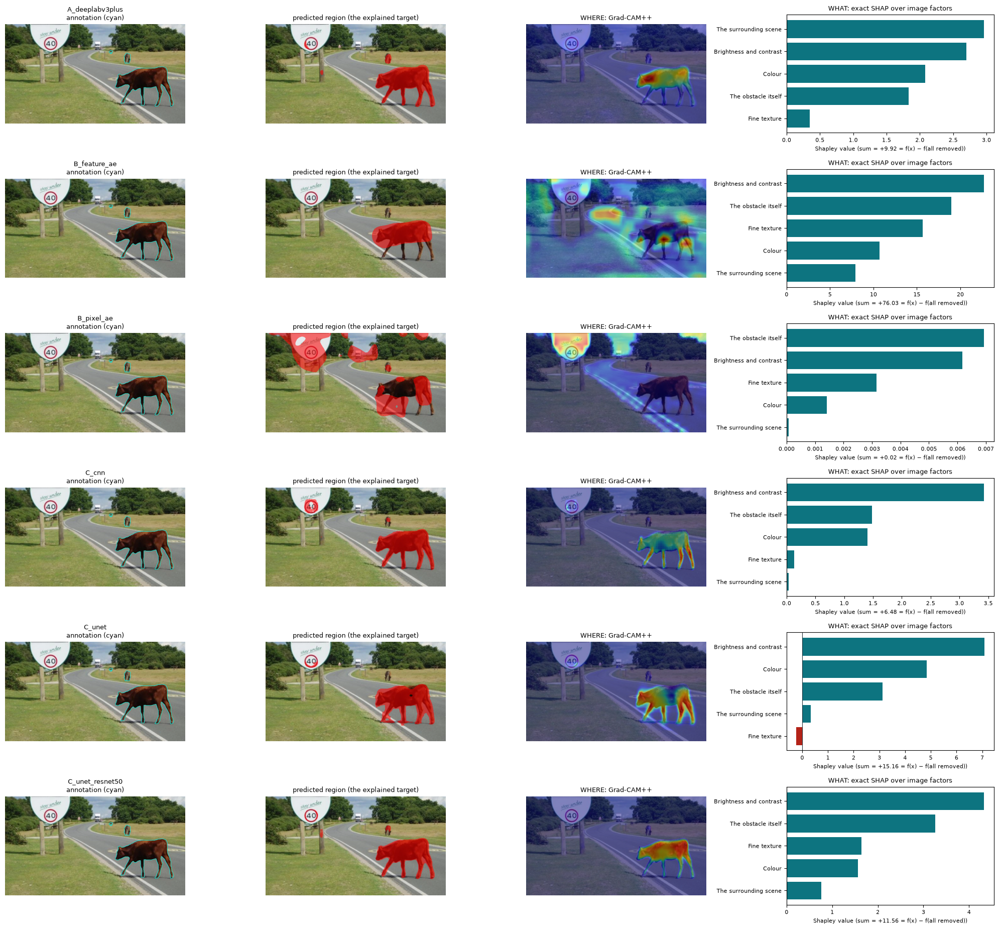

In [3]:
pairs = {(name, idx): xai.explain(p, x_val[idx], method="gradcam++")
         for name, p in predictors.items() for idx in (SUCCESS, FAILURE)}

def shap_bars(ax, what, title):
    """Horizontal bars of the Shapley values, largest magnitude first (teal raises the score, red lowers it)."""
    items = sorted(what["phi"].items(), key=lambda kv: abs(kv[1]))
    values = [v for _, v in items]
    ax.barh([LABELS[k] for k, _ in items], values, color=["#0d7480" if v >= 0 else "#b42318" for v in values])
    ax.axvline(0, color="#1f3038", linewidth=0.8)
    ax.set_title(title, fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set_xlabel(f"Shapley value (sum = {sum(values):+.2f} = f(x) − f(all removed))", fontsize=8)

def board(idx, path):
    fig, ax = plt.subplots(len(predictors), 4, figsize=(20, 3.1 * len(predictors)), squeeze=False,
                           gridspec_kw={"width_ratios": [1, 1, 1, 1.15]}, tight_layout=True)
    for row, name in enumerate(predictors):
        e = pairs[(name, idx)]
        ax[row, 0].imshow(x_val[idx])
        ax[row, 0].contour(gt_val[idx].astype(float), levels=[0.5], colors="#2fd3c4", linewidths=0.8)
        ax[row, 0].set_title(f"{name}\nannotation (cyan)", fontsize=9)
        ax[row, 1].imshow(x_val[idx])
        ax[row, 1].imshow(np.ma.masked_where(~e["region"], e["region"]), cmap="autumn", alpha=0.55)
        ax[row, 1].set_title("predicted region (the explained target)", fontsize=9)
        ax[row, 2].imshow(x_val[idx])
        ax[row, 2].imshow(e["where"], cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[row, 2].set_title("WHERE: Grad-CAM++", fontsize=9)
        for a in ax[row, :3]:
            a.axis("off")
        shap_bars(ax[row, 3], e["what"], "WHAT: exact SHAP over image factors")
    plt.savefig(FIG_DIR / path, dpi=55)
    plt.show()

board(SUCCESS, "6_01_xai_board_success.png")

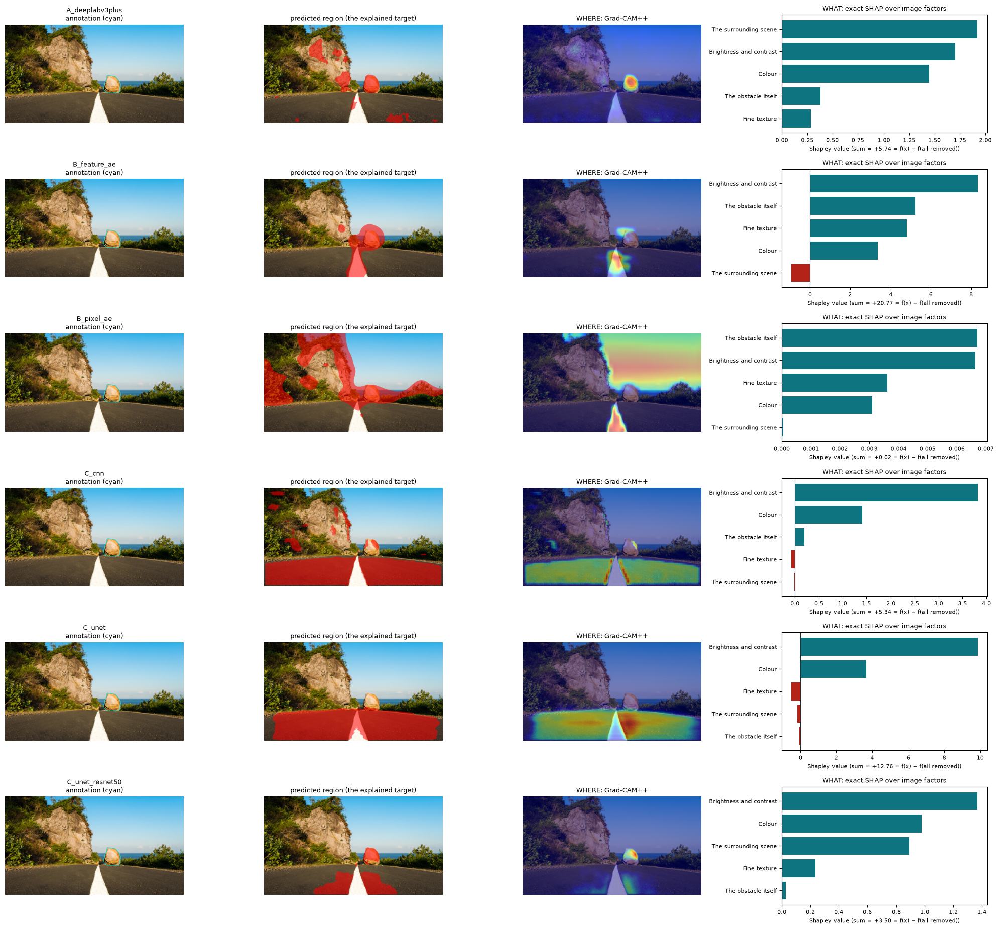

In [4]:
board(FAILURE, "6_02_xai_board_failure.png")

### 3. What each model relies on, over the whole validation split
The Shapley values of one image can depend on that image. Here the "what" is computed for every model on all nine validation photographs, and each factor is reported as its **share of the total attribution** (|φ| divided by the sum of |φ| over the five factors), which removes the different units of logits and reconstruction errors and makes the models comparable. The sign column says whether the factor mostly raises or lowers the score.

In [5]:
rows = []
for name, p in predictors.items():
    for idx in range(len(x_val)):
        region, _ = xai.explanation_region(p, x_val[idx])
        what = (
            pairs[(name, idx)]["what"]
            if (name, idx) in pairs
            else xai.factor_shapley(xai.target_score_fn(p, region), x_val[idx], region)
        )
        total = sum(abs(v) for v in what["phi"].values()) or 1.0
        for factor, value in what["phi"].items():
            rows.append({"model": name, "frame": val_frames[idx], "factor": factor, "phi": value,
                         "share": abs(value) / total, "gap": what["efficiency_gap"]})
shap_df = pd.DataFrame(rows)
shares = shap_df.pivot_table(index="model", columns="factor", values="share", aggfunc="mean")[list(FACTORS)]
signs = shap_df.assign(pos=shap_df["phi"] > 0).pivot_table(
    index="model", columns="factor", values="pos", aggfunc="mean"
)[list(FACTORS)]
summary = shares.rename(columns=LABELS).round(2)
summary["relies most on"] = shares.idxmax(axis=1).map(LABELS)
summary

factor,Colour,Fine texture,Brightness and contrast,The obstacle itself,The surrounding scene,relies most on
model,,,,,,
A_deeplabv3plus,0.14,0.05,0.30,0.20,0.31,The surrounding scene
B_feature_ae,0.12,0.24,0.37,0.22,0.06,Brightness and contrast
B_pixel_ae,0.07,0.20,0.34,0.38,0.00,The obstacle itself
C_cnn,0.18,0.02,0.63,0.17,0.01,Brightness and contrast
C_unet,0.19,0.05,0.54,0.17,0.05,Brightness and contrast
C_unet_resnet50,0.15,0.14,0.39,0.22,0.11,Brightness and contrast


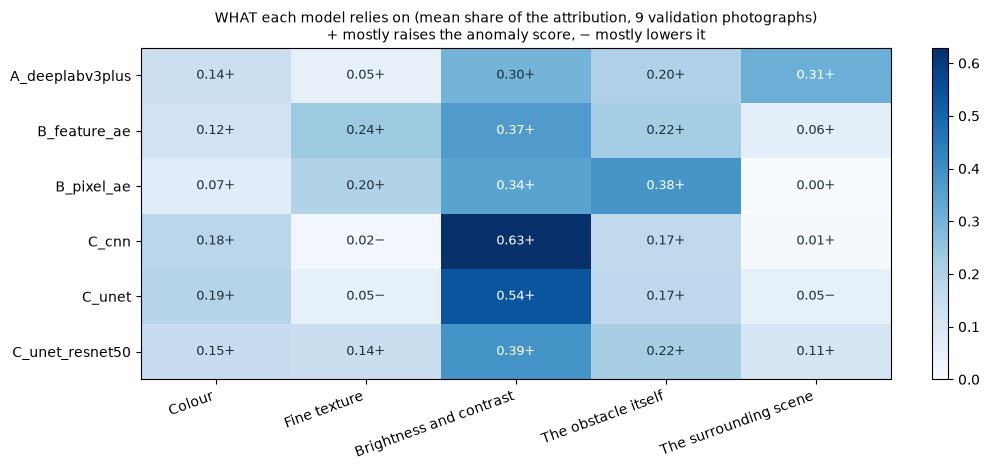

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8), tight_layout=True)
im = ax.imshow(shares.values, cmap="Blues", vmin=0, vmax=max(0.5, float(shares.values.max())), aspect="auto")
ax.set_xticks(range(len(FACTORS)), [LABELS[f] for f in FACTORS], rotation=20, ha="right")
ax.set_yticks(range(len(shares)), shares.index)
for i in range(shares.shape[0]):
    for j in range(shares.shape[1]):
        sign = "+" if signs.values[i, j] >= 0.5 else "−"
        ax.text(j, i, f"{shares.values[i, j]:.2f}{sign}", ha="center", va="center", fontsize=9,
                color="white" if shares.values[i, j] > 0.3 else "#1f3038")
ax.set_title(
    "WHAT each model relies on (mean share of the attribution, 9 validation photographs)\n"
    "+ mostly raises the anomaly score, − mostly lowers it",
    fontsize=10,
)
fig.colorbar(im, ax=ax, fraction=0.03)
plt.savefig(FIG_DIR / "6_03_shap_factor_shares.png", dpi=70)
plt.show()

### 4. Segmentation models: which layer supports the prediction?
Grad-CAM++ for the last decoder layer and, for DeepLabV3+, each ASPP branch, on the success case and the same predicted region. Each map is normalised by its own maximum, so the colours compare where a layer looks, not how much it contributes.

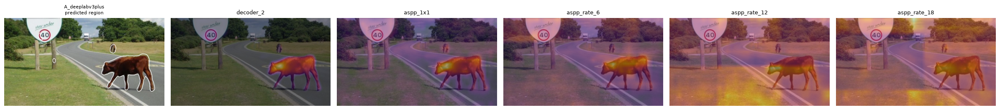

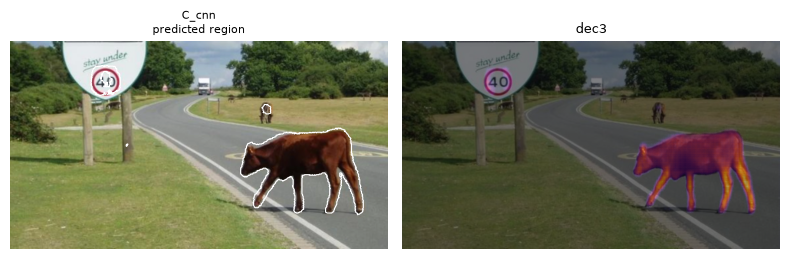

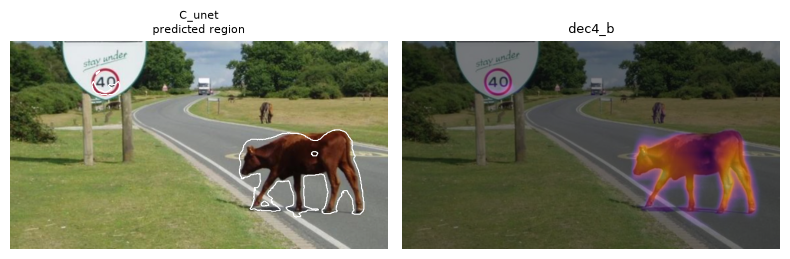

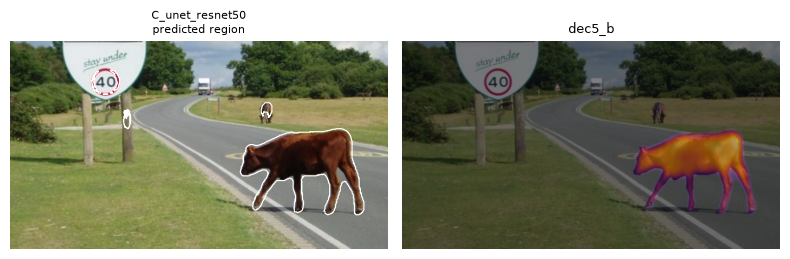

In [7]:
SEG_LAYERS = ["aspp_1x1", "aspp_rate_6", "aspp_rate_12", "aspp_rate_18"]
for name, p in predictors.items():
    if p.model_type != "segmentation":
        continue
    region = pairs[(name, SUCCESS)]["region"]
    names = {layer.name for layer in p.model.layers}
    layers = [xai.default_segmentation_layer(p.model)] + [
        layer_name for layer_name in SEG_LAYERS if layer_name in names
    ]
    fig, ax = plt.subplots(1, len(layers) + 1, figsize=(4 * (len(layers) + 1), 3), tight_layout=True)
    ax[0].imshow(x_val[SUCCESS])
    ax[0].contour(region.astype(float), levels=[0.5], colors="white", linewidths=0.8)
    ax[0].set_title(f"{name}\npredicted region", fontsize=8)
    for a, layer in zip(ax[1:], layers, strict=True):
        cam, raw_max = xai.grad_cam(p.model, x_val[SUCCESS], layer, xai.logit_target(region),
                                    output_name="anomaly_logits", method="gradcam++")
        a.imshow(x_val[SUCCESS])
        a.imshow(cam, cmap="inferno", alpha=0.5, vmin=0, vmax=1)
        a.set_title(layer + (" (zero map)" if raw_max == 0 else ""), fontsize=9)
    for a in ax:
        a.axis("off")
    plt.savefig(FIG_DIR / f"6_04_layers_{name}.png", dpi=60)
    plt.show()

### 5. Is the "where" faithful? Deletion and insertion, Grad-CAM vs Grad-CAM++
For the success case, 32×32 blocks are ranked by the map. **Deletion** replaces the top blocks with a blurred copy of the image; **insertion** restores them on the blurred copy. The tracked value is the same target as above. A faithful map makes deletion fall and insertion rise **faster than random orders** (3 seeds): a lower deletion area and a higher insertion area than random.

In [8]:
faith = []
for name, p in predictors.items():
    region = pairs[(name, SUCCESS)]["region"]
    score = xai.target_score_fn(p, region)
    for method in ("gradcam", "gradcam++"):
        cam, _ = xai.where_map(p, x_val[SUCCESS], region, method)
        r = xai.deletion_insertion(score, x_val[SUCCESS], cam, block=32)
        randoms = [r[k] for k in r if k.startswith("random")]
        rd, ri = np.mean([x["deletion_auc"] for x in randoms]), np.mean([x["insertion_auc"] for x in randoms])
        faith.append(
            {
                "model": name,
                "map": method,
                "deletion (map)": r["attribution"]["deletion_auc"],
                "deletion (random)": rd,
                "insertion (map)": r["attribution"]["insertion_auc"],
                "insertion (random)": ri,
                "beats random on deletion": r["attribution"]["deletion_auc"] < rd,
                "beats random on insertion": r["attribution"]["insertion_auc"] > ri,
            }
        )
faith_df = pd.DataFrame(faith)
faith_df.round(3)

,model,map,deletion (map),deletion (random),insertion (map),insertion (random),beats random on deletion,beats random on insertion
0,A_deeplabv3plus,gradcam,4.152,4.946,7.013,4.898,True,True
1,A_deeplabv3plus,gradcam++,4.711,4.946,6.674,4.898,True,True
2,B_feature_ae,gradcam,65.519,31.262,12.170,30.727,False,False
3,B_feature_ae,gradcam++,29.905,31.262,32.107,30.727,True,True
4,B_pixel_ae,gradcam,0.008,0.011,0.012,0.010,True,True
5,B_pixel_ae,gradcam++,0.006,0.011,0.014,0.010,True,True
6,C_cnn,gradcam,0.721,1.382,1.883,1.292,True,True
7,C_cnn,gradcam++,0.712,1.382,1.881,1.292,True,True
8,C_unet,gradcam,10.934,10.751,10.336,10.526,False,False
9,C_unet,gradcam++,10.967,10.751,10.290,10.526,False,False


### 6. Is the "what" exact? The efficiency identity
Because every coalition of factors is evaluated, the Shapley values must add up to f(x) − f(all factors removed) for every model and every image. The largest gap over the 54 explanations of section 3 is printed; anything above float error would mean a bug.

In [9]:
print(
    f"largest efficiency gap over {shap_df[['model', 'frame']].drop_duplicates().shape[0]} explanations: "
    f"{shap_df['gap'].max():.2e}"
)
assert shap_df["gap"].max() < 1e-6

largest efficiency gap over 54 explanations: 1.42e-14


### 7. Save the summary
The factor shares, the faithfulness table and the plain-language reading of each model are written to `reports/results/xai_summary.json`, which the landing page and the report quote.

In [10]:
sentences = {name: xai.describe_what(pairs[(name, SUCCESS)]["what"], name) for name in predictors}
payload = {
    "cases": {"success": val_frames[SUCCESS], "failure": val_frames[FAILURE]},
    "factors": {f: {"label": LABELS[f], "removal": xai.FACTOR_REMOVAL[f]} for f in FACTORS},
    "shares": shares.round(4).to_dict(orient="index"),
    "positive_fraction": signs.round(4).to_dict(orient="index"),
    "relies_most_on": shares.idxmax(axis=1).to_dict(),
    "success_case_sentences": sentences,
    "faithfulness": faith_df.round(4).to_dict(orient="records"),
    "efficiency_gap_max": float(shap_df["gap"].max()),
}
(RESULTS_DIR / "xai_summary.json").write_text(json.dumps(payload, indent=2, default=float), encoding="utf-8")
for s in sentences.values():
    print("-", s)

- A_deeplabv3plus relies most on the surrounding scene, which raises its anomaly score by 2.96 (30 % of the total attribution), then on brightness and contrast (+2.70).
- B_feature_ae relies most on brightness and contrast, which raises its anomaly score by 22.7 (30 % of the total attribution), then on the obstacle itself (+19.0).
- B_pixel_ae relies most on the obstacle itself, which raises its anomaly score by 0.00694 (39 % of the total attribution), then on brightness and contrast (+0.00616).
- C_cnn relies most on brightness and contrast, which raises its anomaly score by 3.43 (53 % of the total attribution), then on the obstacle itself (+1.48).
- C_unet relies most on brightness and contrast, which raises its anomaly score by 7.09 (45 % of the total attribution), then on colour (+4.85).
- C_unet_resnet50 relies most on brightness and contrast, which raises its anomaly score by 4.33 (37 % of the total attribution), then on the obstacle itself (+3.26).


### 8. Reading the explanations

**Where (Grad-CAM family).**
- On the success case, the maps of DeepLabV3+, the CNN and both U-Nets sit on the cow; the pixel autoencoder's map lands on the sign and the road markings, the high-contrast textures it reconstructs badly, which matches its many false alarms.
- **Grad-CAM++ is the more faithful "where".** Under the deletion / insertion test it beats random orders for five of the six models on both curves. For the feature autoencoder it turns a failing map (plain Grad-CAM: deletion area 65.5 vs 31.3 random, insertion 12.2 vs 30.7) into a passing one (29.9 vs 31.3 and 32.1 vs 30.7). A likely reason: Grad-CAM weights each channel by its mean gradient, and on this model's error map positive and negative gradients can cancel; Grad-CAM++ weights only the positive gradients, pixel by pixel. Grad-CAM++ is therefore the default in the demo and the API.
- The U-Net trained from scratch is the exception: neither method beats random (10.97 vs 10.75 and 10.29 vs 10.53). A likely reason: its evidence is spread over the scene, so no ranking of a few blocks matters more than a random one.

**What (exact SHAP over image factors).** Over the nine validation photographs (section 3):
- **Brightness and contrast** is the largest single factor for four models (from 37 % of the attribution for the feature autoencoder to 63 % for the CNN) and about 30 % or more for every model (just under 30 % for DeepLabV3+); for every model it raises the score on all nine photographs, so flattening the contrast always lowers it. The obstacles of RoadAnomaly (animals, rocks, cones) mostly stand out by contrast against the road.
- **DeepLabV3+ is the only model that relies on the surrounding scene** (31 %, its largest factor): its wide atrous pyramid sees well beyond the obstacle and judges it in its context. A plausible link, not tested here: the same context use may explain some of its false alarms.
- **The pixel autoencoder relies on the obstacle itself** (38 %) and not at all on the scene (0 %), consistent with a model trained on 64-px tiles, whose view of the image is local. The feature autoencoder spreads its attribution over contrast, the obstacle and texture (24 %), the texture weight reflecting its VGG features.
- The supervised models from scratch (CNN, U-Net) depend most on contrast and least on texture (2–5 %); the pretrained U-Net ResNet50 is more balanced (texture 14 %, scene 11 %), closer to how the ImageNet encoders see.
- The Shapley values are exact: the efficiency gap stays below 1e-13 over the 54 explanations (float rounding; section 6 prints the exact value).

**Limits of these explanations.** The factors are removed by chosen transforms (a different blur or contrast level changes the values; the transforms are stated, so the result can be reproduced and challenged). Removing a factor can produce images unlike the training data; Shapley values average over all such combinations but do not remove that effect. Nine validation photographs and one success / failure pair are small samples. These analyses describe the models; none of them was used to choose a model or a threshold.


# After the study: deployment

The six models saved in `models/` are served through the same `Predictor` as in phases 5 and 6:
- **API**: `mise run api`, FastAPI on port 8000 (`/health`, `/models`, `/predict`, `/explain`);
- **Demo**: `mise run app`, Streamlit on port 8501 (Detect, Explain, Compare, Test results, Method);
- **Landing page**: `mise run landing`, the Astro page that tells this study, also online at https://roadanomaly-landing.vercel.app;
- **Docker**: `mise run docker:up` starts the three together.

The README has the setup, the GPU notes and the architecture diagram.